# Predictive modeling

## EDA

### Trajectory clustering based on custom feature extraction

### logic

### 1. Feature extraction - full observation length 

Fetching raw longitudinal measurements at the patient_id level...
Initial data: 14515 patient_ids, 396210 measurements.
After dropping missing weight/fat/muscle entries: 14438 patient_ids, 360306 measurements.
Dropped 5074 same-day duplicate measurements (kept highest weight). Remaining: 14438 patient_ids, 355232 measurements.
Processing 14438 patient_id units for feature extraction...

--- Feature Extraction Summary ---
Retained: 11461 patient_id units for clustering.
Excluded: 2977 patient_id units (due to early attrition: < 30 days follow-up OR < 3 total measurements).


,patient_id,pct_max_loss,pct_regain,early_wl_speed,time_to_nadir_ratio,trajectory_volatility,lean_loss_coeff,muscle_fat_corr,observation_duration,observation_gap_ratio,adj_pct_max_loss,adj_pct_regain
0,9896A74CEB969,-5.373832,0.000000,-0.001906,1.000000,5.167807e-16,0.000000,-0.995195,829,0.655006,12.675175,-64.590492
1,9896AA4CEB969,-13.062569,9.243697,-0.233123,0.970588,4.848043e-01,0.000000,-0.265810,102,0.049020,-0.766334,-2.037250
2,9896EA4CEB969,-16.047144,0.000000,-0.232549,1.000000,4.352723e-01,0.000000,-0.776959,188,0.276596,-3.070389,-17.587166
3,9896F14CEB969,-12.695109,51.639344,-0.254033,0.324675,5.535715e-01,0.000000,0.145084,154,0.136364,0.012603,36.545335
4,9896F54CEB969,-7.470511,0.000000,-0.208655,1.000000,4.627368e-01,0.191232,0.347415,32,0.125000,4.271812,-6.147979


--- Missing Values Count per Feature ---
pct_max_loss             0
pct_regain               0
early_wl_speed           0
time_to_nadir_ratio      0
trajectory_volatility    0
lean_loss_coeff          0
muscle_fat_corr          0
observation_duration     0
observation_gap_ratio    0
adj_pct_max_loss         0
adj_pct_regain           0
dtype: int64
----------------------------------------


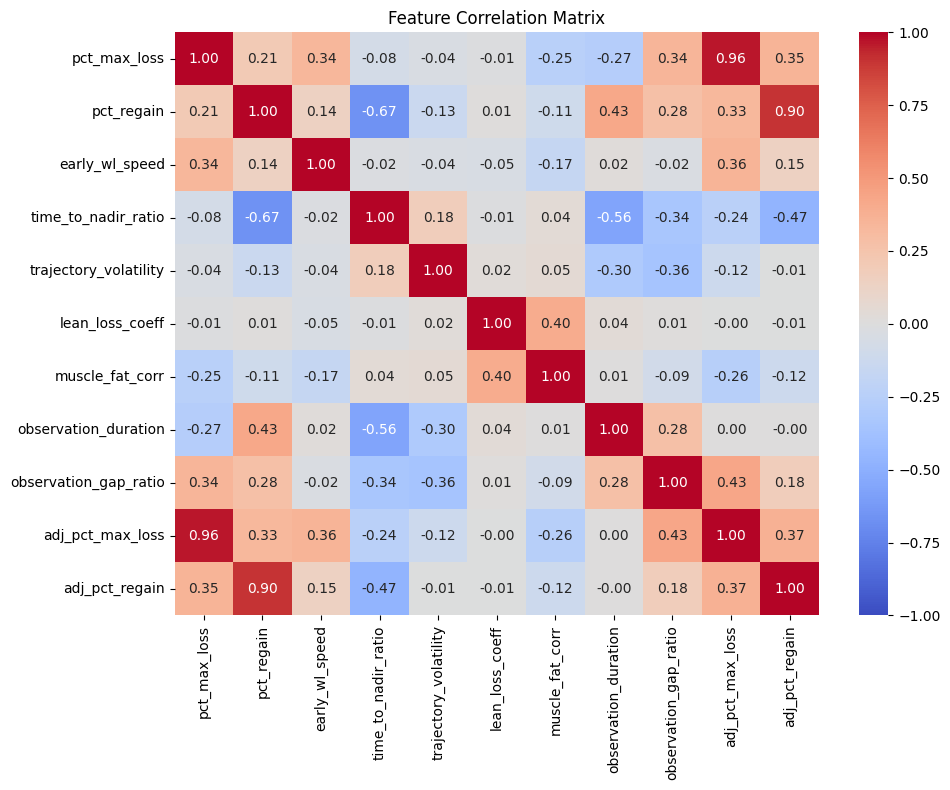

--- Highly Correlated Pairs (|r| > 0.7) ---
pct_max_loss <--> adj_pct_max_loss: 0.96
pct_regain <--> adj_pct_regain: 0.90


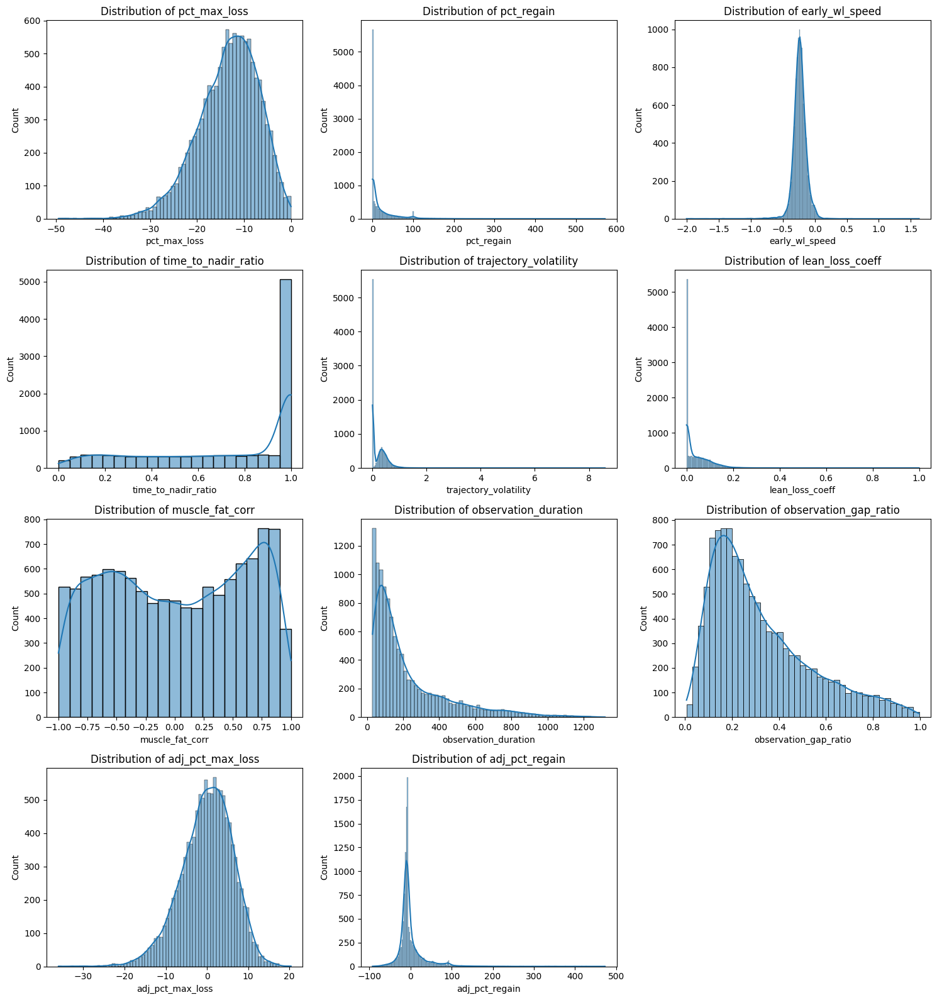

\n--- Descriptive Statistics ---


,count,mean,std,min,25%,50%,75%,max
pct_max_loss,11461.0,-1.327903e+01,6.469229,-49.517241,-1.735632e+01,-12.642741,-8.598726,0.000000
pct_regain,11461.0,2.038826e+01,37.502305,0.000000,0.000000e+00,3.030303,25.675676,571.428571
early_wl_speed,11461.0,-2.336669e-01,0.110080,-2.004099,-2.874133e-01,-0.234181,-0.178565,1.629831
time_to_nadir_ratio,11461.0,7.136700e-01,0.326115,0.000000,4.375000e-01,0.860000,1.000000,1.000000
trajectory_volatility,11461.0,2.296825e-01,0.312256,0.000000,3.251267e-15,0.144358,0.399707,8.594280
lean_loss_coeff,11461.0,4.341997e-02,0.074837,0.000000,0.000000e+00,0.012568,0.068608,1.000000
muscle_fat_corr,11461.0,1.826110e-02,0.590039,-1.000000,-5.106775e-01,0.021431,0.567920,0.999998
observation_duration,11461.0,2.261995e+02,218.552282,30.000000,7.700000e+01,140.000000,296.000000,1319.000000
observation_gap_ratio,11461.0,3.199751e-01,0.210946,0.007353,1.595745e-01,0.259259,0.433272,0.995822
adj_pct_max_loss,11461.0,-1.864857e-15,6.233784,-36.032842,-3.888011e+00,0.440854,4.354910,20.391264


In [21]:
# -------------------------------------------------------------------------
# Feature-Based Clustering: 1. Feature Extraction & EDA
# -------------------------------------------------------------------------
# This step extracts 10 pre-defined kinetic, metabolic, and behavioral features
# from the raw weight-loss trajectories. 
# -------------------------------------------------------------------------
import os
import sys
import pandas as pd

# Import our updated feature extraction module
from feature_extraction import extract_features, eda_features

DB_PATH = "../dbs/pnk_db2_filtered.sqlite"
ID_COL = "patient_id"  # 'medical_record_id' for episode-level and 'patient_id' for whole treatment course analysis

# 1. Extract features
df_features, df_excluded = extract_features(db_path=DB_PATH, id_col=ID_COL)

# Check first few rows
display(df_features.head())

# 2. Perform Exploratory Data Analysis (EDA) on the features
eda_features(df_features, id_col=ID_COL)


### 2. Model Selection, Evaluation, and Visualization - full observation length 

This section prepares the data according to distinct clinical feature blocks (Kinetic, Metabolic, Behavioral, Holistic). We scale the features robustly (using median/IQR) to manage outliers. We then fit candidate clustering models (e.g., GMM) and evaluate both their internal validity (Silhouette, Davies-Bouldin, BIC) and their predictive clinical utility (Multinomial Logistic Regression against age, sex, and baseline BMI). Finally, we visualize the separation (PCA/UMAP) and the actual weight trajectories of the resulting clusters.

Notes: as UMAP and t-SNE plots show, clusters are far from spherical. Prioritize GMM and HDBSCAN that do not assume as such. 
Regarding features, prefer the Holistic set, even though clustering evaluation scores penalize that due to the curse of dimensionality (lower dimensional spaces are better separated and score better)

#### test grid

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
                 COMPREHENSIVE GRID SEARCH                      
Running grid search across 1 blocks and 6 models...
\n--- Top 5 Clustering Candidate Setups (by Silhouette) ---


,Block,Model,Param (k/size),Clusters Found,Noise Ratio,Silhouette,Davies-Bouldin,BIC
12,Holistic adjusted,KMEANS,2,2,0.0,0.261518,1.825541,NaN
18,Holistic adjusted,SPECTRAL,2,2,0.0,0.259004,1.903292,NaN
6,Holistic adjusted,WARD,2,2,0.0,0.248748,1.924746,NaN
19,Holistic adjusted,SPECTRAL,3,3,0.0,0.239275,1.520598,NaN
0,Holistic adjusted,GMM,2,2,0.0,0.187680,2.200099,249852.88085


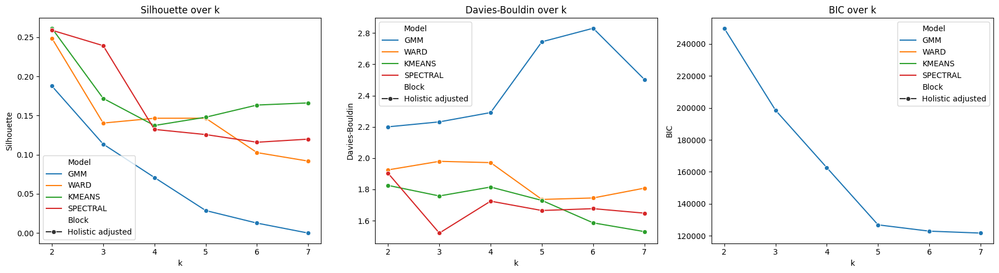


      DEEP CHARACTERIZATION: KMEANS on Holistic adjusted (2)

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
adj_pct_max_loss         1.000087
adj_pct_regain           1.000087
early_wl_speed           1.000087
time_to_nadir_ratio      1.000087
trajectory_volatility    1.000087
lean_loss_coeff          1.000087
muscle_fat_corr          1.000087
observation_duration     1.000087
observation_gap_ratio    1.000087

Internal Validity Metrics:
  - Silhouette: 0.2615
  - Davies-Bouldin: 1.8255
  - BIC: N/A

--- 2. DIMENSIONALITY REDUCTION ---


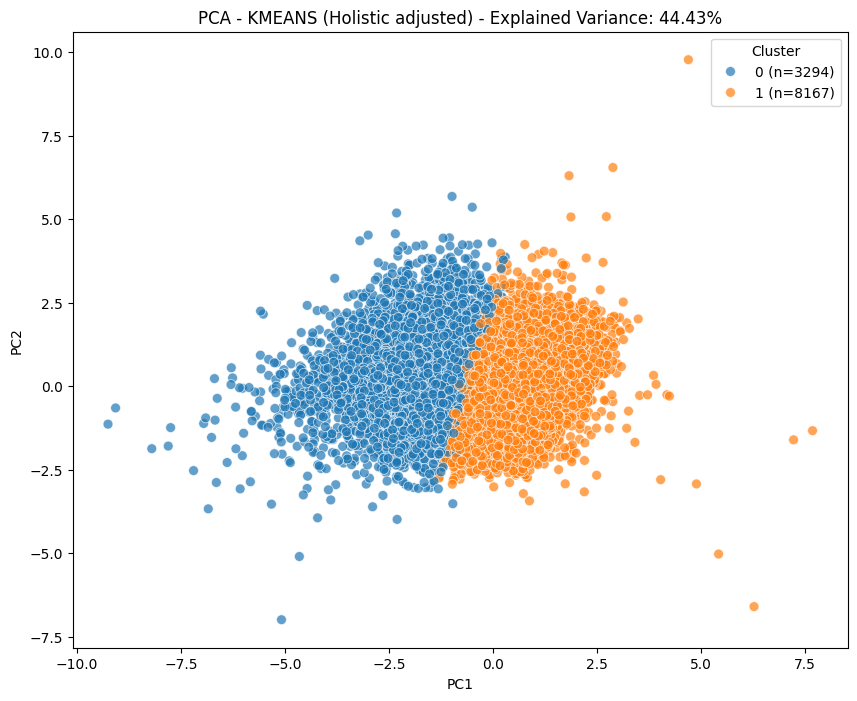

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
adj_pct_max_loss,-0.416093,-0.318657
adj_pct_regain,-0.361512,-0.165360
early_wl_speed,-0.179790,-0.383981
time_to_nadir_ratio,0.478402,-0.244604
trajectory_volatility,0.292397,-0.216567
lean_loss_coeff,0.053564,0.404429
muscle_fat_corr,0.196549,0.505894
observation_duration,-0.339378,0.424103
observation_gap_ratio,-0.439100,0.132609


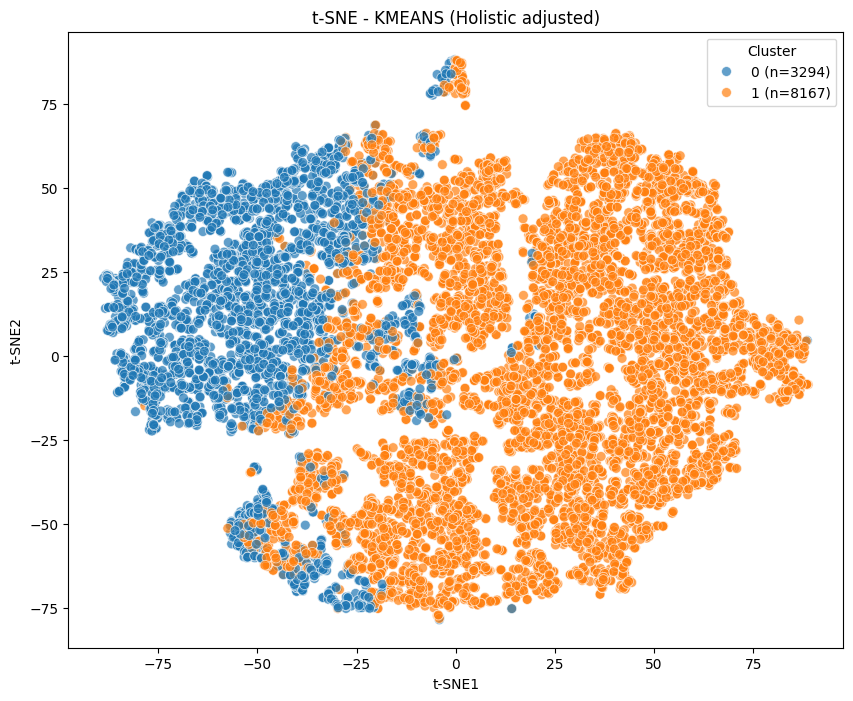

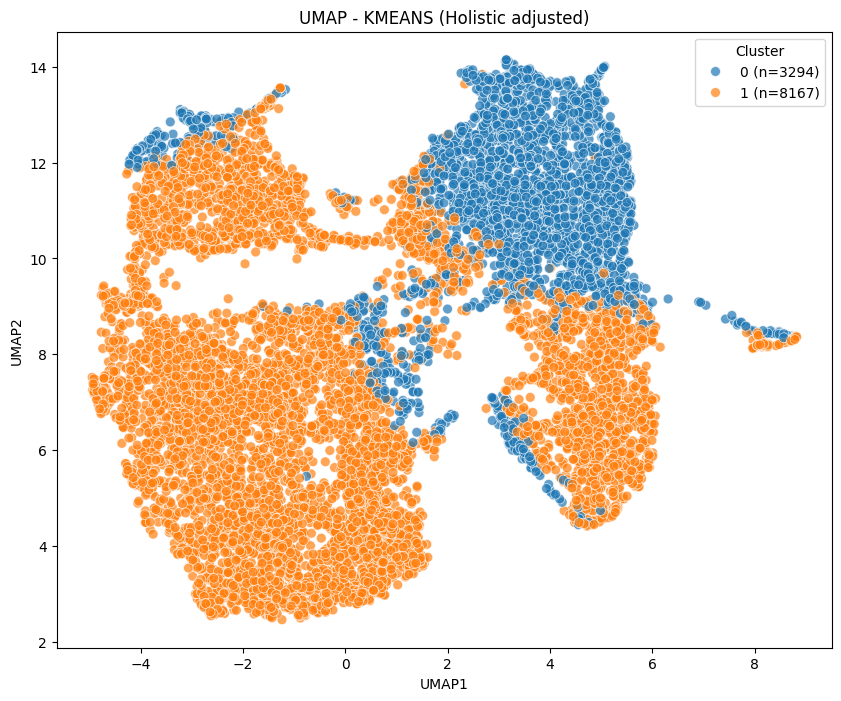


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


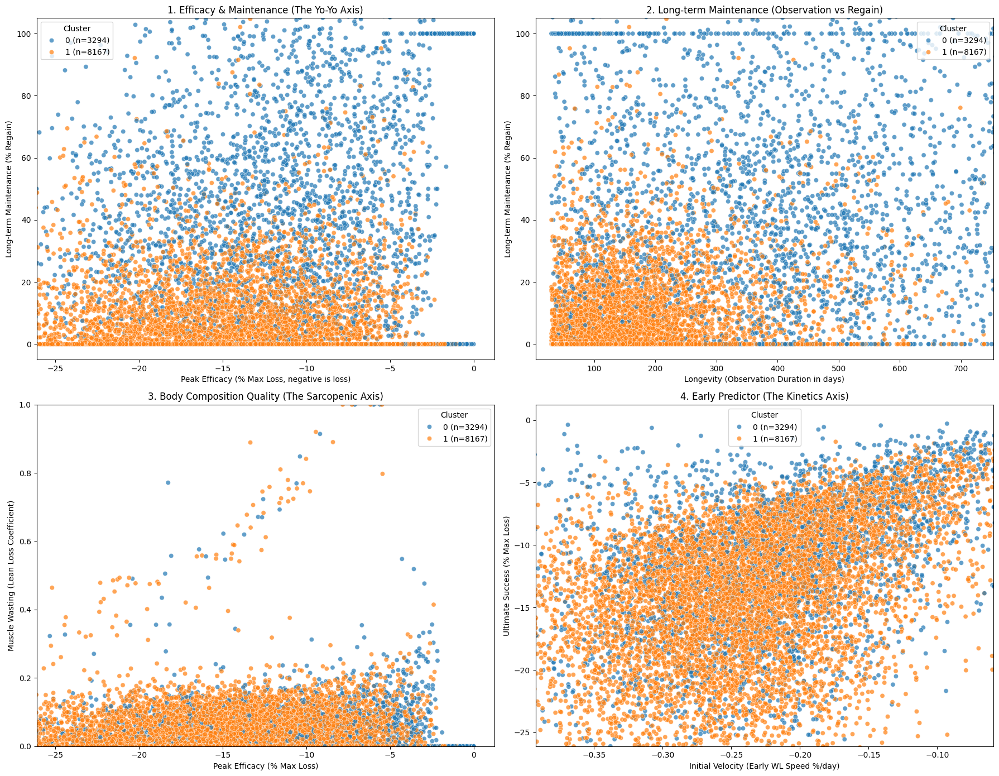


--- 4. TRAJECTORY HOMOGENEITY SAMPLES ---


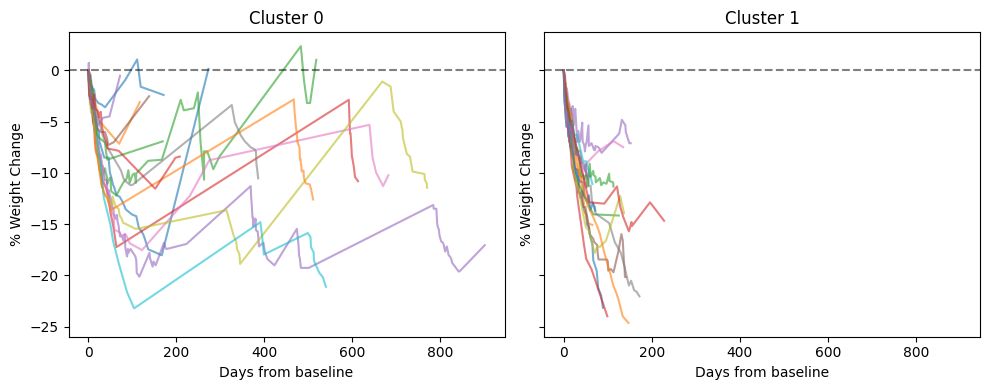

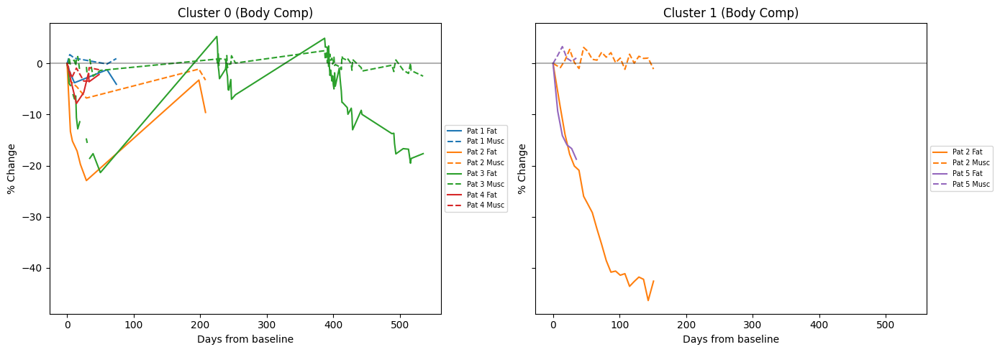


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...

--- CLUSTER SIZES ---
cluster_id
0    3294
1    8167
---------------------

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                11461
Model:                        MNLogit   Df Residuals:                    11457
Method:                           MLE   Df Model:                            3
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:               0.0008949
Time:                        09:26:07   Log-Likelihood:                -6868.3
converged:                       True   LL-Null:                       -6874.5
Covariance Type:            nonrobust   LLR p-value:                  0.006411
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.3933      0.20

,Variable,Cluster 0,Cluster 1,p_value
0,Cluster Size (N),3294,8167,N/A
1,age_when_creating_record,48.00 (41.00-54.00),47.00 (40.00-54.00),0.090
2,sex_f,79.8%,78.3%,0.134
3,height_m,1.65 (1.60-1.70),1.65 (1.60-1.71),0.420
4,wc_cm_confirm_time,100.00 (91.00-109.00),100.00 (92.00-110.00),0.285
5,nr_medical_records_patient,2.00 (1.00-3.00),1.00 (1.00-1.00),<0.001
6,dietitian_visits,4.00 (2.00-7.00),4.00 (2.00-7.00),0.438
7,womens_health_and_pregnancy,19.4%,28.3%,<0.001
8,mental_health,24.4%,24.0%,0.915
9,family_issues,5.8%,5.0%,0.568


In [6]:
# -------------------------------------------------------------------------
# Feature-Based Clustering: 2. Unified Grid Search & Characterization Pipeline
# -------------------------------------------------------------------------
import pandas as pd
from clustering_pipeline import run_clustering_pipeline
%load_ext autoreload
%autoreload 2

# --- CONFIGURATION ---
# To trigger a grid search, pass multiple elements in these lists or a range for K.
# To trigger a specific single run, pass exactly one element in each list.
BLOCKS = ['Holistic adjusted'] # 'Kinetic', 'Metabolic', 'Behavioral', 'Physio', 'Holistic', 'Holistic adjusted'
MODELS = ['GMM', 'WARD', 'KMEANS', 'SPECTRAL', 'HDBSCAN', 'UMAP_HDBSCAN'] # 'GMM', 'WARD', 'KMEANS', 'SPECTRAL', 'HDBSCAN', 'UMAP_HDBSCAN'
K_RANGE = range(2, 8) # range(2, 8) - accepts integers as well
# ---------------------

run_clustering_pipeline(
    df_features=df_features, 
    db_path=DB_PATH,
    id_col=ID_COL,
    blocks=BLOCKS, 
    models=MODELS, 
    k_range=K_RANGE
)

#### SPECTRAL on RECORDS 

               SINGLE RUN: SPECTRAL on Holistic           

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max_loss             1.000076
pct_regain               1.000076
early_wl_speed           1.000076
time_to_nadir_ratio      1.000076
trajectory_volatility    1.000076
lean_loss_coeff          1.000076
muscle_fat_corr          1.000076
observation_duration     1.000076
longest_gap              1.000076

Internal Validity Metrics:
  - Silhouette: 0.3232
  - Davies-Bouldin: 1.3783
  - BIC: N/A

--- 2. DIMENSIONALITY REDUCTION ---


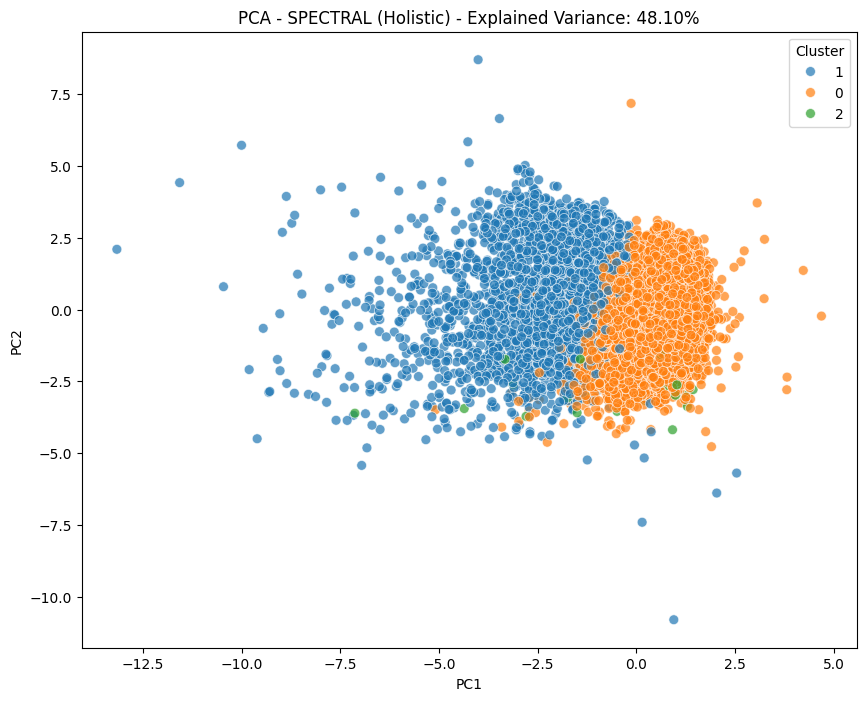

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,-0.036964,0.582153
pct_regain,-0.475925,0.231726
early_wl_speed,-0.109392,0.431183
time_to_nadir_ratio,0.518347,-0.101439
trajectory_volatility,0.197762,0.030647
lean_loss_coeff,-0.013173,-0.284573
muscle_fat_corr,0.019248,-0.438117
observation_duration,-0.461478,-0.338089
longest_gap,-0.488737,-0.151726


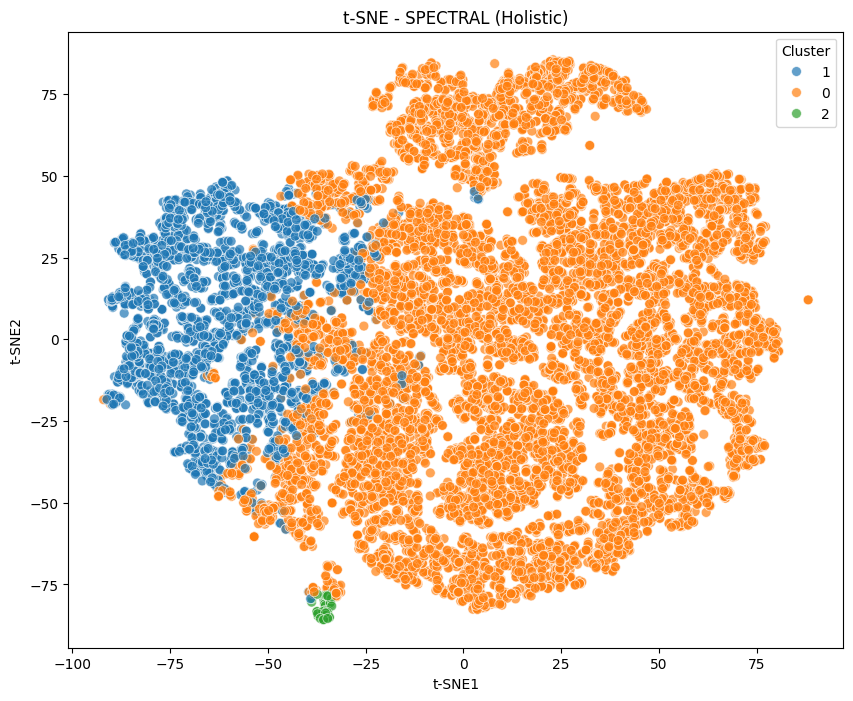

c:\Users\miksa.henkrich\OneDrive - IMDEANU\Escritorio\PNK\p4_dir\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


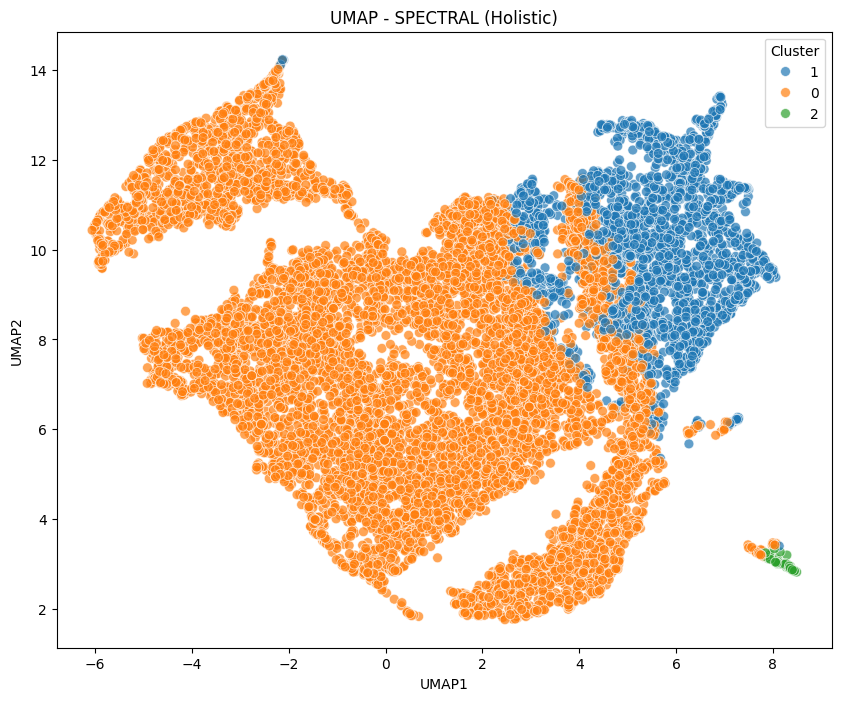


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


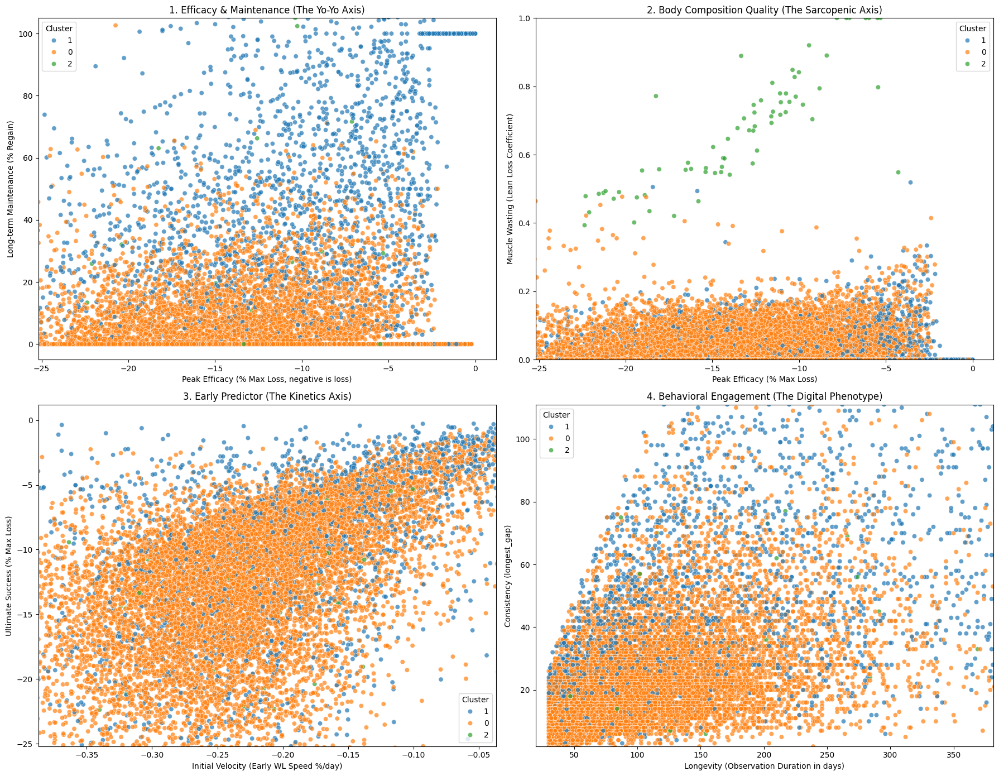


--- 4. TRAJECTORY HOMOGENEITY SAMPLES ---


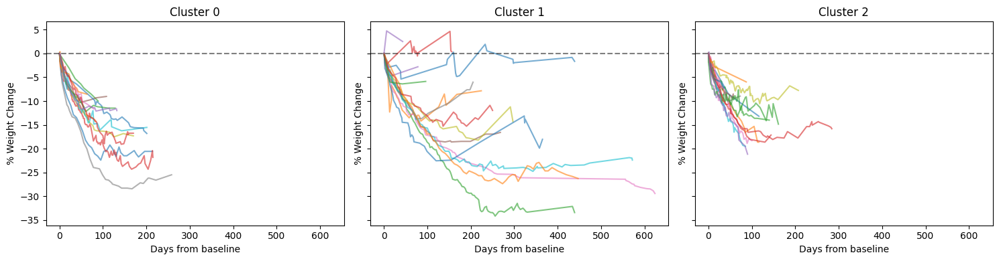


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...

--- CLUSTER SIZES ---


KeyError: 'Cluster'

In [2]:
# -------------------------------------------------------------------------
# Feature-Based Clustering: 2. Unified Grid Search & Characterization Pipeline
# -------------------------------------------------------------------------
import pandas as pd
from clustering_pipeline import run_clustering_pipeline

# --- CONFIGURATION ---
# To trigger a grid search, pass multiple elements in these lists or a range for K.
# To trigger a specific single run, pass exactly one element in each list.
BLOCKS = ['Holistic'] # 'Kinetic', 'Metabolic', 'Behavioral', 'Physio', 'Holistic'
MODELS = ['SPECTRAL'] # 'GMM', 'WARD', 'KMEANS', 'HDBSCAN' - 'CLARA' implementation eventually removed! 
K_RANGE = 3 # range(2, 8) - accepts integers as well
# ---------------------

run_clustering_pipeline(
    df_features=df_features, 
    db_path=DB_PATH,
    id_col=ID_COL,
    blocks=BLOCKS, 
    models=MODELS, 
    k_range=K_RANGE
)

#### SPECTRAL on PATIENTS 

               SINGLE RUN: SPECTRAL on Holistic adjusted           

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
adj_pct_max_loss         1.000087
adj_pct_regain           1.000087
early_wl_speed           1.000087
time_to_nadir_ratio      1.000087
trajectory_volatility    1.000087
lean_loss_coeff          1.000087
muscle_fat_corr          1.000087
observation_duration     1.000087
observation_gap_ratio    1.000087

Internal Validity Metrics:
  - Silhouette: 0.2393
  - Davies-Bouldin: 1.5206
  - BIC: N/A

--- 2. DIMENSIONALITY REDUCTION ---


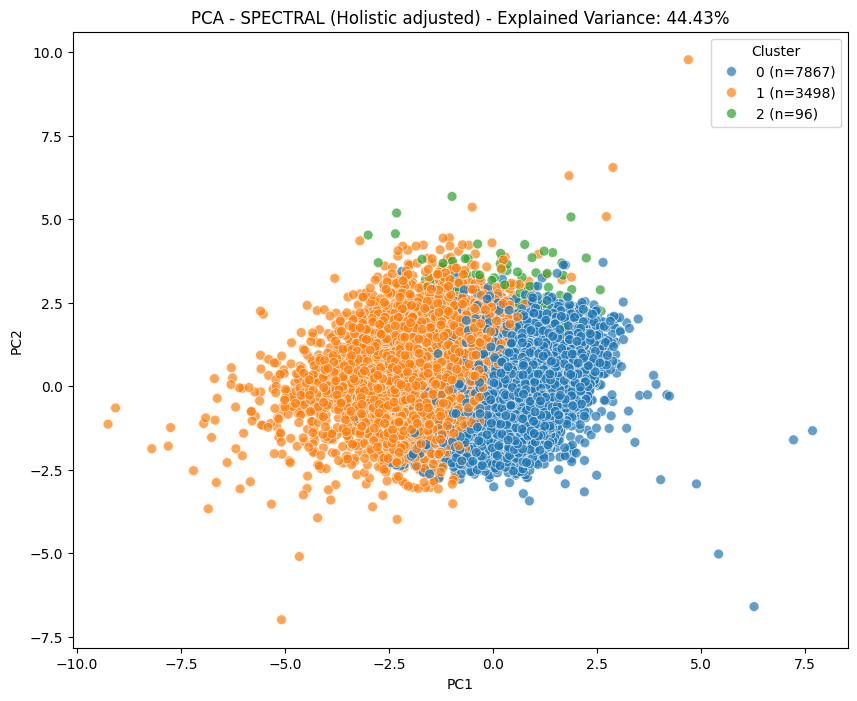

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
adj_pct_max_loss,-0.416093,-0.318657
adj_pct_regain,-0.361512,-0.165360
early_wl_speed,-0.179790,-0.383981
time_to_nadir_ratio,0.478402,-0.244604
trajectory_volatility,0.292397,-0.216567
lean_loss_coeff,0.053564,0.404429
muscle_fat_corr,0.196549,0.505894
observation_duration,-0.339378,0.424103
observation_gap_ratio,-0.439100,0.132609


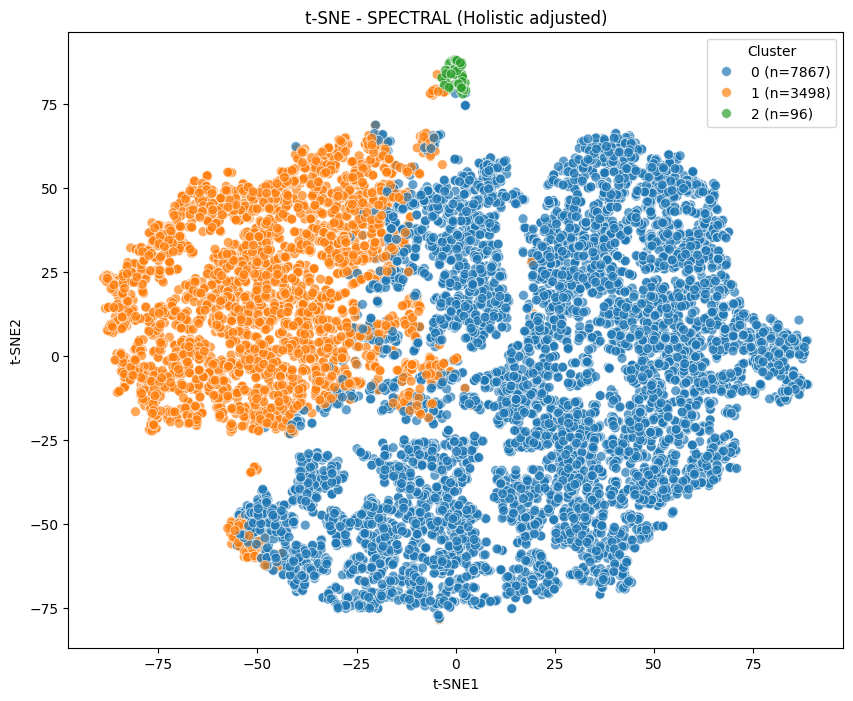

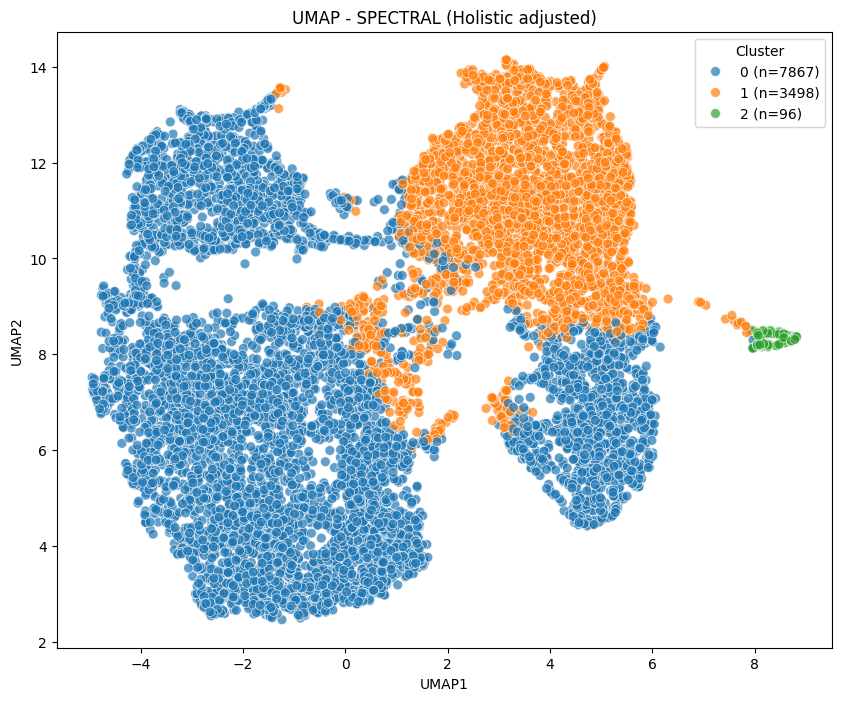


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


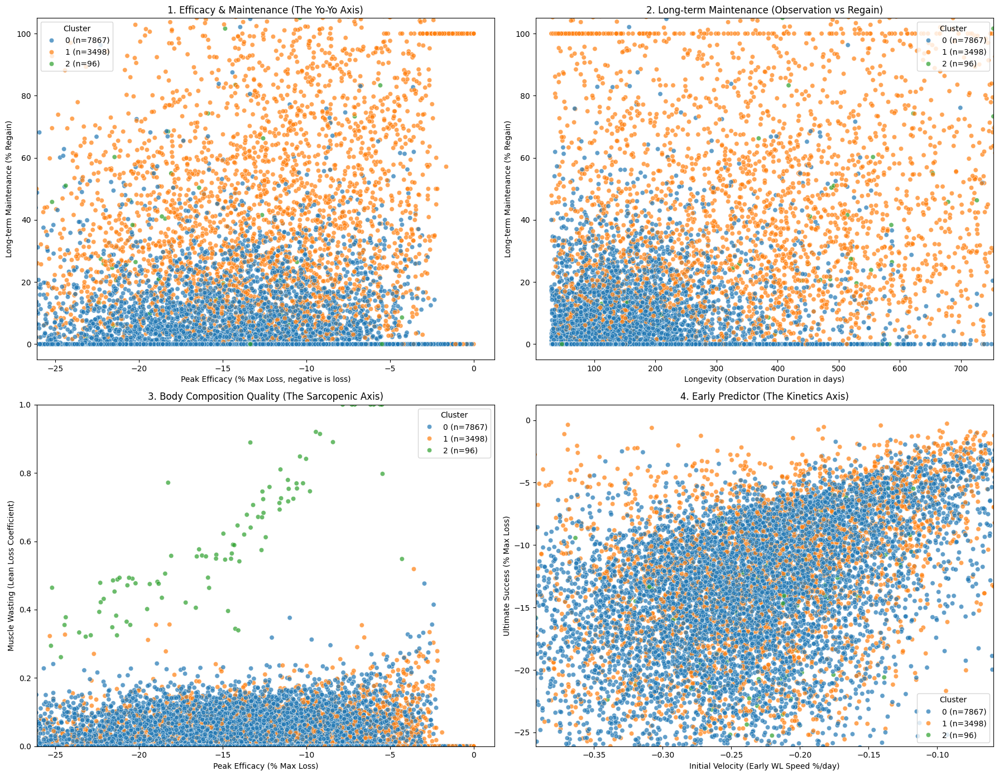


--- 4. TRAJECTORY HOMOGENEITY SAMPLES (GLOBAL) ---


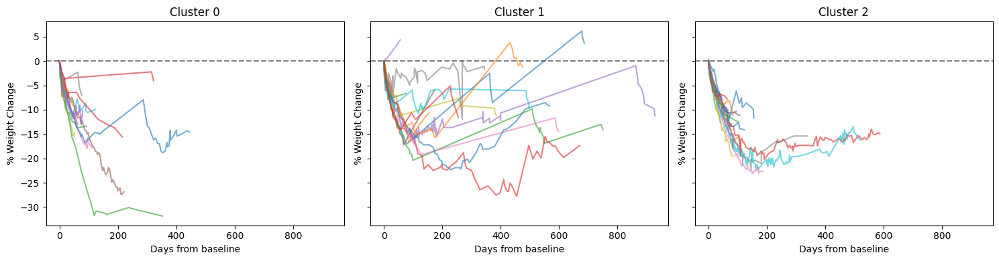

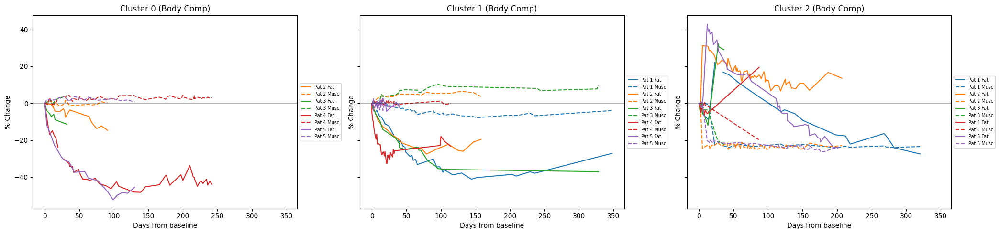


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...

--- CLUSTER SIZES ---
cluster_id
0    7867
1    3498
2      96
---------------------

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                11461
Model:                        MNLogit   Df Residuals:                    11453
Method:                           MLE   Df Model:                            6
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:                0.003729
Time:                        12:35:41   Log-Likelihood:                -7542.3
converged:                       True   LL-Null:                       -7570.5
Covariance Type:            nonrobust   LLR p-value:                 2.342e-10
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.4690

,Variable,Cluster 0.0,Cluster 1.0,Cluster 2.0,Dropout,p_value
0,Cluster Size (N),7867,3498,96,3054,N/A
1,age_when_creating_record,47.00 (40.00-54.00),48.00 (41.00-54.00),47.00 (39.00-53.00),46.00 (38.00-53.00),<0.001
2,sex_f,78.0%,79.8%,99.0%,81.5%,<0.001
3,height_m,1.65 (1.60-1.71),1.65 (1.60-1.70),1.63 (1.59-1.68),1.64 (1.60-1.70),<0.001
4,wc_cm_confirm_time,100.00 (92.00-110.00),100.00 (91.00-109.00),100.00 (93.00-103.00),100.00 (90.00-109.00),0.190
5,nr_medical_records_patient,1.00 (1.00-1.00),2.00 (1.00-3.00),1.00 (1.00-2.00),1.00 (1.00-1.00),<0.001
6,dietitian_visits,4.00 (2.00-6.00),5.00 (2.00-8.00),6.00 (3.75-10.00),2.00 (1.00-3.00),<0.001
7,womens_health_and_pregnancy,28.1%,20.3%,33.3%,31.8%,<0.001
8,mental_health,24.2%,24.3%,8.3%,23.8%,0.755
9,family_issues,5.3%,5.3%,0.0%,4.5%,0.832


In [ ]:
# -------------------------------------------------------------------------
# Feature-Based Clustering: 2. Unified Grid Search & Characterization Pipeline
# -------------------------------------------------------------------------
import pandas as pd
from clustering_pipeline import run_clustering_pipeline

# --- CONFIGURATION ---
# To trigger a grid search, pass multiple elements in these lists or a range for K.
# To trigger a specific single run, pass exactly one element in each list.
BLOCKS = ['Holistic adjusted'] # 'Kinetic', 'Metabolic', 'Behavioral', 'Physio', 'Holistic'
MODELS = ['SPECTRAL'] # 'GMM', 'WARD', 'KMEANS', 'HDBSCAN' - 'CLARA' implementation eventually removed! 
K_RANGE = 3 #range(2, 8) # range(2, 8) - accepts integers as well
# ---------------------

run_clustering_pipeline(
    df_features=df_features, 
    db_path=DB_PATH,
    id_col=ID_COL,
    blocks=BLOCKS, 
    models=MODELS, 
    k_range=K_RANGE
)

#### GMM with covar_type=diag on PATIENTS 

               SINGLE RUN: GMM on Physio           

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max_loss             1.000087
pct_regain               1.000087
early_wl_speed           1.000087
time_to_nadir_ratio      1.000087
trajectory_volatility    1.000087
lean_loss_coeff          1.000087
muscle_fat_corr          1.000087

Internal Validity Metrics:
  - Silhouette: 0.0500
  - Davies-Bouldin: 2.0296
  - BIC: 71011.7625

--- 2. DIMENSIONALITY REDUCTION ---


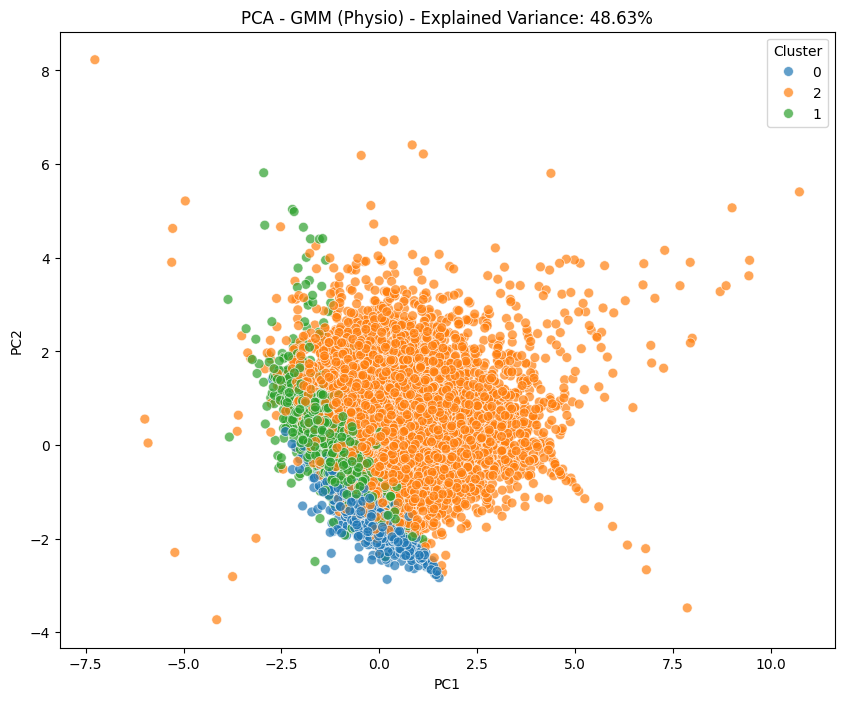

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,0.381717,-0.267213
pct_regain,0.564255,0.342831
early_wl_speed,0.314055,-0.294575
time_to_nadir_ratio,-0.502364,-0.439054
trajectory_volatility,-0.226430,-0.135503
lean_loss_coeff,-0.158664,0.487734
muscle_fat_corr,-0.329339,0.524667


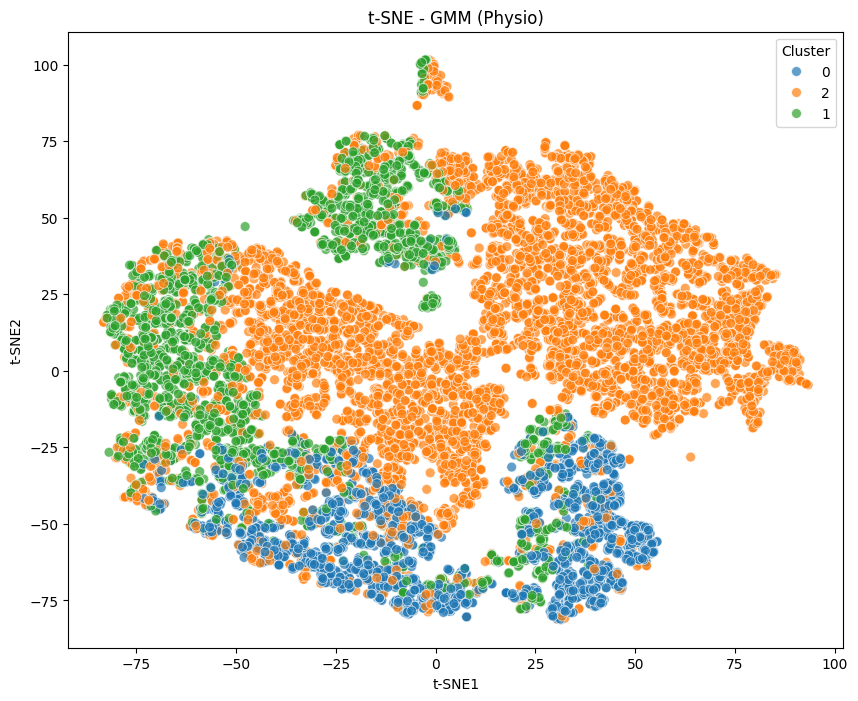

c:\Users\miksa.henkrich\OneDrive - IMDEANU\Escritorio\PNK\p4_dir\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


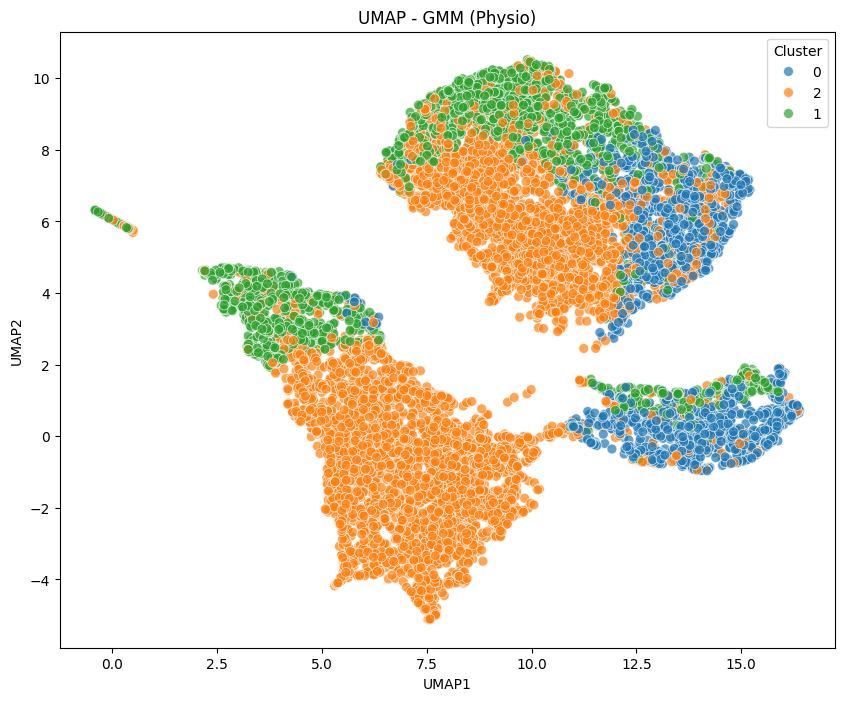


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


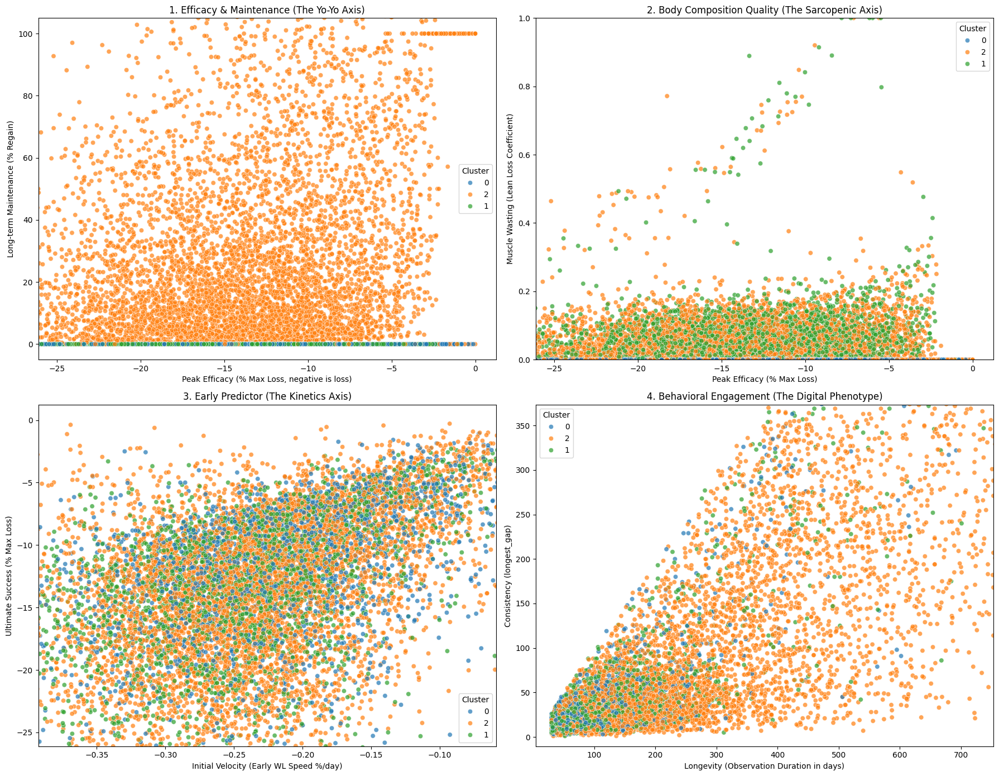


--- 4. TRAJECTORY HOMOGENEITY SAMPLES ---


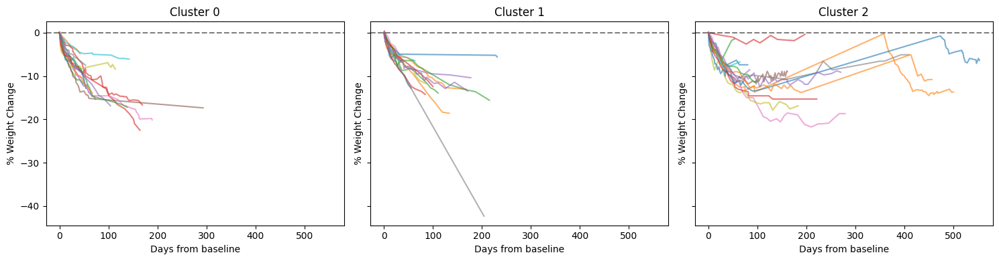


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...
                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                11461
Model:                        MNLogit   Df Residuals:                    11453
Method:                           MLE   Df Model:                            6
Date:                Tue, 29 Sep 2026   Pseudo R-squ.:                 0.06653
Time:                        15:18:23   Log-Likelihood:                -10368.
converged:                       True   LL-Null:                       -11107.
Covariance Type:            nonrobust   LLR p-value:                     0.000
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.7256      0.328     29.651      0.000       9.083      10.368
age           -0.0379      0.

In [12]:
# -------------------------------------------------------------------------
# Feature-Based Clustering: 2. Unified Grid Search & Characterization Pipeline
# -------------------------------------------------------------------------
import pandas as pd
from clustering_pipeline import run_clustering_pipeline

# --- CONFIGURATION ---
# To trigger a grid search, pass multiple elements in these lists or a range for K.
# To trigger a specific single run, pass exactly one element in each list.
BLOCKS = ['Physio'] # 'Kinetic', 'Metabolic', 'Behavioral', 'Physio', 'Holistic'
MODELS = ['GMM'] # 'GMM', 'WARD', 'KMEANS', 'HDBSCAN' - 'CLARA' implementation eventually removed! 
K_RANGE = 3 #range(2, 8) # range(2, 8) - accepts integers as well
# ---------------------

run_clustering_pipeline(
    df_features=df_features, 
    db_path=DB_PATH,
    id_col=ID_COL,
    blocks=BLOCKS, 
    models=MODELS, 
    k_range=K_RANGE
)

#### UMAP_HDBSCAN Physio on PATIENTS 

                 COMPREHENSIVE GRID SEARCH                      
Running grid search across 1 blocks and 1 models...
\n--- Top 5 Clustering Candidate Setups (by Silhouette) ---


,Block,Model,Param (k/size),Clusters Found,Noise Ratio,Silhouette,Davies-Bouldin,BIC
0,Physio,UMAP_HDBSCAN,size:200_samp:20,2,0.009423,0.116423,2.60749,NaN
1,Physio,UMAP_HDBSCAN,size:300_samp:30,2,0.009423,0.116423,2.60749,NaN
2,Physio,UMAP_HDBSCAN,size:400_samp:40,2,0.009423,0.116423,2.60749,NaN
3,Physio,UMAP_HDBSCAN,size:500_samp:50,2,0.009423,0.116423,2.60749,NaN
4,Physio,UMAP_HDBSCAN,size:600_samp:60,2,0.009423,0.116423,2.60749,NaN


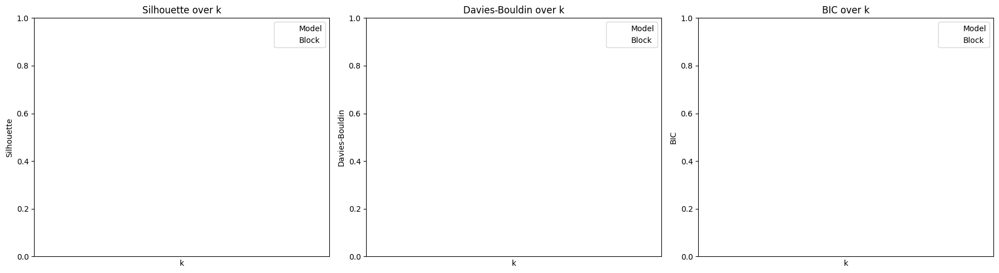


      DEEP CHARACTERIZATION: UMAP_HDBSCAN on Physio (size:200_samp:20)

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max_loss             1.000087
pct_regain               1.000087
early_wl_speed           1.000087
time_to_nadir_ratio      1.000087
trajectory_volatility    1.000087
lean_loss_coeff          1.000087
muscle_fat_corr          1.000087


c:\Users\miksa.henkrich\OneDrive - IMDEANU\Escritorio\PNK\p4_dir\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



Internal Validity Metrics:
  - Silhouette: 0.1164
  - Davies-Bouldin: 2.6075
  - BIC: N/A

--- 2. DIMENSIONALITY REDUCTION ---


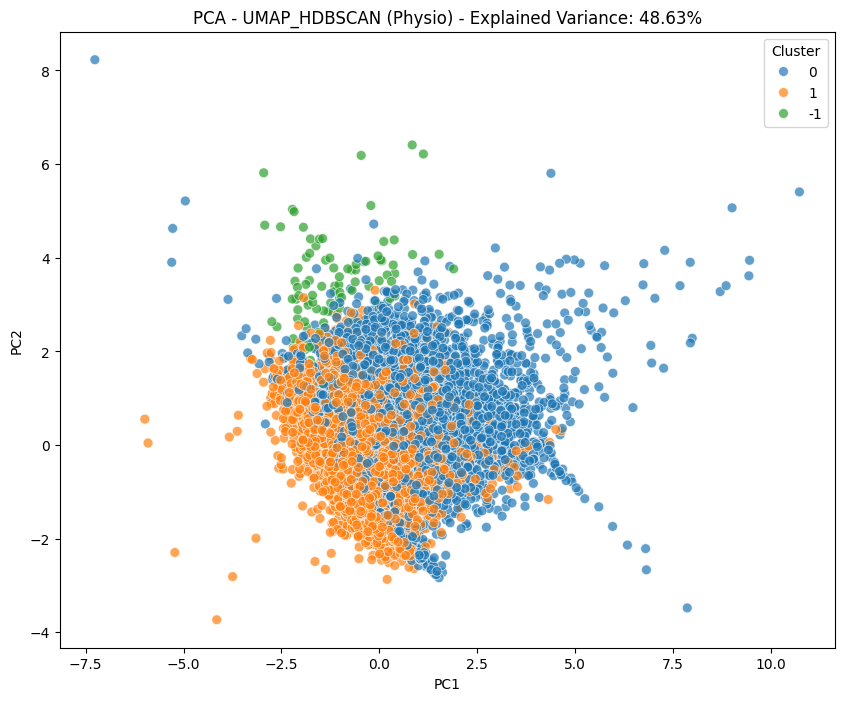

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,0.381717,-0.267213
pct_regain,0.564255,0.342831
early_wl_speed,0.314055,-0.294575
time_to_nadir_ratio,-0.502364,-0.439054
trajectory_volatility,-0.226430,-0.135503
lean_loss_coeff,-0.158664,0.487734
muscle_fat_corr,-0.329339,0.524667


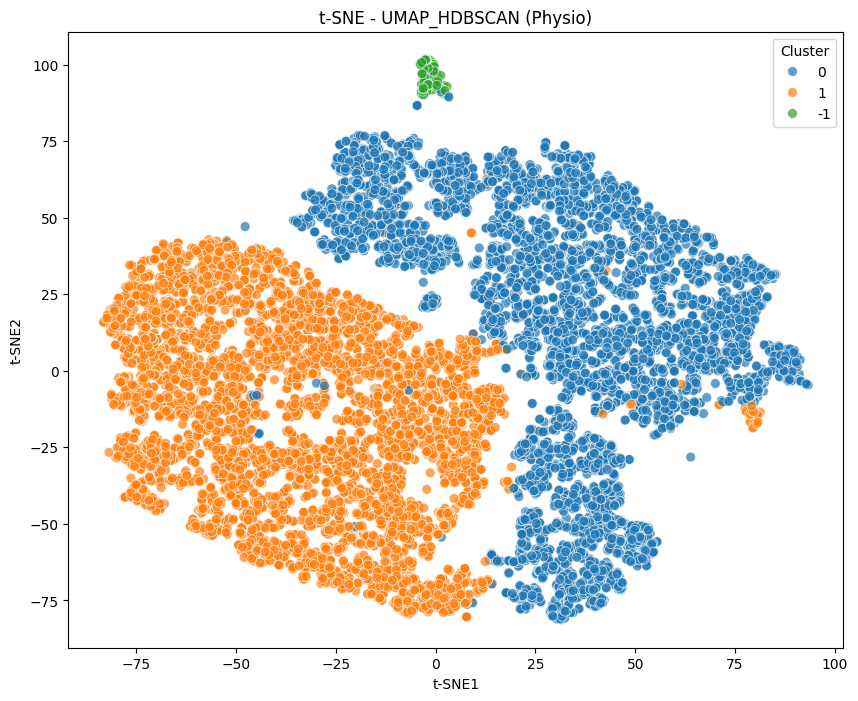

c:\Users\miksa.henkrich\OneDrive - IMDEANU\Escritorio\PNK\p4_dir\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


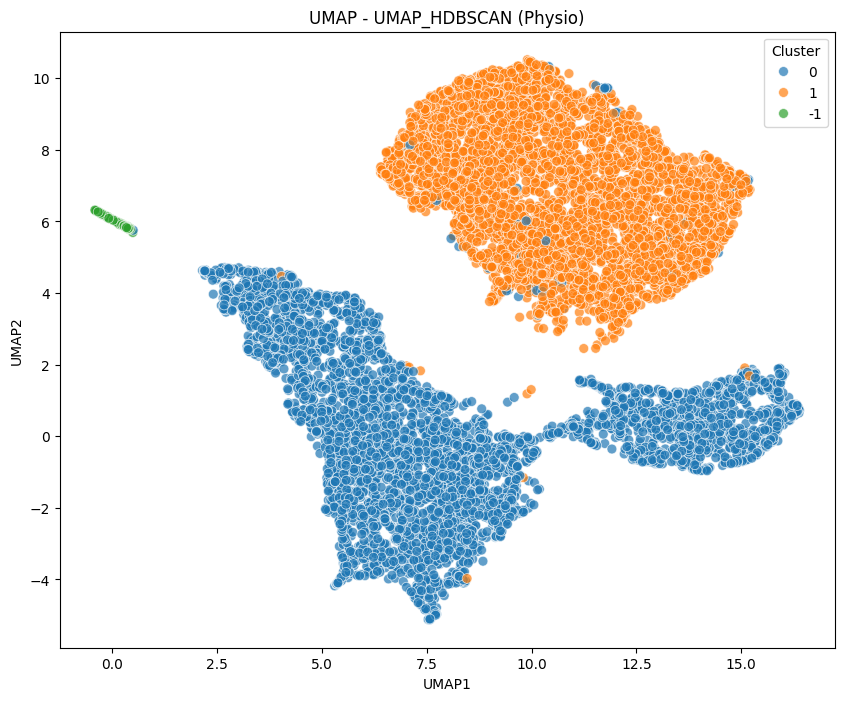


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


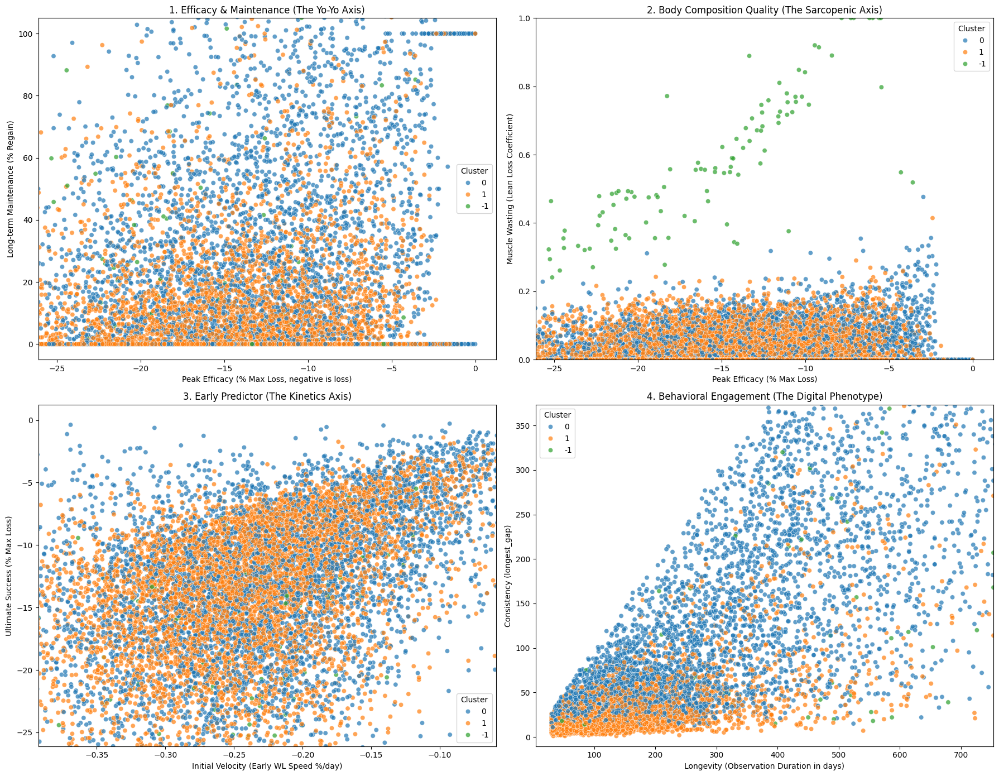


--- 4. TRAJECTORY HOMOGENEITY SAMPLES ---


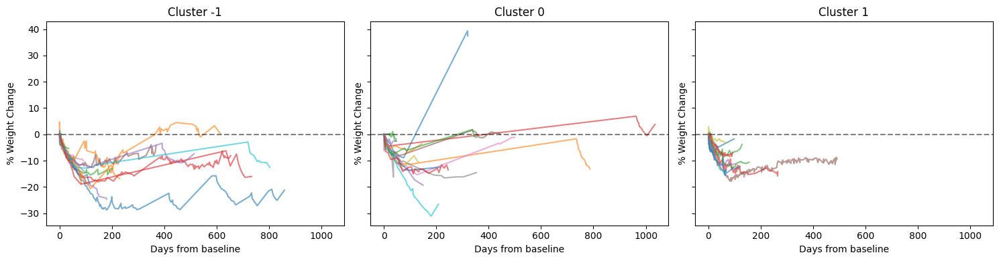


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...
                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                11353
Model:                        MNLogit   Df Residuals:                    11349
Method:                           MLE   Df Model:                            3
Date:                Tue, 29 Sep 2026   Pseudo R-squ.:                 0.01377
Time:                        14:57:43   Log-Likelihood:                -7758.5
converged:                       True   LL-Null:                       -7866.8
Covariance Type:            nonrobust   LLR p-value:                 1.026e-46
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.1553      0.186     11.577      0.000       1.790       2.520
age           -0.0103      0.

In [7]:
# -------------------------------------------------------------------------
# Feature-Based Clustering: 2. Unified Grid Search & Characterization Pipeline
# -------------------------------------------------------------------------
import pandas as pd
from clustering_pipeline import run_clustering_pipeline

# --- CONFIGURATION ---
# To trigger a grid search, pass multiple elements in these lists or a range for K.
# To trigger a specific single run, pass exactly one element in each list.
BLOCKS = ['Physio'] # 'Kinetic', 'Metabolic', 'Behavioral', 'Physio', 'Holistic'
MODELS = ['UMAP_HDBSCAN'] # 'GMM', 'WARD', 'KMEANS', 'HDBSCAN' - 'CLARA' implementation eventually removed! 
K_RANGE = range(2, 8) # range(2, 8) - accepts integers as well
# ---------------------

run_clustering_pipeline(
    df_features=df_features, 
    db_path=DB_PATH,
    id_col=ID_COL,
    blocks=BLOCKS, 
    models=MODELS, 
    k_range=K_RANGE
)

#### UMAP_HDBSCAN Holistic on PATIENTS 

                 COMPREHENSIVE GRID SEARCH                      
Running grid search across 1 blocks and 1 models...
\n--- Top 5 Clustering Candidate Setups (by Silhouette) ---


,Block,Model,Param (k/size),Clusters Found,Noise Ratio,Silhouette,Davies-Bouldin,BIC
5,Holistic,UMAP_HDBSCAN,size:700_samp:70,2,0.043103,0.128356,2.219210,NaN
4,Holistic,UMAP_HDBSCAN,size:600_samp:60,2,0.045720,0.128089,2.220273,NaN
3,Holistic,UMAP_HDBSCAN,size:500_samp:50,3,0.081581,0.112862,2.243236,NaN
2,Holistic,UMAP_HDBSCAN,size:400_samp:40,3,0.101300,0.105829,2.253325,NaN
1,Holistic,UMAP_HDBSCAN,size:300_samp:30,5,0.216910,0.052670,1.902489,NaN


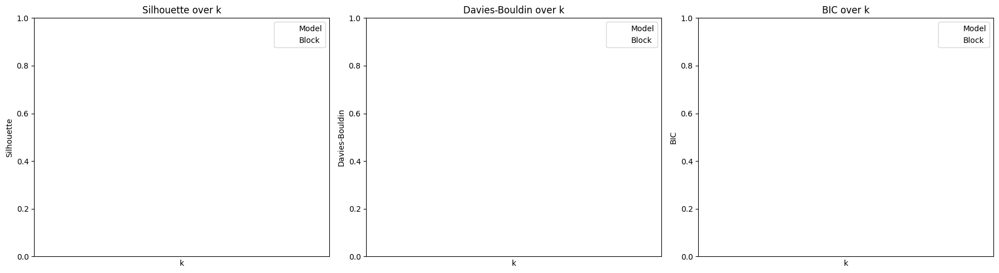


      DEEP CHARACTERIZATION: UMAP_HDBSCAN on Holistic (size:700_samp:70)

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max_loss             1.000087
pct_regain               1.000087
early_wl_speed           1.000087
time_to_nadir_ratio      1.000087
trajectory_volatility    1.000087
lean_loss_coeff          1.000087
muscle_fat_corr          1.000087
observation_duration     1.000087
longest_gap              1.000087


c:\Users\miksa.henkrich\OneDrive - IMDEANU\Escritorio\PNK\p4_dir\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



Internal Validity Metrics:
  - Silhouette: 0.1284
  - Davies-Bouldin: 2.2192
  - BIC: N/A

--- 2. DIMENSIONALITY REDUCTION ---


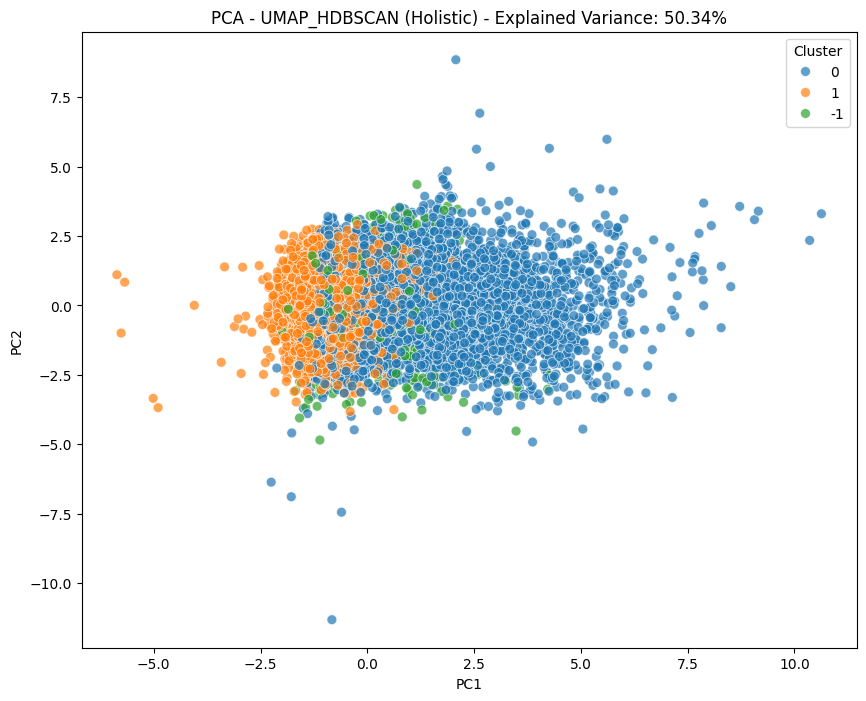

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,0.010343,0.548593
pct_regain,0.430036,0.182463
early_wl_speed,0.052953,0.450699
time_to_nadir_ratio,-0.482258,-0.036833
trajectory_volatility,-0.252431,-0.011583
lean_loss_coeff,0.006072,-0.355903
muscle_fat_corr,-0.057784,-0.531421
observation_duration,0.512457,-0.200354
longest_gap,0.499875,-0.109160


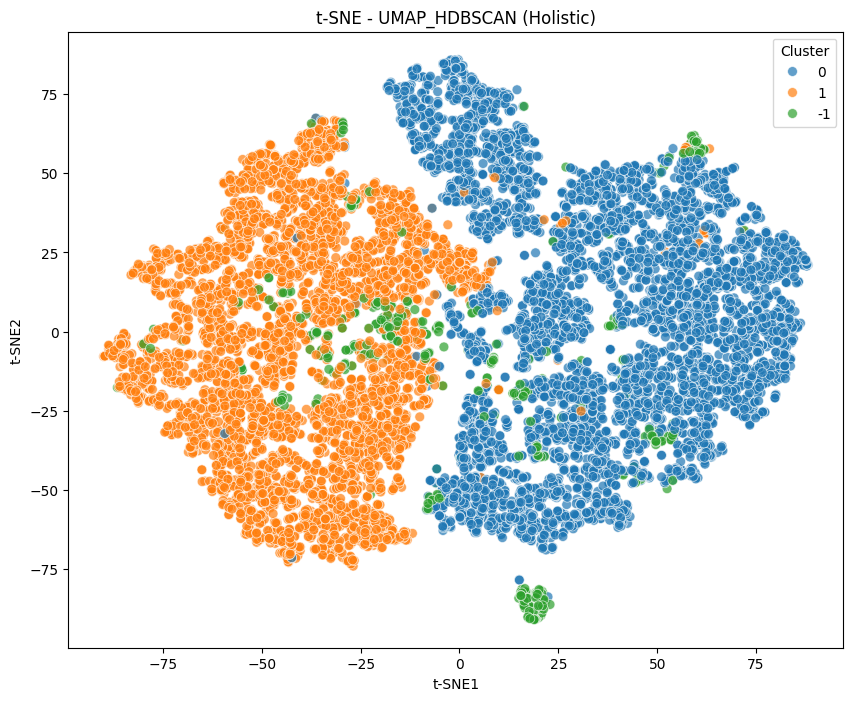

c:\Users\miksa.henkrich\OneDrive - IMDEANU\Escritorio\PNK\p4_dir\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


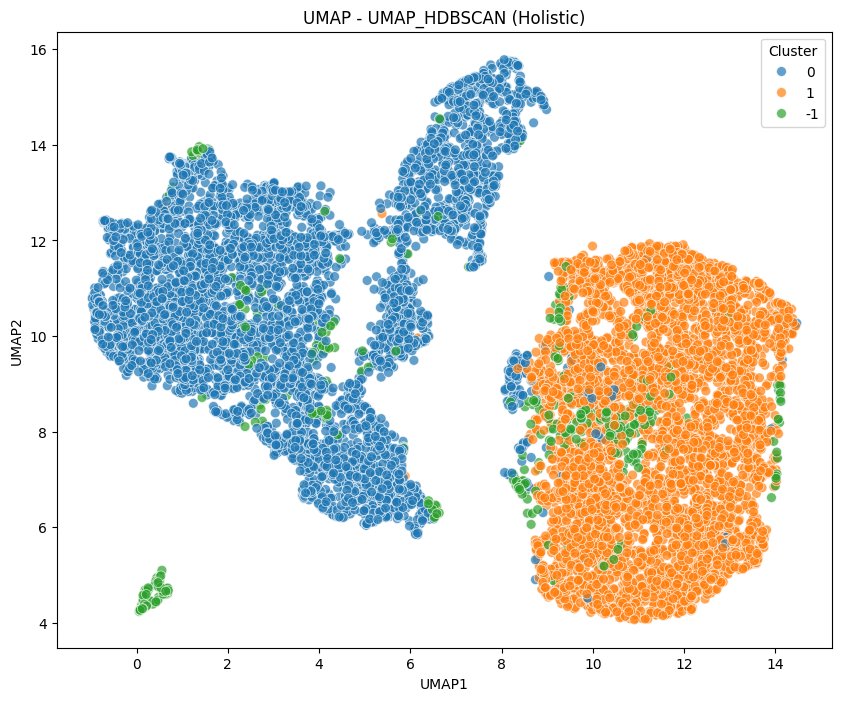


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


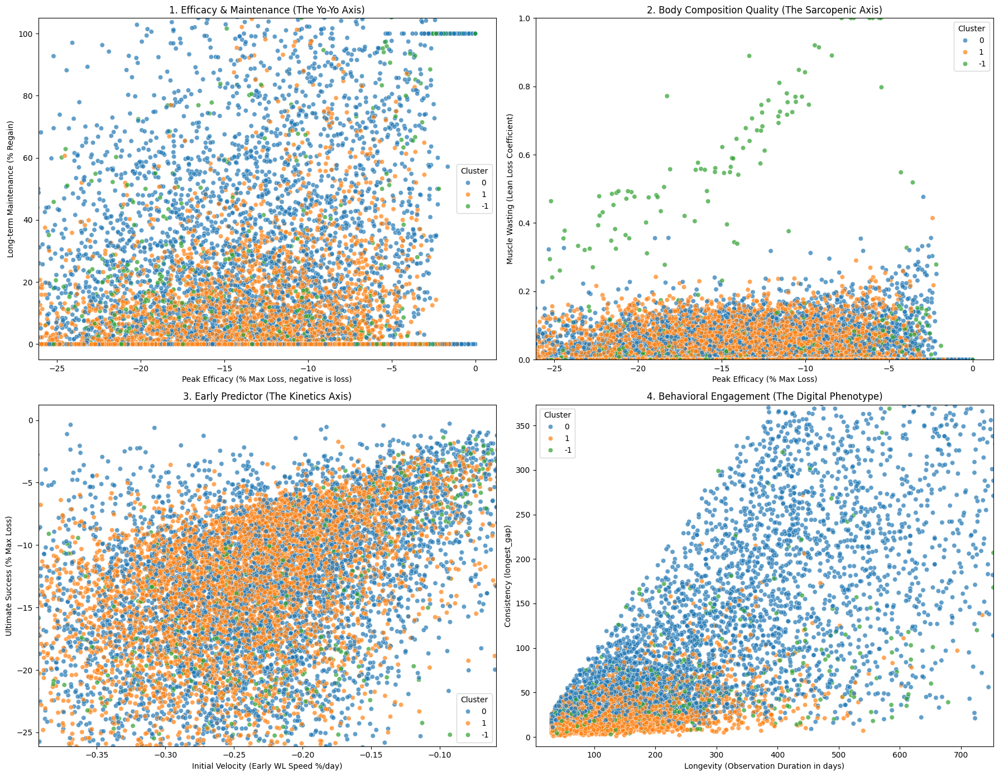


--- 4. TRAJECTORY HOMOGENEITY SAMPLES ---


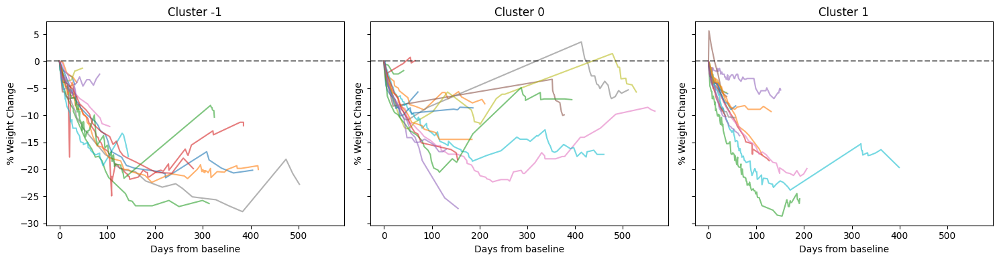


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...
                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                10967
Model:                        MNLogit   Df Residuals:                    10963
Method:                           MLE   Df Model:                            3
Date:                Tue, 29 Sep 2026   Pseudo R-squ.:                 0.01358
Time:                        14:56:12   Log-Likelihood:                -7460.3
converged:                       True   LL-Null:                       -7563.0
Covariance Type:            nonrobust   LLR p-value:                 2.893e-44
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.2051      0.191     11.564      0.000       1.831       2.579
age           -0.0114      0.

In [6]:
# -------------------------------------------------------------------------
# Feature-Based Clustering: 2. Unified Grid Search & Characterization Pipeline
# -------------------------------------------------------------------------
import pandas as pd
from clustering_pipeline import run_clustering_pipeline

# --- CONFIGURATION ---
# To trigger a grid search, pass multiple elements in these lists or a range for K.
# To trigger a specific single run, pass exactly one element in each list.
BLOCKS = ['Holistic'] # 'Kinetic', 'Metabolic', 'Behavioral', 'Physio', 'Holistic'
MODELS = ['UMAP_HDBSCAN'] # 'GMM', 'WARD', 'KMEANS', 'HDBSCAN' - 'CLARA' implementation eventually removed! 
K_RANGE = range(2, 8) # range(2, 8) - accepts integers as well
# ---------------------

run_clustering_pipeline(
    df_features=df_features, 
    db_path=DB_PATH,
    id_col=ID_COL,
    blocks=BLOCKS, 
    models=MODELS, 
    k_range=K_RANGE
)

### End-to-end FI to cluster pipeline with fixed time windows

#### test grid - no k defined

algorithm optimizes for 2 clusters (3 at 1 year), with the second being the tiny fraction of sarcopenic losers

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload

               RUNNING TIME-WINDOW PIPELINE: 30 DAYS (+/- 10)
Fetching raw longitudinal measurements at the patient_id level...
Initial data: 14515 patient_ids, 396210 measurements.
After dropping missing weight/fat/muscle entries: 14438 patient_ids, 360306 measurements.
Dropped 5074 same-day duplicate measurements (kept highest weight). Remaining: 14438 patient_ids, 355232 measurements.
Processing 14438 patient_id units for feature extraction...

--- Feature Extraction Summary ---
Retained: 5251 patient_id units for clustering.
Excluded: 9187 patient_id units (due to early attrition: < 30 days follow-up OR < 3 total measurements).

Extracted 5251 valid trajectories for the 30-day window.
Excluded 9187 entities (these will appear as 'Dropout').
                 COMPREHENSIVE GRID SEARCH                      
Running grid search across 1 blocks and 1 models...
\n--- Top 5 Clustering Candidate Setups

,Block,Model,Param (k/size),Clusters Found,Noise Ratio,Silhouette,Davies-Bouldin,BIC
0,Holistic windowed,SPECTRAL,2,2,0.0,0.696937,0.448975,NaN
1,Holistic windowed,SPECTRAL,3,3,0.0,0.648358,0.630975,NaN
4,Holistic windowed,SPECTRAL,6,6,0.0,0.171153,1.293110,NaN
5,Holistic windowed,SPECTRAL,7,7,0.0,0.169779,1.188608,NaN
3,Holistic windowed,SPECTRAL,5,5,0.0,0.169571,1.201684,NaN


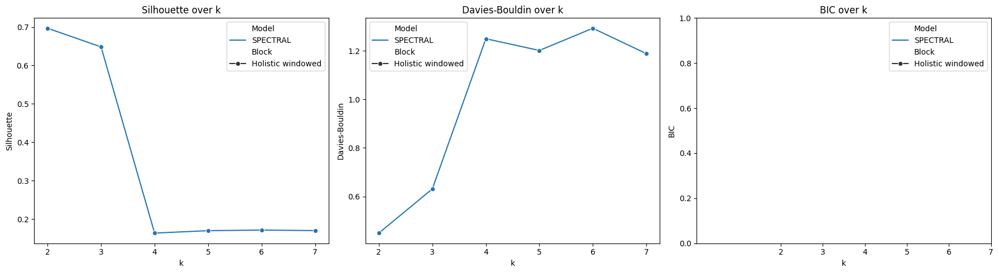


      DEEP CHARACTERIZATION: SPECTRAL on Holistic windowed (2)

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max_loss             1.00019
pct_regain               1.00019
early_wl_speed           1.00019
time_to_nadir_ratio      1.00019
trajectory_volatility    1.00019
lean_loss_coeff          1.00019
muscle_fat_corr          1.00019
observation_gap_ratio    1.00019

Internal Validity Metrics:
  - Silhouette: 0.6969
  - Davies-Bouldin: 0.4490
  - BIC: N/A

--- 2. DIMENSIONALITY REDUCTION ---


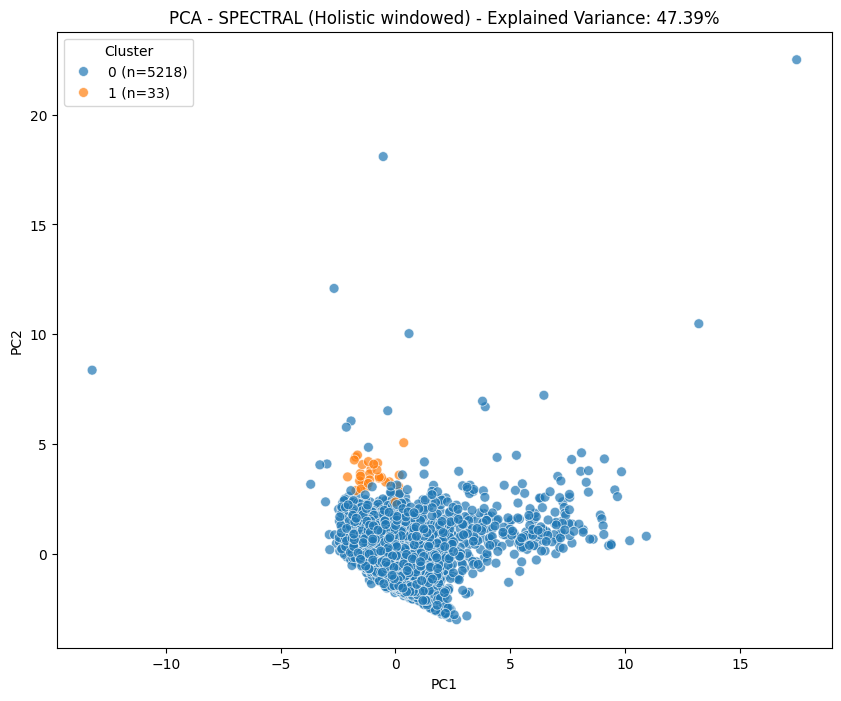

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,0.489847,-0.343424
pct_regain,0.507387,0.289513
early_wl_speed,0.410328,-0.164358
time_to_nadir_ratio,-0.494859,-0.326841
trajectory_volatility,0.076289,0.459137
lean_loss_coeff,-0.059894,0.417307
muscle_fat_corr,-0.098652,0.514428
observation_gap_ratio,0.264979,-0.121719


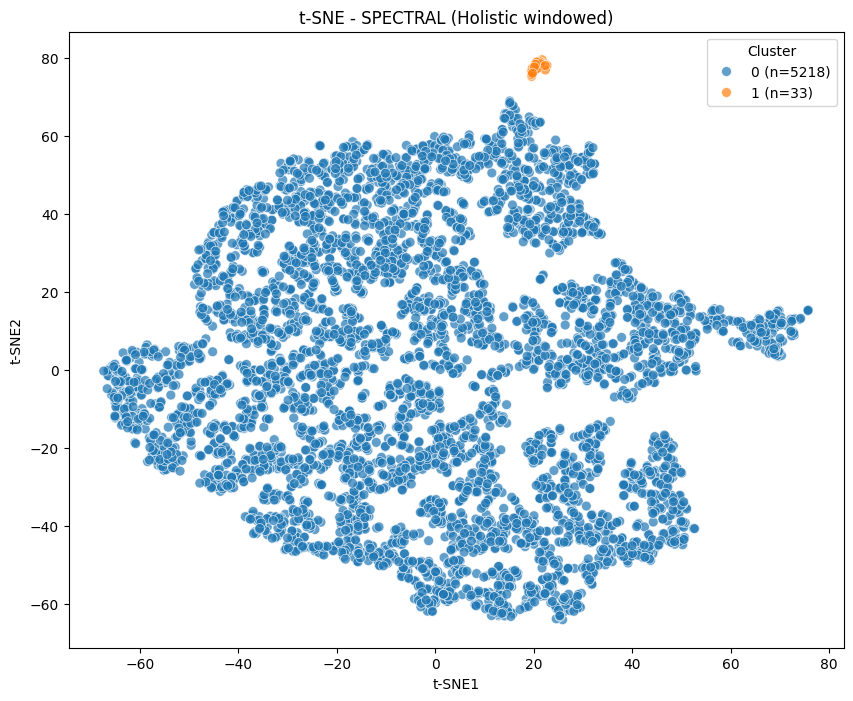

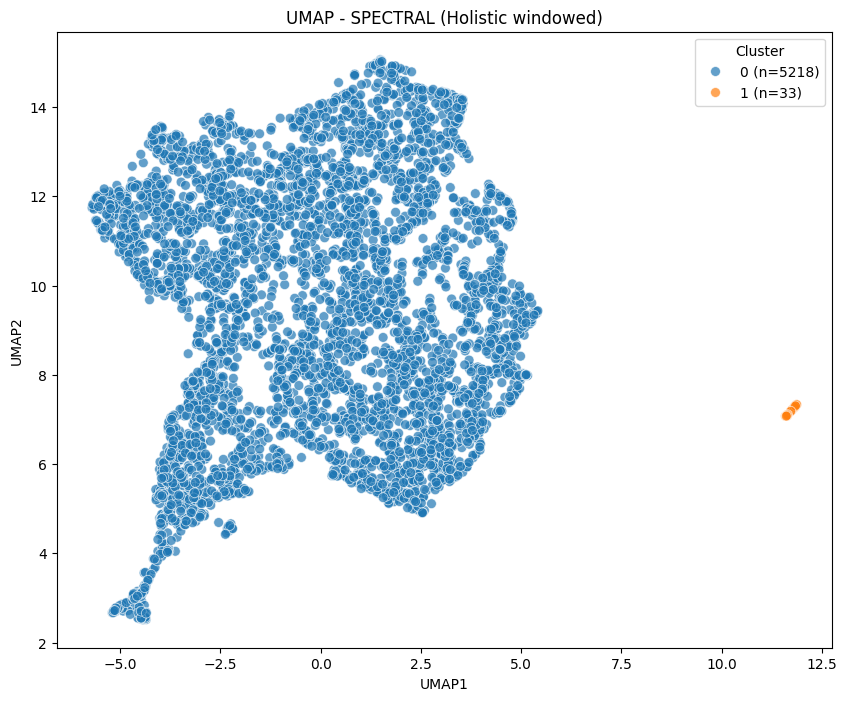


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


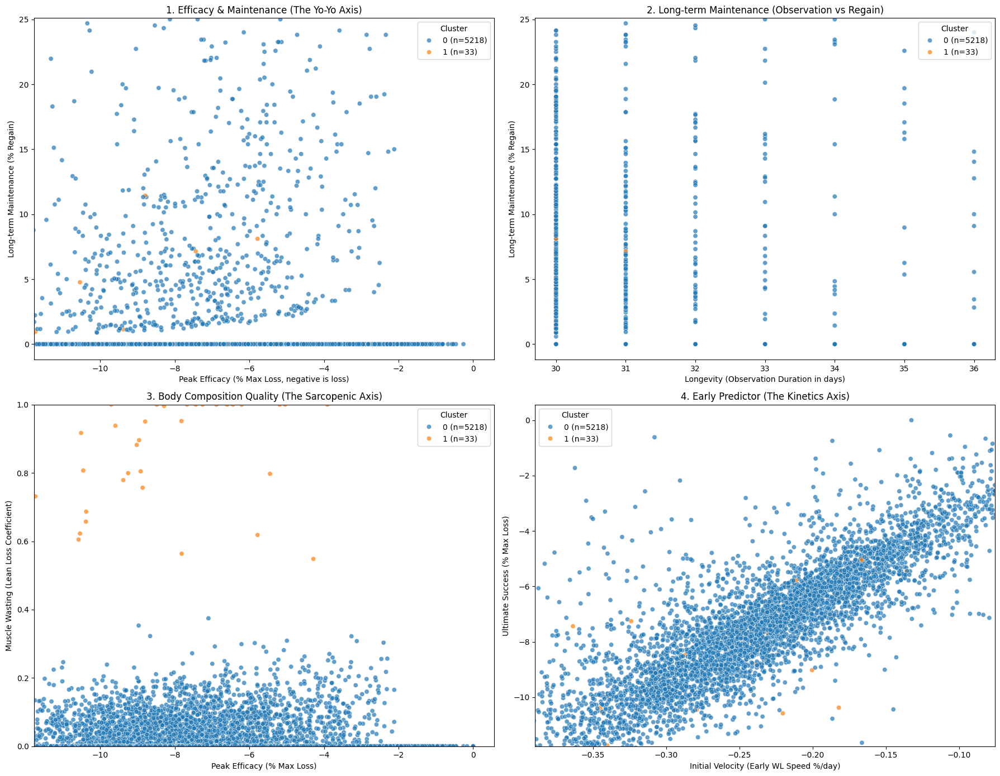


--- 4. TRAJECTORY HOMOGENEITY SAMPLES ---


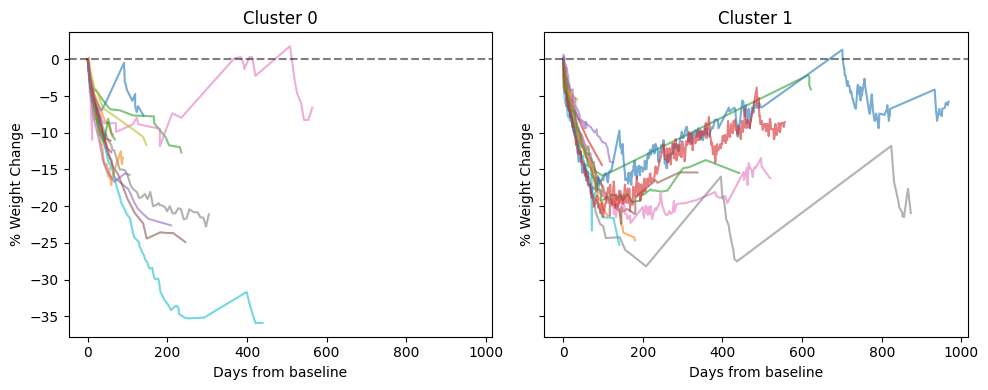

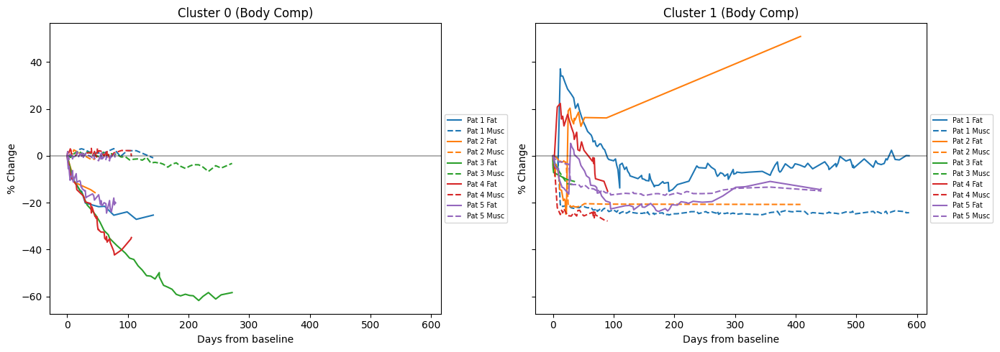


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...

--- CLUSTER SIZES ---
cluster_id
0    5218
1      33
---------------------

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                 5251
Model:                        MNLogit   Df Residuals:                     5247
Method:                           MLE   Df Model:                            3
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:                 0.04444
Time:                        10:09:50   Log-Likelihood:                -191.30
converged:                      False   LL-Null:                       -200.20
Covariance Type:            nonrobust   LLR p-value:                 0.0004852
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -23.5709   7009.35

,Variable,Cluster 0.0,Cluster 1.0,Dropout,p_value
0,Cluster Size (N),5218,33,9264,N/A
1,age_when_creating_record,47.00 (41.00-54.00),45.00 (40.00-52.00),47.00 (40.00-54.00),0.245
2,sex_f,77.1%,100.0%,80.5%,<0.001
3,height_m,1.65 (1.60-1.71),1.63 (1.59-1.68),1.65 (1.60-1.70),<0.001
4,wc_cm_confirm_time,100.00 (91.00-109.00),99.50 (95.75-103.25),100.00 (91.00-109.75),0.975
5,nr_medical_records_patient,1.00 (1.00-2.00),1.00 (1.00-2.00),1.00 (1.00-2.00),<0.001
6,dietitian_visits,4.00 (2.00-7.00),6.00 (4.00-8.00),3.00 (1.00-6.00),<0.001
7,womens_health_and_pregnancy,28.2%,50.0%,26.0%,0.720
8,mental_health,23.6%,0.0%,24.4%,0.855
9,family_issues,5.5%,0.0%,4.9%,0.899



               RUNNING TIME-WINDOW PIPELINE: 90 DAYS (+/- 10)
Fetching raw longitudinal measurements at the patient_id level...
Initial data: 14515 patient_ids, 396210 measurements.
After dropping missing weight/fat/muscle entries: 14438 patient_ids, 360306 measurements.
Dropped 5074 same-day duplicate measurements (kept highest weight). Remaining: 14438 patient_ids, 355232 measurements.
Processing 14438 patient_id units for feature extraction...

--- Feature Extraction Summary ---
Retained: 6540 patient_id units for clustering.
Excluded: 7898 patient_id units (due to early attrition: < 30 days follow-up OR < 3 total measurements).

Extracted 6540 valid trajectories for the 90-day window.
Excluded 7898 entities (these will appear as 'Dropout').
                 COMPREHENSIVE GRID SEARCH                      
Running grid search across 1 blocks and 1 models...
\n--- Top 5 Clustering Candidate Setups (by Silhouette) ---


,Block,Model,Param (k/size),Clusters Found,Noise Ratio,Silhouette,Davies-Bouldin,BIC
0,Holistic windowed,SPECTRAL,2,2,0.0,0.578321,0.711326,NaN
1,Holistic windowed,SPECTRAL,3,3,0.0,0.503694,1.007450,NaN
3,Holistic windowed,SPECTRAL,5,5,0.0,0.191953,1.333282,NaN
2,Holistic windowed,SPECTRAL,4,4,0.0,0.189639,1.419501,NaN
4,Holistic windowed,SPECTRAL,6,6,0.0,0.157223,1.452937,NaN


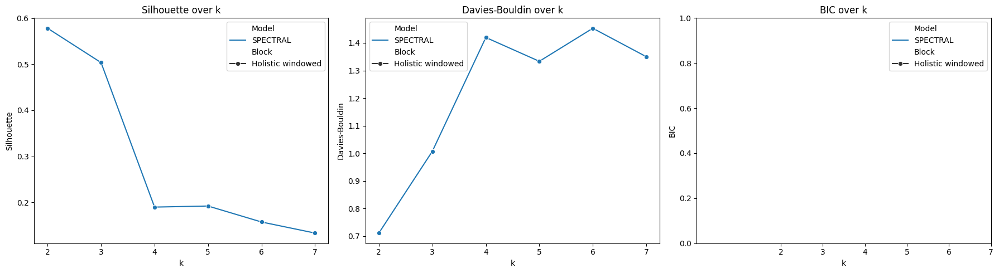


      DEEP CHARACTERIZATION: SPECTRAL on Holistic windowed (2)

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max_loss             1.000153
pct_regain               1.000153
early_wl_speed           1.000153
time_to_nadir_ratio      1.000153
trajectory_volatility    1.000153
lean_loss_coeff          1.000153
muscle_fat_corr          1.000153
observation_gap_ratio    1.000153

Internal Validity Metrics:
  - Silhouette: 0.5783
  - Davies-Bouldin: 0.7113
  - BIC: N/A

--- 2. DIMENSIONALITY REDUCTION ---


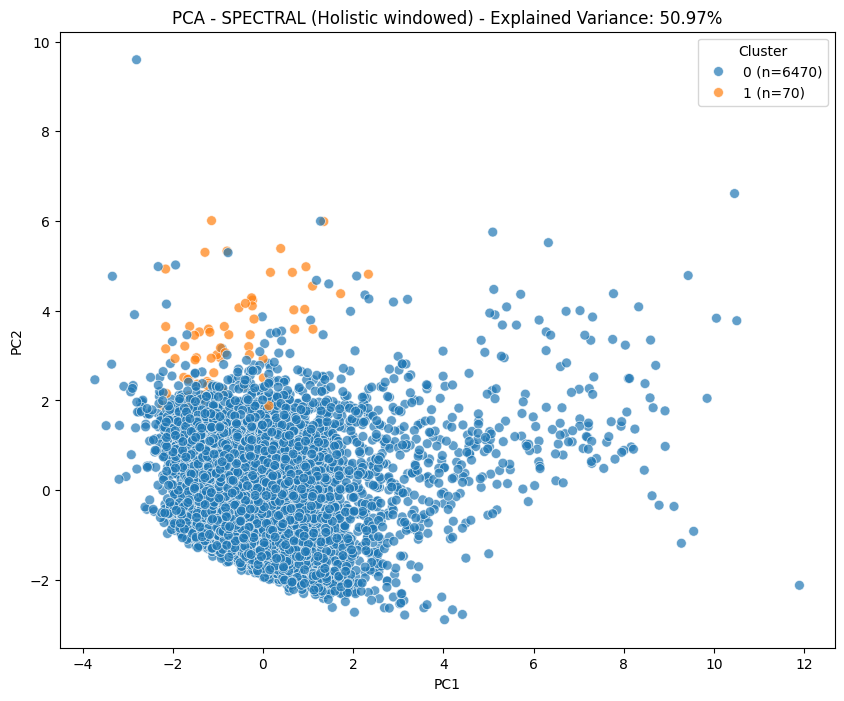

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,0.520034,-0.107360
pct_regain,0.469897,0.273987
early_wl_speed,0.301238,-0.281987
time_to_nadir_ratio,-0.457947,-0.341393
trajectory_volatility,-0.162061,0.311331
lean_loss_coeff,-0.041194,0.528900
muscle_fat_corr,-0.137310,0.583333
observation_gap_ratio,0.401855,0.019983


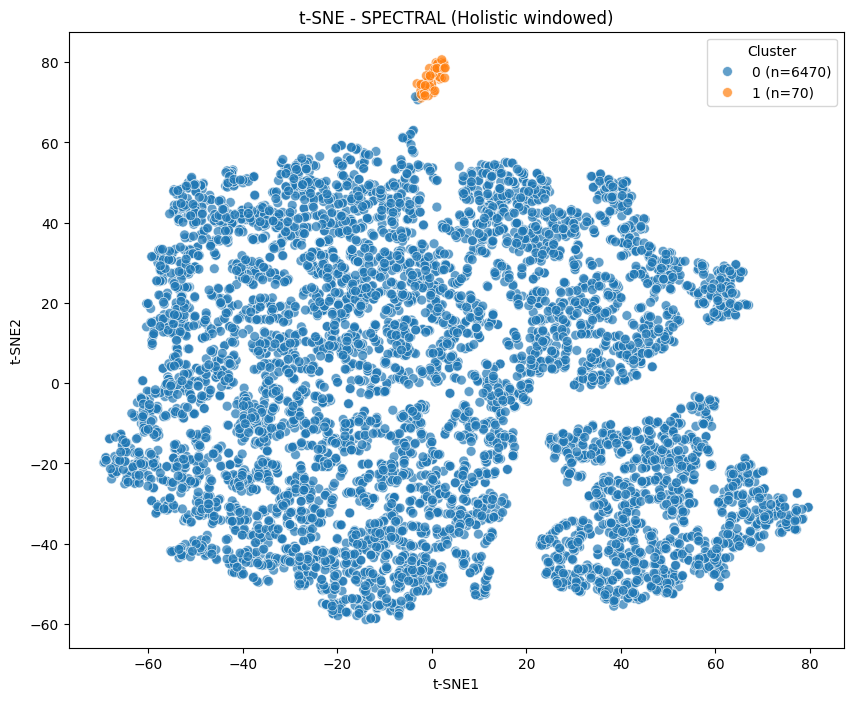

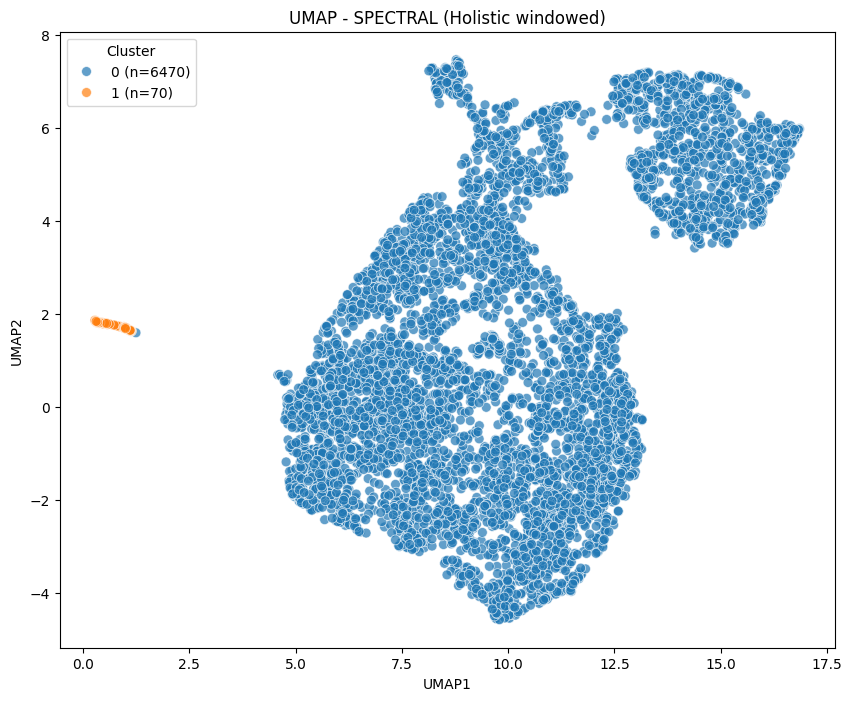


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


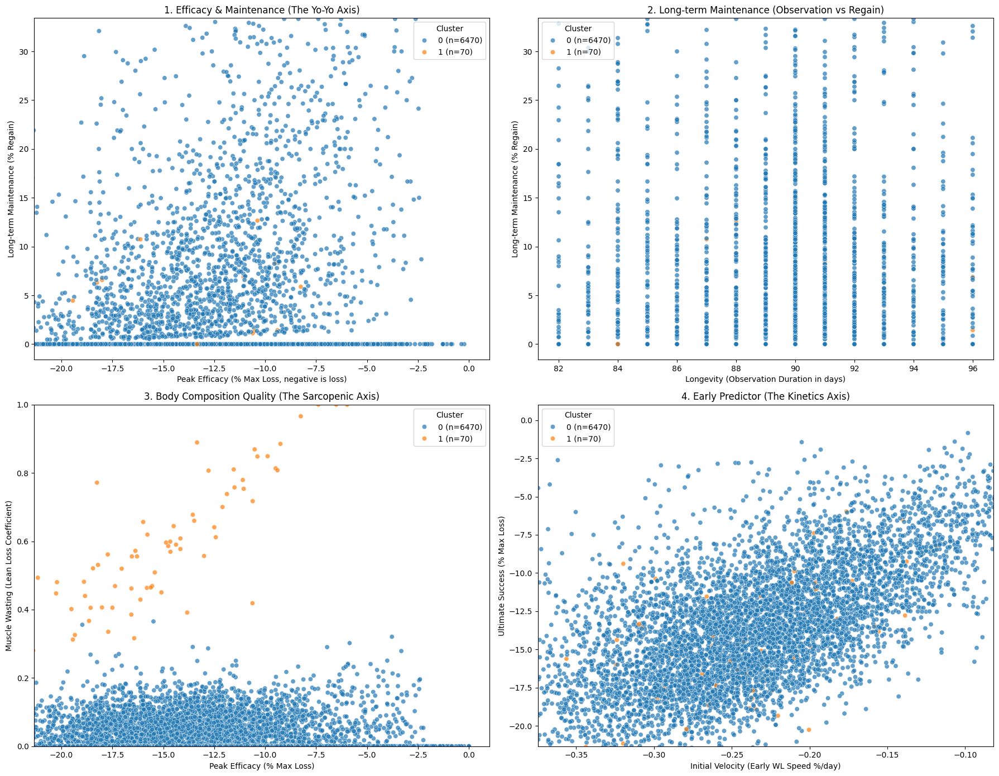


--- 4. TRAJECTORY HOMOGENEITY SAMPLES ---


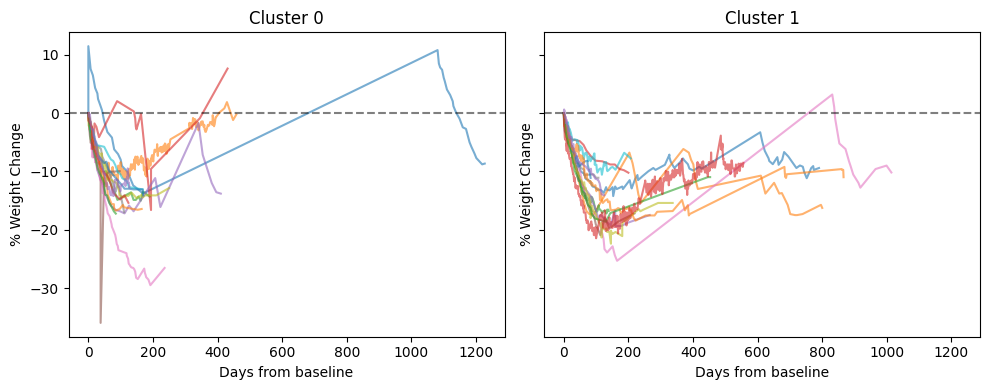

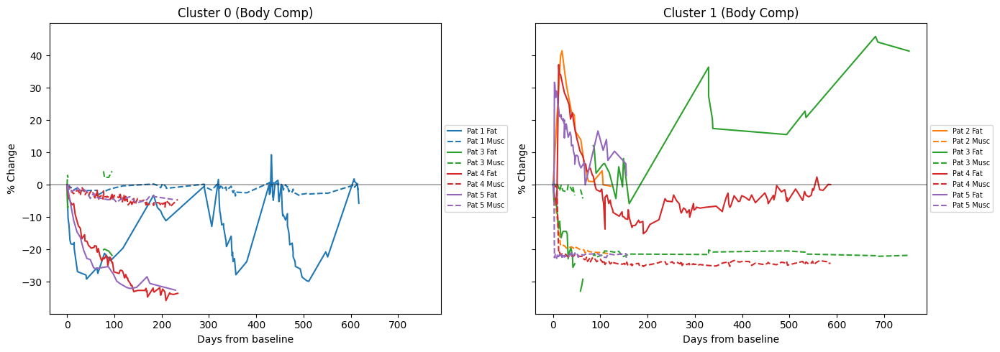


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...

--- CLUSTER SIZES ---
cluster_id
0    6470
1      70
---------------------

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                 6540
Model:                        MNLogit   Df Residuals:                     6536
Method:                           MLE   Df Model:                            3
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:                 0.03552
Time:                        10:11:52   Log-Likelihood:                -373.47
converged:                       True   LL-Null:                       -387.23
Covariance Type:            nonrobust   LLR p-value:                 4.598e-06
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -6.0140      1.54

,Variable,Cluster 0.0,Cluster 1.0,Dropout,p_value
0,Cluster Size (N),6470,70,7975,N/A
1,age_when_creating_record,48.00 (41.00-55.00),46.50 (40.00-53.50),46.00 (39.00-53.00),<0.001
2,sex_f,79.2%,98.6%,79.2%,0.001
3,height_m,1.65 (1.60-1.70),1.62 (1.59-1.69),1.65 (1.60-1.70),0.030
4,wc_cm_confirm_time,100.00 (92.00-110.00),100.00 (93.00-104.00),100.00 (90.00-109.00),<0.001
5,nr_medical_records_patient,1.00 (1.00-2.00),1.00 (1.00-2.00),1.00 (1.00-2.00),<0.001
6,dietitian_visits,5.00 (3.00-8.00),6.50 (4.00-10.00),2.00 (1.00-4.00),<0.001
7,womens_health_and_pregnancy,24.6%,40.0%,28.7%,0.156
8,mental_health,25.2%,10.0%,23.2%,0.575
9,family_issues,6.1%,0.0%,4.3%,0.316



               RUNNING TIME-WINDOW PIPELINE: 180 DAYS (+/- 10)
Fetching raw longitudinal measurements at the patient_id level...
Initial data: 14515 patient_ids, 396210 measurements.
After dropping missing weight/fat/muscle entries: 14438 patient_ids, 360306 measurements.
Dropped 5074 same-day duplicate measurements (kept highest weight). Remaining: 14438 patient_ids, 355232 measurements.
Processing 14438 patient_id units for feature extraction...

--- Feature Extraction Summary ---
Retained: 2561 patient_id units for clustering.
Excluded: 11877 patient_id units (due to early attrition: < 30 days follow-up OR < 3 total measurements).

Extracted 2561 valid trajectories for the 180-day window.
Excluded 11877 entities (these will appear as 'Dropout').
                 COMPREHENSIVE GRID SEARCH                      
Running grid search across 1 blocks and 1 models...
\n--- Top 5 Clustering Candidate Setups (by Silhouette) ---


,Block,Model,Param (k/size),Clusters Found,Noise Ratio,Silhouette,Davies-Bouldin,BIC
0,Holistic windowed,SPECTRAL,2,2,0.0,0.505250,0.797620,NaN
1,Holistic windowed,SPECTRAL,3,3,0.0,0.247339,1.413014,NaN
2,Holistic windowed,SPECTRAL,4,4,0.0,0.187457,1.399609,NaN
3,Holistic windowed,SPECTRAL,5,5,0.0,0.134141,1.543681,NaN
5,Holistic windowed,SPECTRAL,7,7,0.0,0.121418,1.511161,NaN


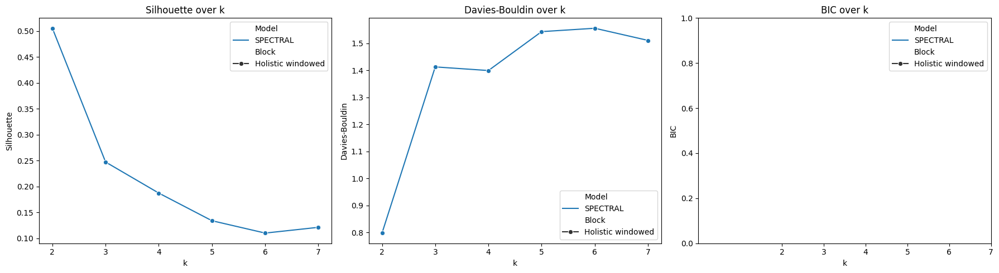


      DEEP CHARACTERIZATION: SPECTRAL on Holistic windowed (2)

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max_loss             1.000391
pct_regain               1.000391
early_wl_speed           1.000391
time_to_nadir_ratio      1.000391
trajectory_volatility    1.000391
lean_loss_coeff          1.000391
muscle_fat_corr          1.000391
observation_gap_ratio    1.000391

Internal Validity Metrics:
  - Silhouette: 0.5052
  - Davies-Bouldin: 0.7976
  - BIC: N/A

--- 2. DIMENSIONALITY REDUCTION ---


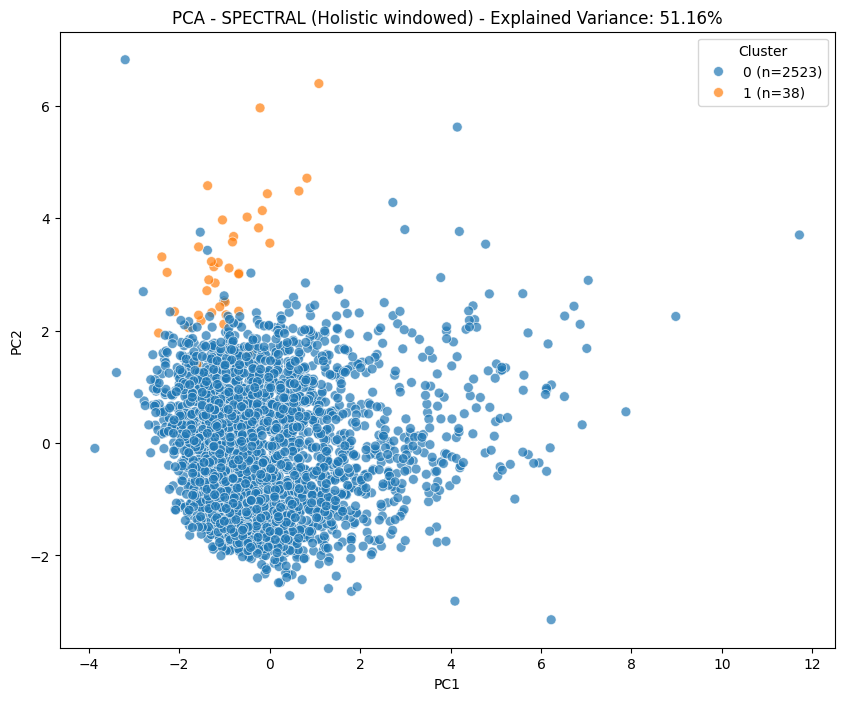

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,0.524036,-0.054995
pct_regain,0.477596,0.190039
early_wl_speed,0.200064,-0.380576
time_to_nadir_ratio,-0.476842,-0.263562
trajectory_volatility,-0.117386,0.082155
lean_loss_coeff,-0.048759,0.583269
muscle_fat_corr,-0.171636,0.627093
observation_gap_ratio,0.429265,0.079750


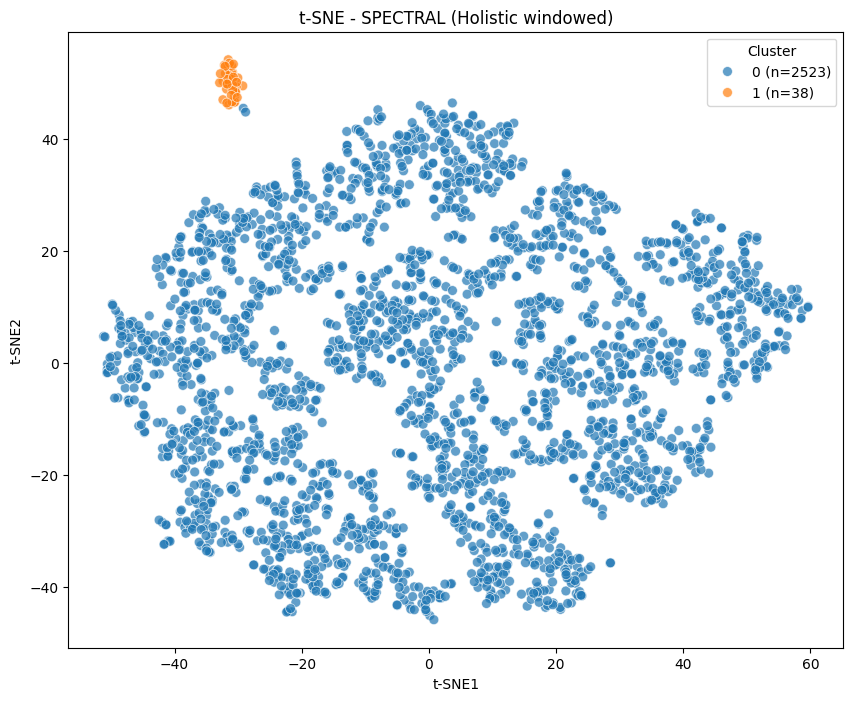

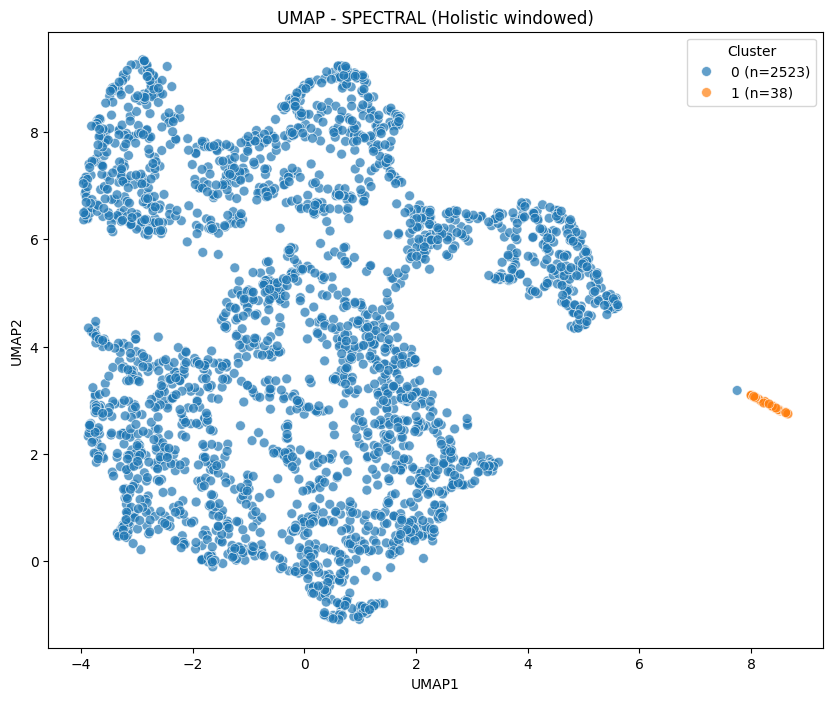


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


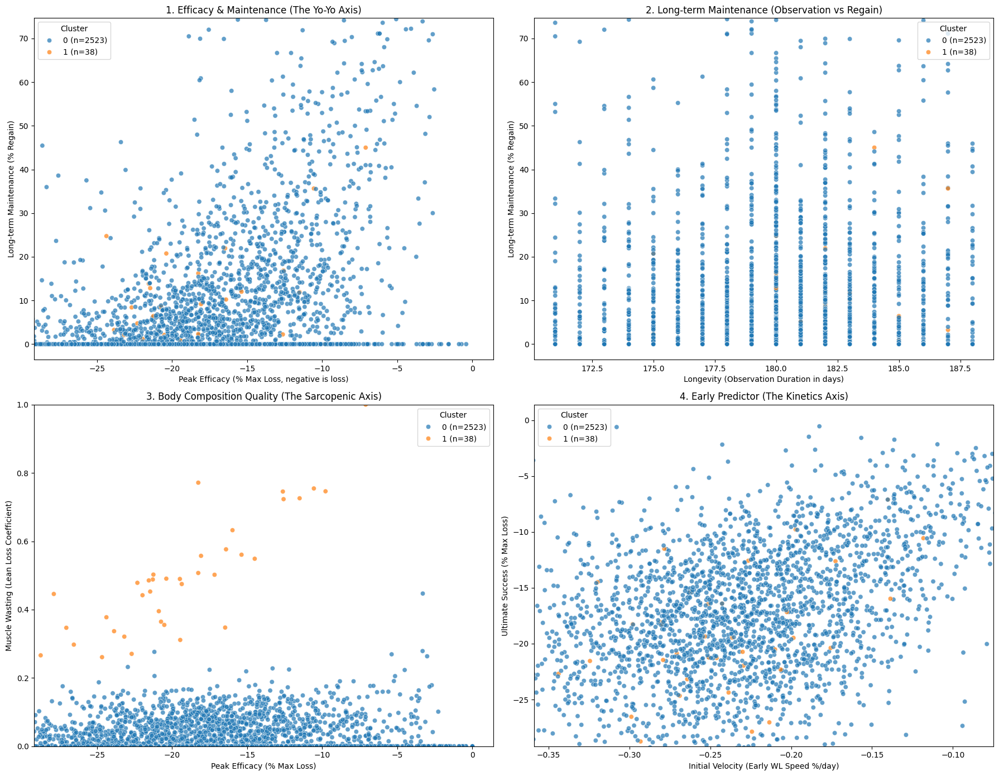


--- 4. TRAJECTORY HOMOGENEITY SAMPLES ---


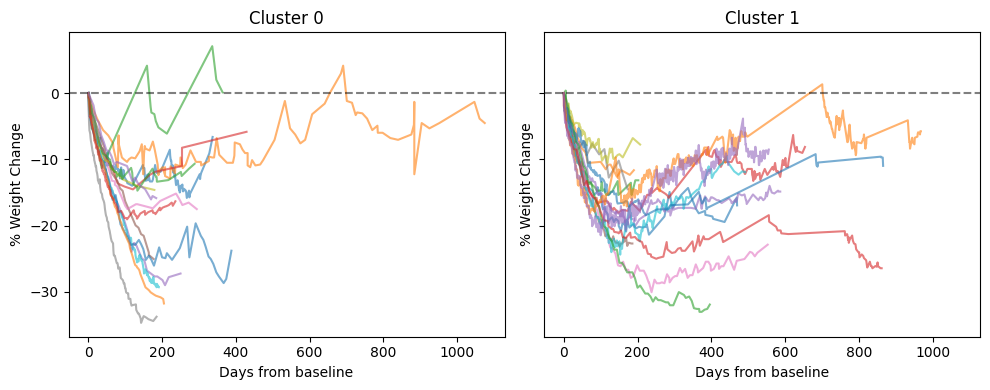

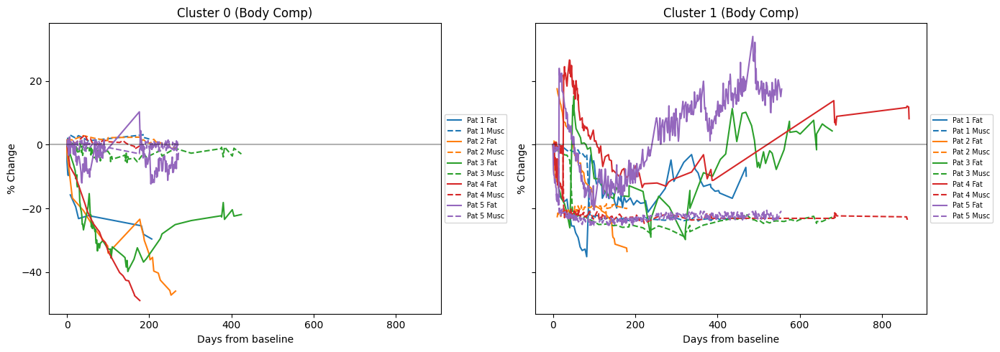


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...

--- CLUSTER SIZES ---
cluster_id
0    2523
1      38
---------------------

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                 2561
Model:                        MNLogit   Df Residuals:                     2557
Method:                           MLE   Df Model:                            3
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:                 0.02192
Time:                        10:13:17   Log-Likelihood:                -193.38
converged:                       True   LL-Null:                       -197.72
Covariance Type:            nonrobust   LLR p-value:                   0.03405
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.2240      1.76

,Variable,Cluster 0.0,Cluster 1.0,Dropout,p_value
0,Cluster Size (N),2523,38,11954,N/A
1,age_when_creating_record,49.00 (43.00-55.00),45.00 (42.00-54.75),47.00 (40.00-53.00),<0.001
2,sex_f,80.8%,94.7%,79.0%,0.029
3,height_m,1.65 (1.60-1.70),1.62 (1.59-1.68),1.65 (1.60-1.71),<0.001
4,wc_cm_confirm_time,101.00 (94.00-110.00),96.00 (90.00-100.00),100.00 (91.00-109.00),<0.001
5,nr_medical_records_patient,1.00 (1.00-2.00),2.00 (1.00-3.00),1.00 (1.00-2.00),<0.001
6,dietitian_visits,7.00 (4.00-11.00),9.50 (7.00-14.00),3.00 (2.00-5.00),<0.001
7,womens_health_and_pregnancy,24.4%,50.0%,27.3%,0.496
8,mental_health,23.3%,16.7%,24.3%,0.962
9,family_issues,5.7%,0.0%,5.0%,0.946



               RUNNING TIME-WINDOW PIPELINE: 360 DAYS (+/- 10)
Fetching raw longitudinal measurements at the patient_id level...
Initial data: 14515 patient_ids, 396210 measurements.
After dropping missing weight/fat/muscle entries: 14438 patient_ids, 360306 measurements.
Dropped 5074 same-day duplicate measurements (kept highest weight). Remaining: 14438 patient_ids, 355232 measurements.
Processing 14438 patient_id units for feature extraction...

--- Feature Extraction Summary ---
Retained: 953 patient_id units for clustering.
Excluded: 13485 patient_id units (due to early attrition: < 30 days follow-up OR < 3 total measurements).

Extracted 953 valid trajectories for the 360-day window.
Excluded 13485 entities (these will appear as 'Dropout').
                 COMPREHENSIVE GRID SEARCH                      
Running grid search across 1 blocks and 1 models...
\n--- Top 5 Clustering Candidate Setups (by Silhouette) ---


,Block,Model,Param (k/size),Clusters Found,Noise Ratio,Silhouette,Davies-Bouldin,BIC
1,Holistic windowed,SPECTRAL,3,3,0.0,0.195972,1.525424,NaN
0,Holistic windowed,SPECTRAL,2,2,0.0,0.182970,1.943182,NaN
2,Holistic windowed,SPECTRAL,4,4,0.0,0.170364,1.528625,NaN
3,Holistic windowed,SPECTRAL,5,5,0.0,0.150604,1.513484,NaN
5,Holistic windowed,SPECTRAL,7,7,0.0,0.150364,1.476783,NaN


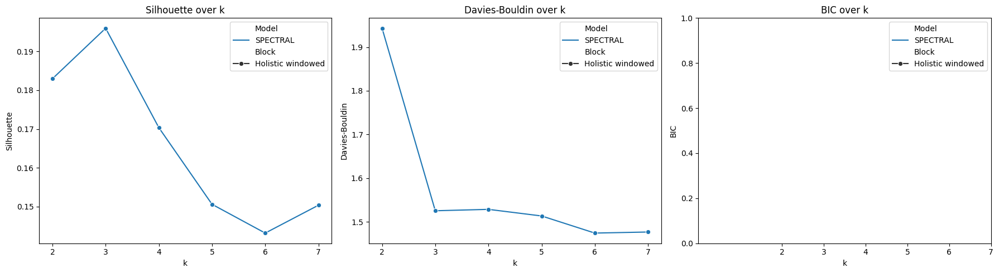


      DEEP CHARACTERIZATION: SPECTRAL on Holistic windowed (3)

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max_loss             1.00105
pct_regain               1.00105
early_wl_speed           1.00105
time_to_nadir_ratio      1.00105
trajectory_volatility    1.00105
lean_loss_coeff          1.00105
muscle_fat_corr          1.00105
observation_gap_ratio    1.00105

Internal Validity Metrics:
  - Silhouette: 0.1960
  - Davies-Bouldin: 1.5254
  - BIC: N/A

--- 2. DIMENSIONALITY REDUCTION ---


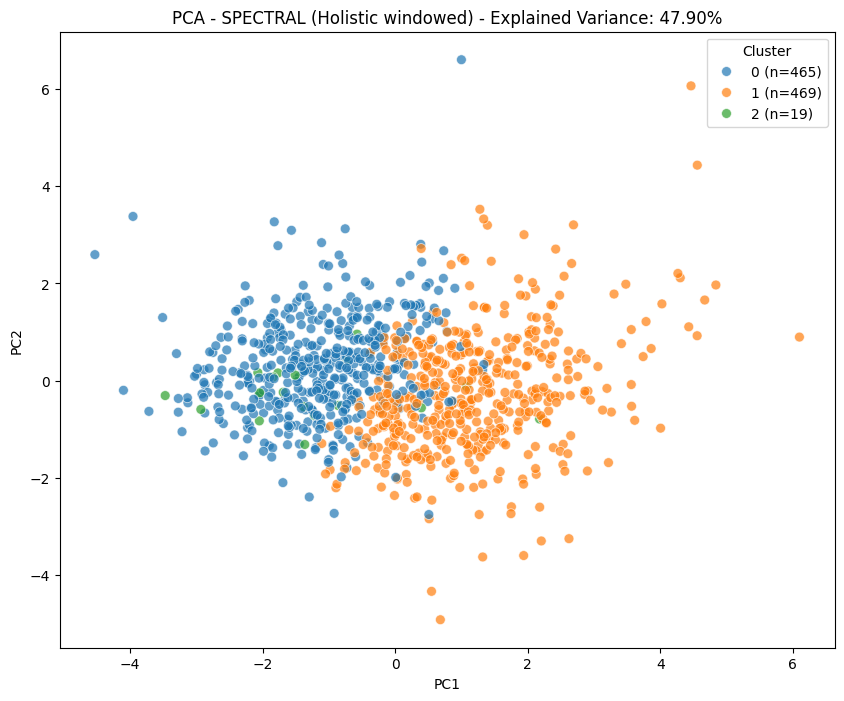

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,0.531334,0.100861
pct_regain,0.438778,0.150937
early_wl_speed,0.142750,0.635532
time_to_nadir_ratio,-0.445283,0.105012
trajectory_volatility,-0.251908,0.414729
lean_loss_coeff,-0.065770,-0.172439
muscle_fat_corr,-0.234958,-0.433734
observation_gap_ratio,0.428387,-0.402809


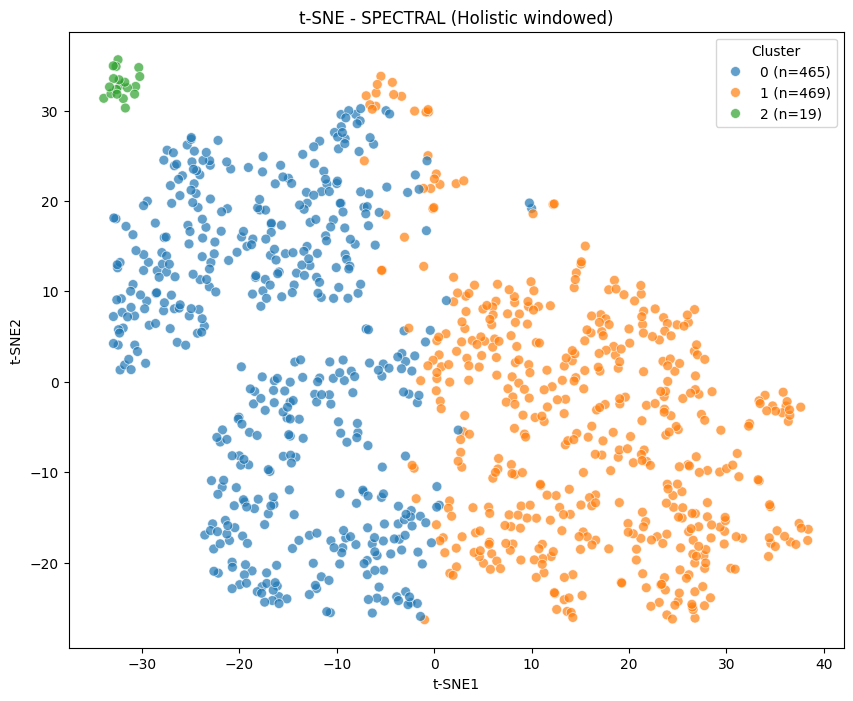

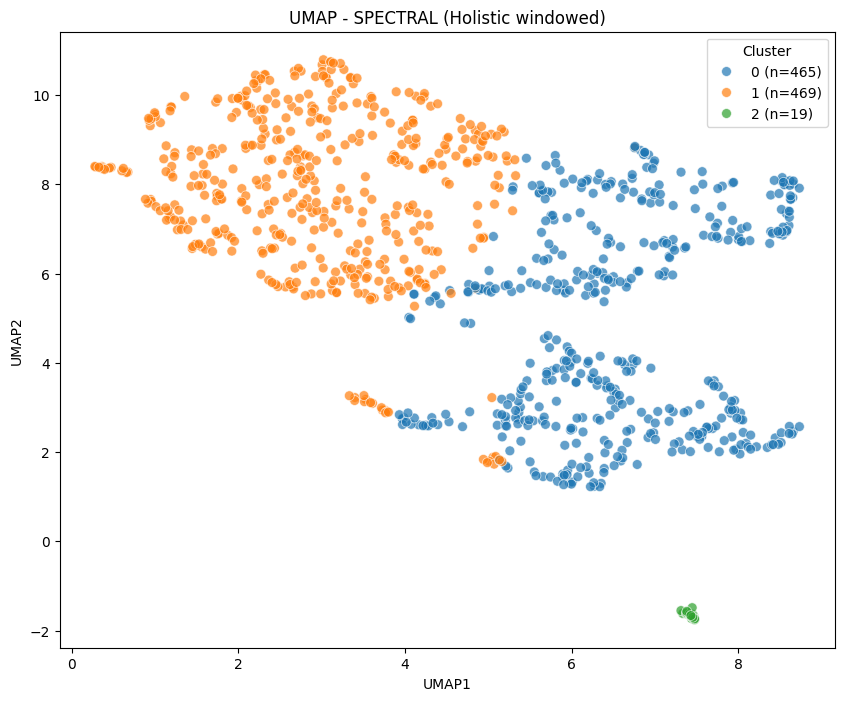


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


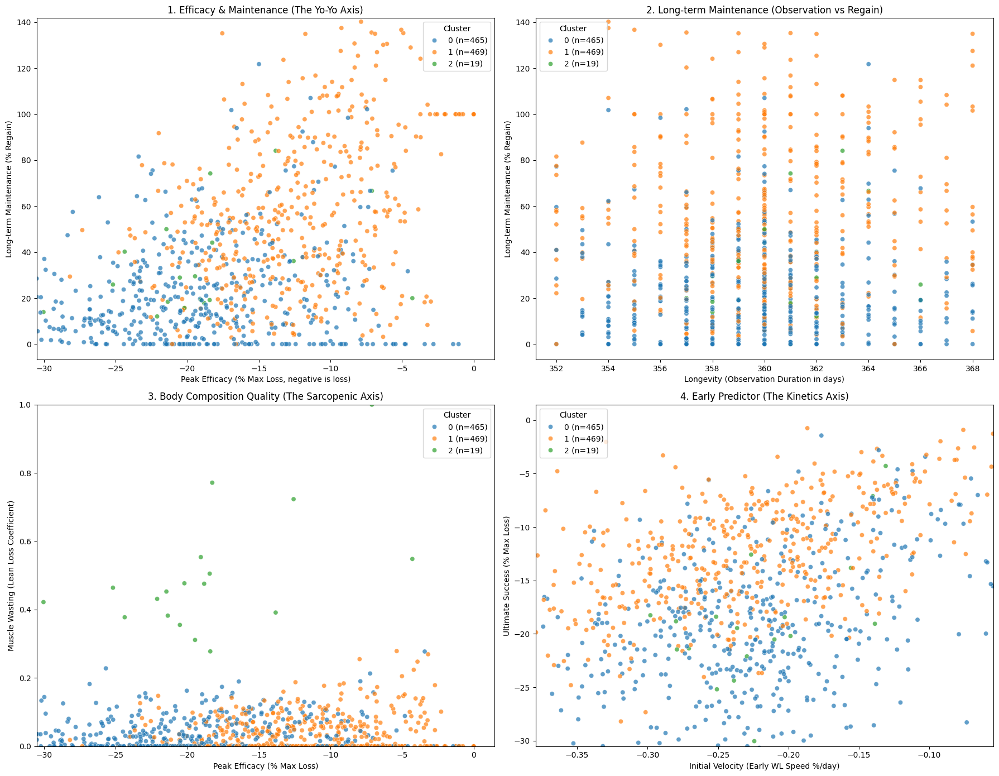


--- 4. TRAJECTORY HOMOGENEITY SAMPLES ---


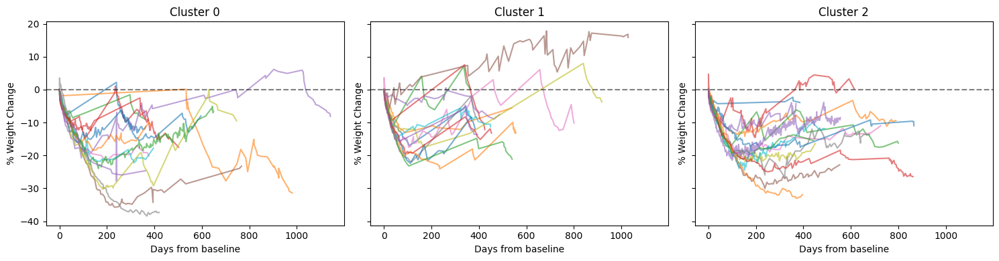

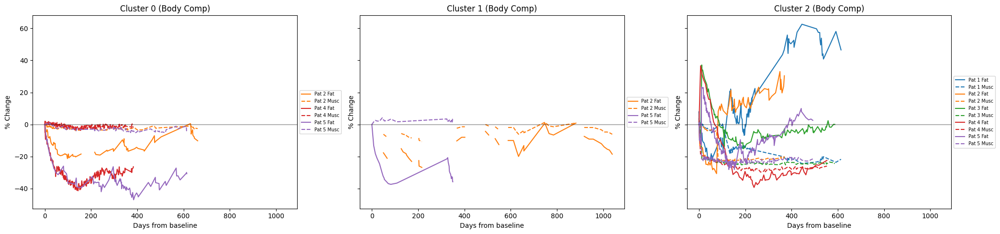


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...

--- CLUSTER SIZES ---
cluster_id
0    465
1    469
2     19
---------------------

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                  953
Model:                        MNLogit   Df Residuals:                      945
Method:                           MLE   Df Model:                            6
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:                 0.04421
Time:                        10:14:16   Log-Likelihood:                -707.85
converged:                       True   LL-Null:                       -740.59
Covariance Type:            nonrobust   LLR p-value:                 3.449e-12
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6679   

,Variable,Cluster 0.0,Cluster 1.0,Cluster 2.0,Dropout,p_value
0,Cluster Size (N),465,469,19,13562,N/A
1,age_when_creating_record,49.00 (43.00-55.00),49.00 (43.00-55.00),48.00 (44.00-54.00),47.00 (40.00-54.00),<0.001
2,sex_f,81.7%,78.3%,89.5%,79.3%,0.720
3,height_m,1.64 (1.60-1.70),1.65 (1.60-1.71),1.61 (1.58-1.67),1.65 (1.60-1.70),0.031
4,wc_cm_confirm_time,102.00 (95.00-110.00),99.00 (90.00-108.00),100.00 (95.00-102.00),100.00 (91.00-109.00),0.258
5,nr_medical_records_patient,2.00 (1.00-3.00),2.00 (2.00-3.00),2.00 (1.00-2.00),1.00 (1.00-2.00),<0.001
6,dietitian_visits,9.00 (4.00-14.00),4.00 (2.00-8.00),11.00 (5.50-19.00),3.00 (2.00-6.00),<0.001
7,womens_health_and_pregnancy,18.8%,26.4%,33.3%,27.2%,0.781
8,mental_health,18.8%,27.8%,0.0%,24.2%,0.797
9,family_issues,7.5%,6.9%,0.0%,5.0%,0.995


In [9]:
# -------------------------------------------------------------------------
# Feature-Based Clustering: 3. The Time-Windowed End-to-End Wrapper
# -------------------------------------------------------------------------
%load_ext autoreload
%autoreload 2

import pandas as pd
from feature_extraction import extract_features
from clustering_pipeline import run_clustering_pipeline

# --- CONFIGURATION ---
DB_PATH = '../dbs/pnk_db2_filtered.sqlite'
ID_COL = 'patient_id' # 'patient_id' for whole patient histories, or 'medical_record_id' for single treatment episodes

WINDOWS = [30, 90, 180, 360]  # The time windows to test (in days)
TOLERANCE = 10            # +/- days tolerance around the window to find a measurement

# Grid Search Config for each window
BLOCKS = ['Holistic windowed'] # prefers this feature block, features optimized for uniform observation length
MODELS = ['SPECTRAL'] # accepts: 'GMM', 'WARD', 'KMEANS', 'SPECTRAL', 'HDBSCAN', 'UMAP_HDBSCAN' - expected to work better with spectral and density-based methods
K_RANGE = range(2,8) # accepts integers
# ---------------------

for window in WINDOWS:
    print("\n" + "="*80)
    print(f"               RUNNING TIME-WINDOW PIPELINE: {window} DAYS (+/- {TOLERANCE})")
    print("="*80)
    
    # 1. Truncate trajectories and extract features
    df_features, df_excluded = extract_features(
        db_path=DB_PATH, 
        id_col=ID_COL, 
        time_window=window, 
        window_tolerance=TOLERANCE
    )
    
    print(f"\nExtracted {len(df_features)} valid trajectories for the {window}-day window.")
    print(f"Excluded {len(df_excluded)} entities (these will appear as 'Dropout').")
    
    # 2. Run clustering and full evaluation (Grid search + visualization + clinical tables)
    if len(df_features) > 50:
        run_clustering_pipeline(
            df_features=df_features, 
            db_path=DB_PATH,
            id_col=ID_COL,
            blocks=BLOCKS, 
            models=MODELS, 
            k_range=K_RANGE
        )
    else:
        print("Not enough surviving trajectories to cluster for this window.")


#### specifics - spectral, k=3

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload

               RUNNING TIME-WINDOW PIPELINE: 30 DAYS (+/- 10)
Fetching raw longitudinal measurements at the patient_id level...
Initial data: 14515 patient_ids, 396210 measurements.
After dropping missing weight/fat/muscle entries: 14438 patient_ids, 360306 measurements.
Dropped 5074 same-day duplicate measurements (kept highest weight). Remaining: 14438 patient_ids, 355232 measurements.
Processing 14438 patient_id units for feature extraction...

--- Feature Extraction Summary ---
Retained: 5251 patient_id units for clustering.
Excluded: 9187 patient_id units (due to early attrition: < 30 days follow-up OR < 3 total measurements).

Extracted 5251 valid trajectories for the 30-day window.
Excluded 9187 entities (these will appear as 'Dropout').
               SINGLE RUN: SPECTRAL on Holistic windowed           

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max

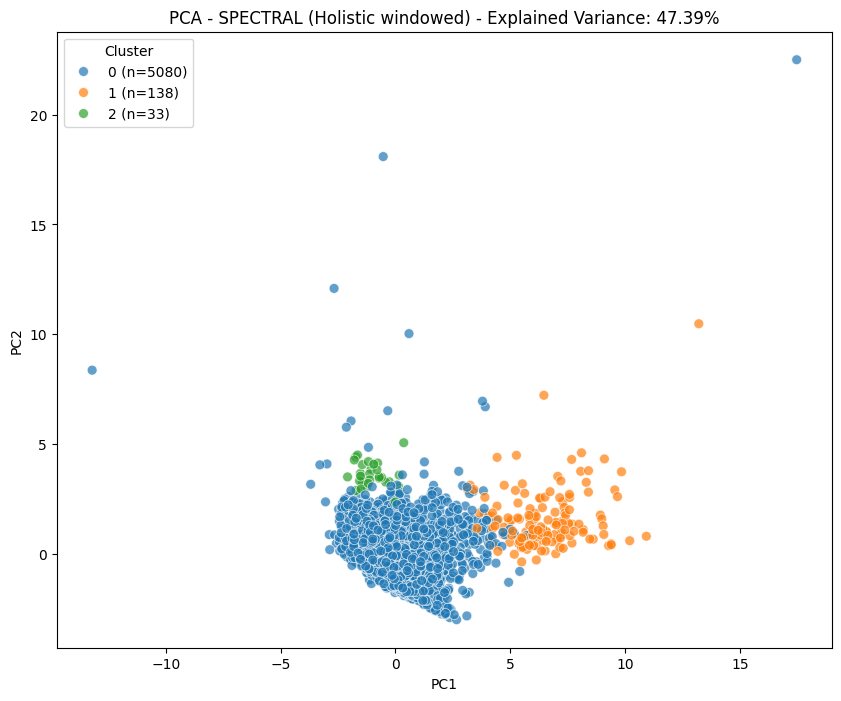

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,0.489847,-0.343424
pct_regain,0.507387,0.289513
early_wl_speed,0.410328,-0.164358
time_to_nadir_ratio,-0.494859,-0.326841
trajectory_volatility,0.076289,0.459137
lean_loss_coeff,-0.059894,0.417307
muscle_fat_corr,-0.098652,0.514428
observation_gap_ratio,0.264979,-0.121719


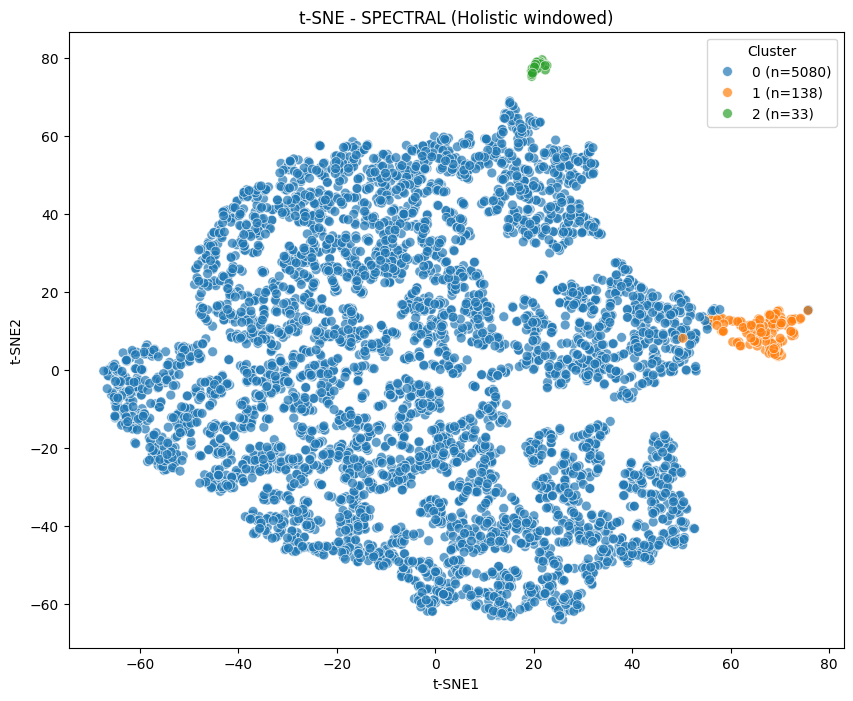

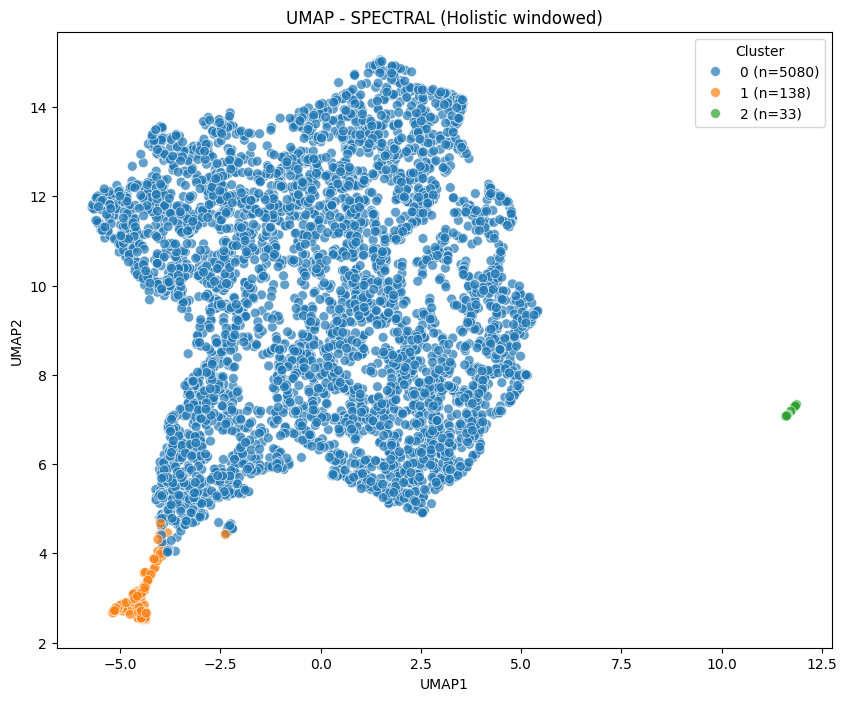


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


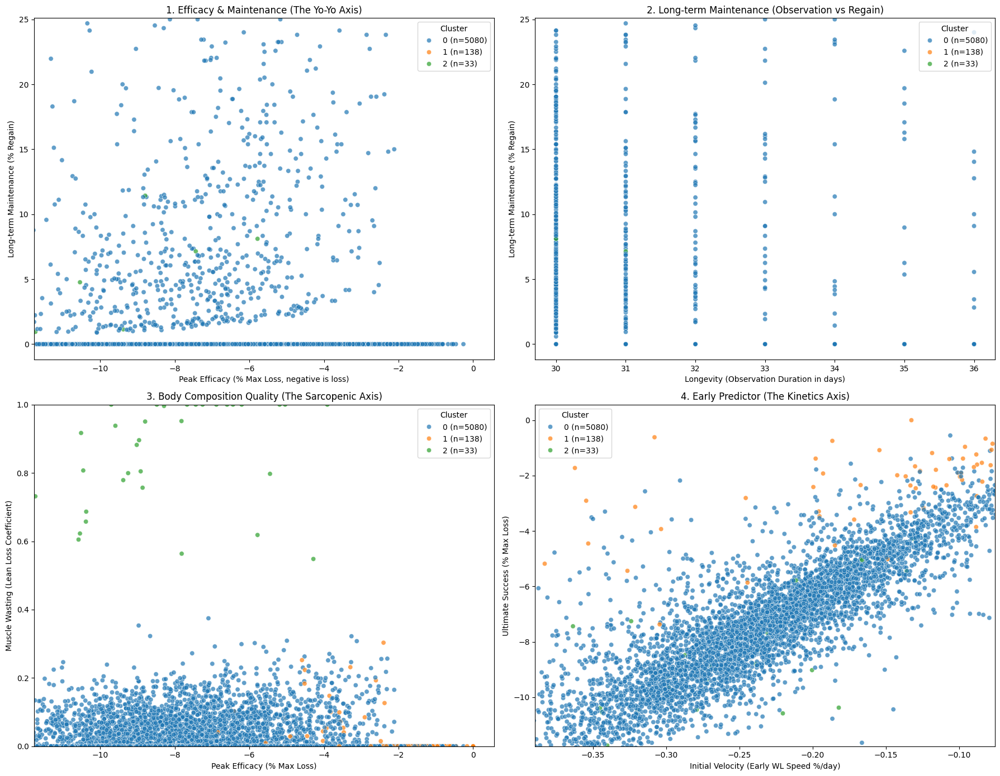


--- 4. TRAJECTORY HOMOGENEITY SAMPLES (GLOBAL) ---


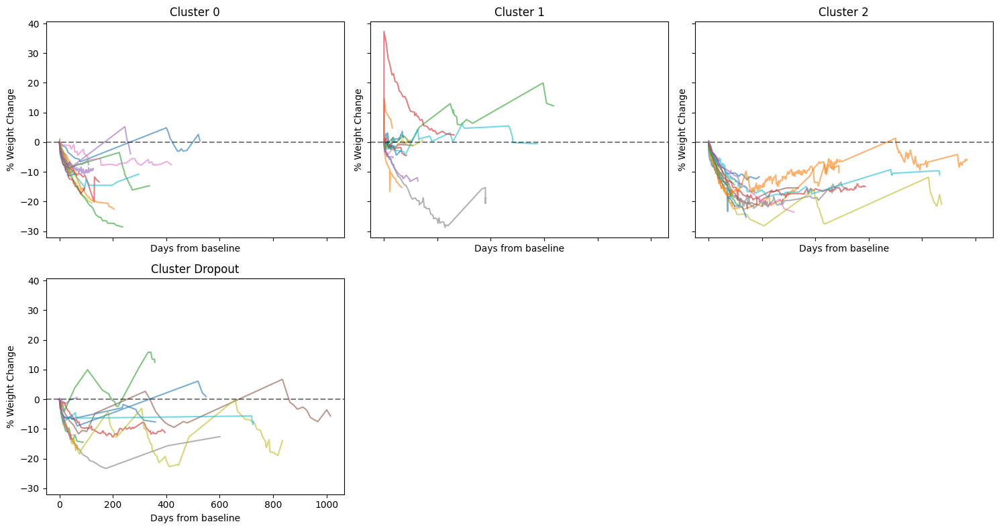

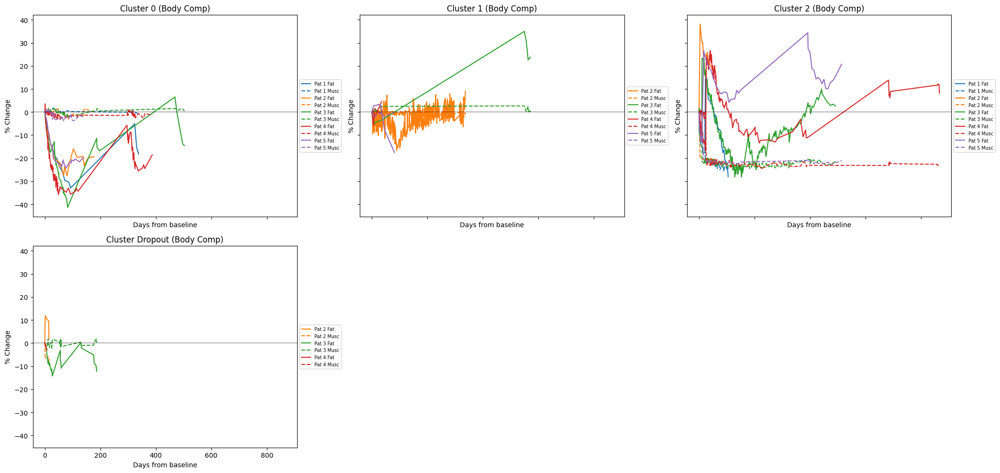


--- 4.1 TRAJECTORY HOMOGENEITY SAMPLES (30d TRUNCATED) ---


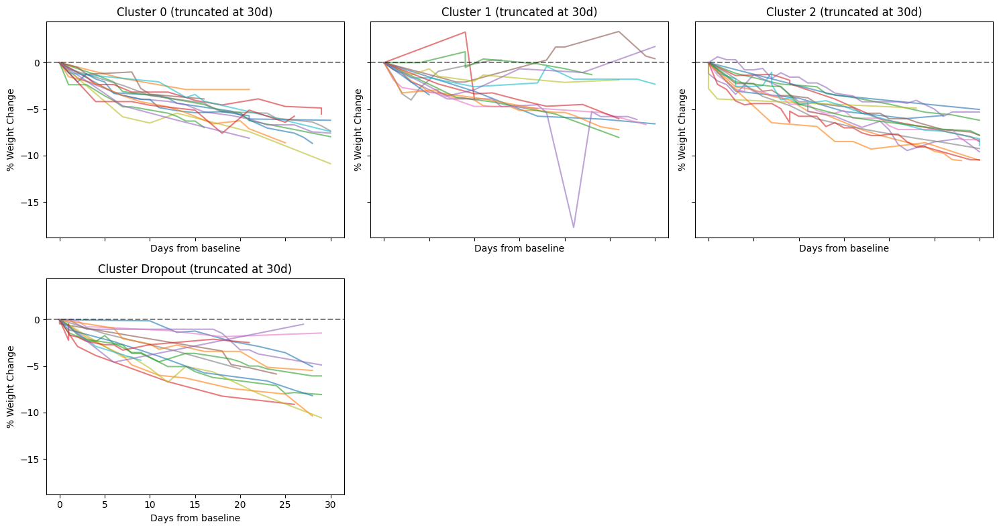

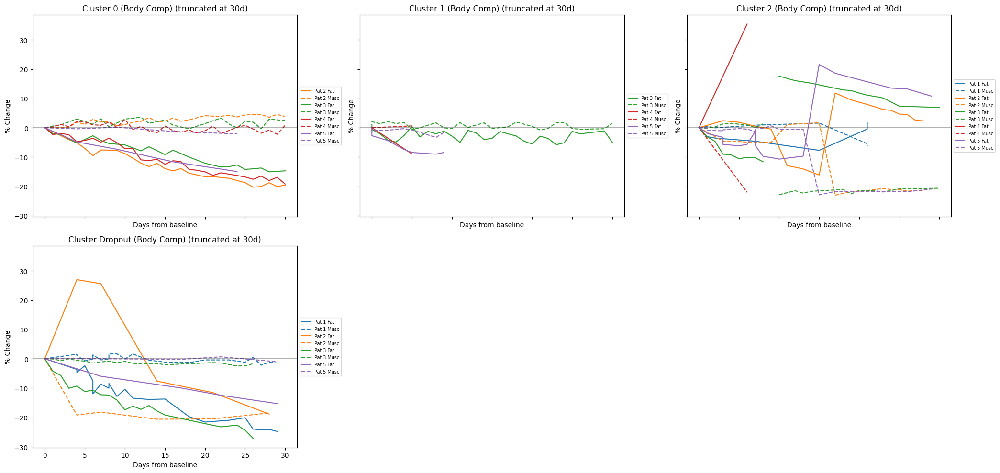


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...

--- CLUSTER SIZES ---
cluster_id
0    5080
1     138
2      33
---------------------

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                 5251
Model:                        MNLogit   Df Residuals:                     5243
Method:                           MLE   Df Model:                            6
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:                 0.01743
Time:                        12:46:27   Log-Likelihood:                -823.05
converged:                      False   LL-Null:                       -837.65
Covariance Type:            nonrobust   LLR p-value:                 5.557e-05
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -5.8621

,Variable,Cluster 0.0,Cluster 1.0,Cluster 2.0,Dropout,p_value
0,Cluster Size (N),5080,138,33,9264,N/A
1,age_when_creating_record,47.00 (41.00-54.00),49.00 (41.25-55.77),45.00 (40.00-52.00),47.00 (40.00-54.00),0.143
2,sex_f,76.9%,84.1%,100.0%,80.5%,<0.001
3,height_m,1.65 (1.60-1.71),1.65 (1.60-1.70),1.63 (1.59-1.68),1.65 (1.60-1.70),<0.001
4,wc_cm_confirm_time,100.00 (91.00-109.00),100.00 (92.00-110.25),99.50 (95.75-103.25),100.00 (91.00-109.75),0.994
5,nr_medical_records_patient,1.00 (1.00-2.00),1.00 (1.00-2.00),1.00 (1.00-2.00),1.00 (1.00-2.00),<0.001
6,dietitian_visits,4.00 (2.00-7.00),2.50 (1.00-5.00),6.00 (4.00-8.00),3.00 (1.00-6.00),<0.001
7,womens_health_and_pregnancy,28.3%,25.9%,50.0%,26.0%,0.959
8,mental_health,23.8%,18.5%,0.0%,24.4%,0.993
9,family_issues,5.6%,3.7%,0.0%,4.9%,0.993



               RUNNING TIME-WINDOW PIPELINE: 90 DAYS (+/- 10)
Fetching raw longitudinal measurements at the patient_id level...
Initial data: 14515 patient_ids, 396210 measurements.
After dropping missing weight/fat/muscle entries: 14438 patient_ids, 360306 measurements.
Dropped 5074 same-day duplicate measurements (kept highest weight). Remaining: 14438 patient_ids, 355232 measurements.
Processing 14438 patient_id units for feature extraction...

--- Feature Extraction Summary ---
Retained: 6540 patient_id units for clustering.
Excluded: 7898 patient_id units (due to early attrition: < 30 days follow-up OR < 3 total measurements).

Extracted 6540 valid trajectories for the 90-day window.
Excluded 7898 entities (these will appear as 'Dropout').
               SINGLE RUN: SPECTRAL on Holistic windowed           

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max_loss             1.000153
pct_regain               1.000153
early_wl_speed           1.

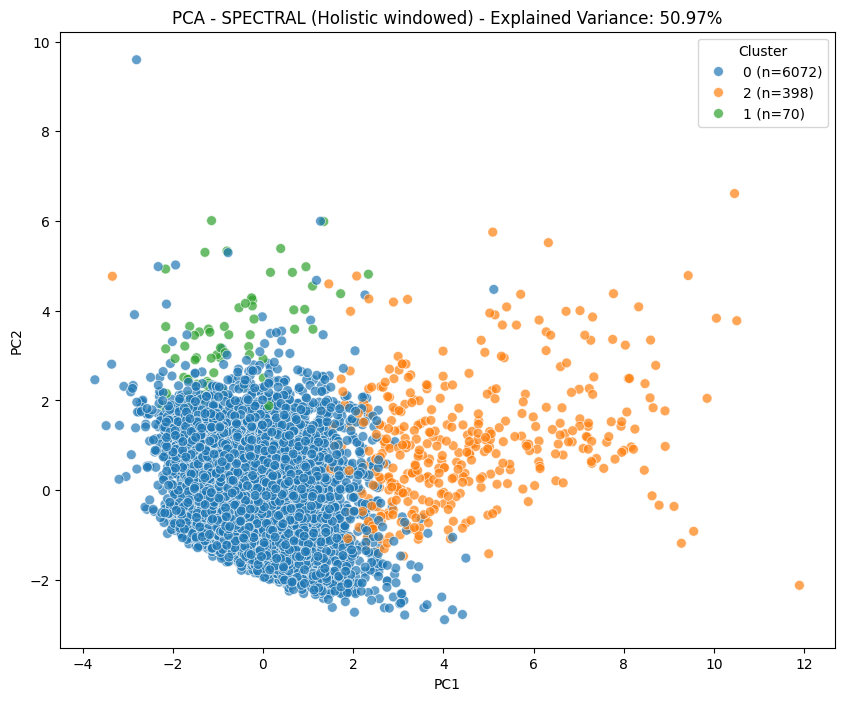

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,0.520034,-0.107360
pct_regain,0.469897,0.273987
early_wl_speed,0.301238,-0.281987
time_to_nadir_ratio,-0.457947,-0.341393
trajectory_volatility,-0.162061,0.311331
lean_loss_coeff,-0.041194,0.528900
muscle_fat_corr,-0.137310,0.583333
observation_gap_ratio,0.401855,0.019983


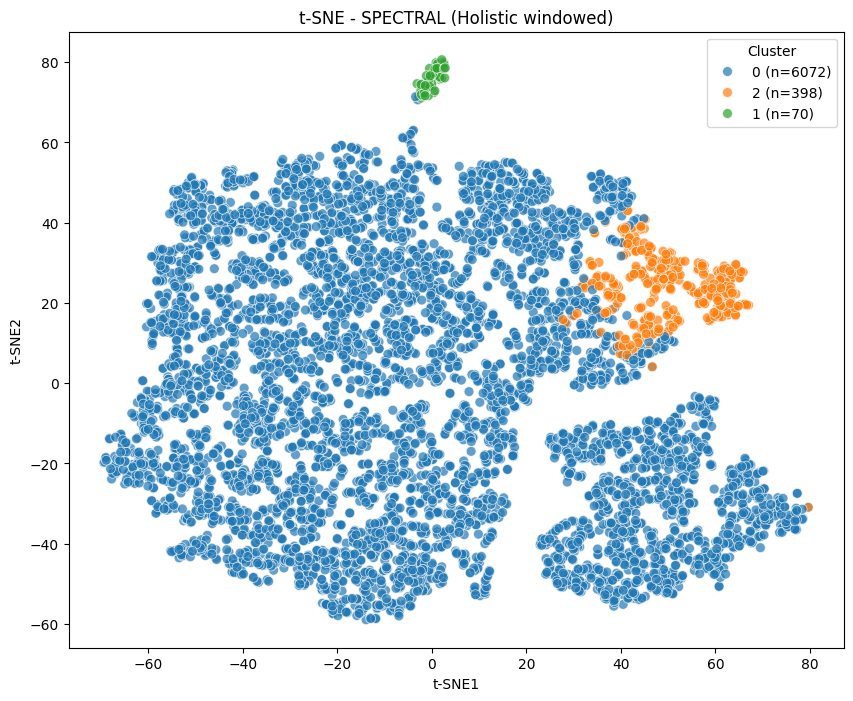

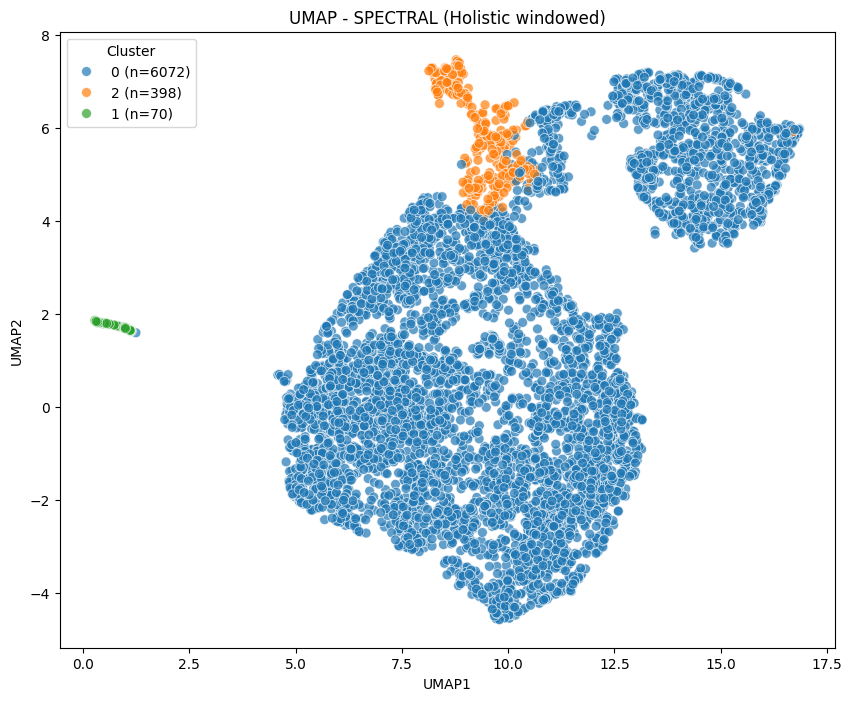


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


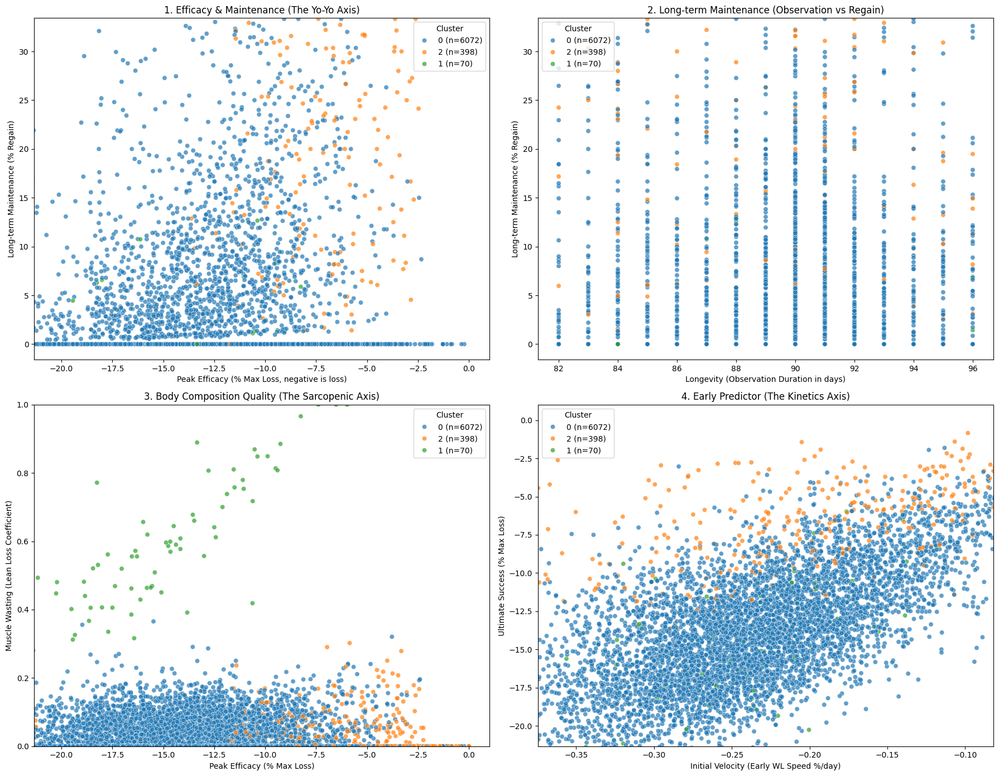


--- 4. TRAJECTORY HOMOGENEITY SAMPLES (GLOBAL) ---


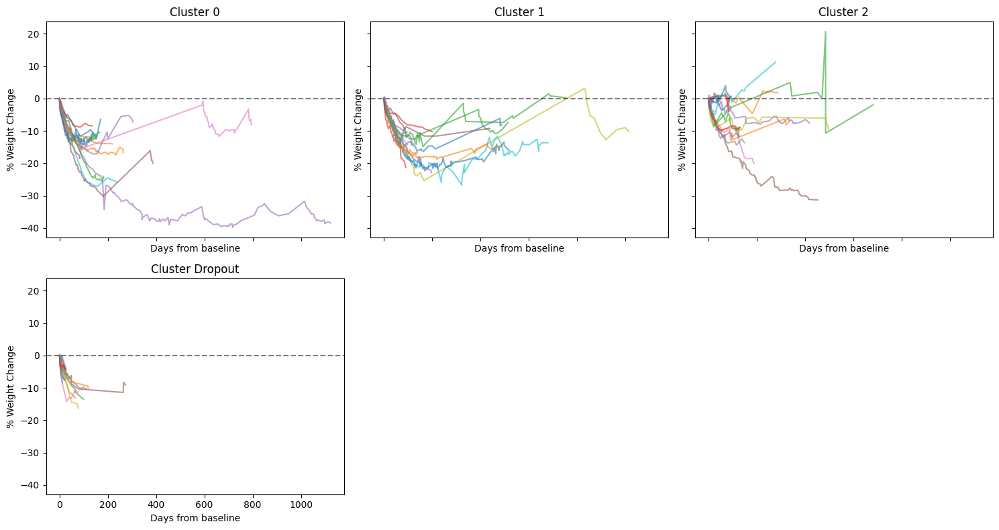

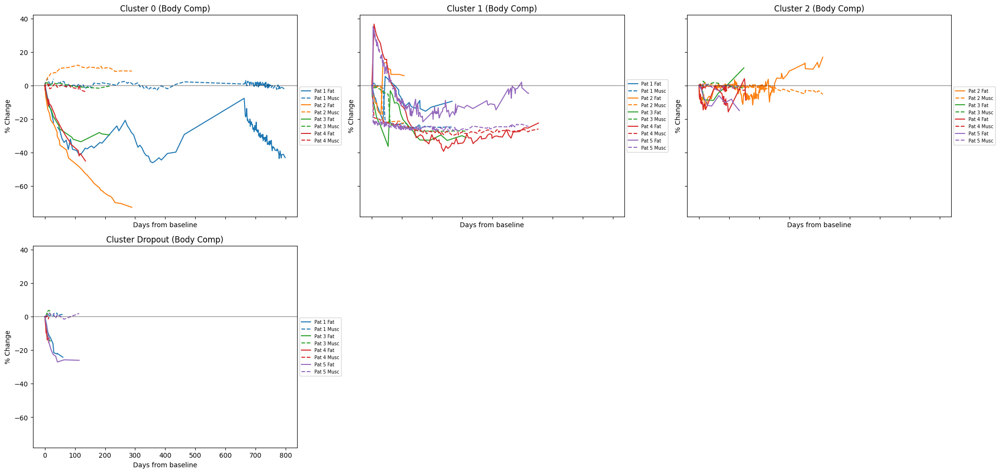


--- 4.1 TRAJECTORY HOMOGENEITY SAMPLES (90d TRUNCATED) ---


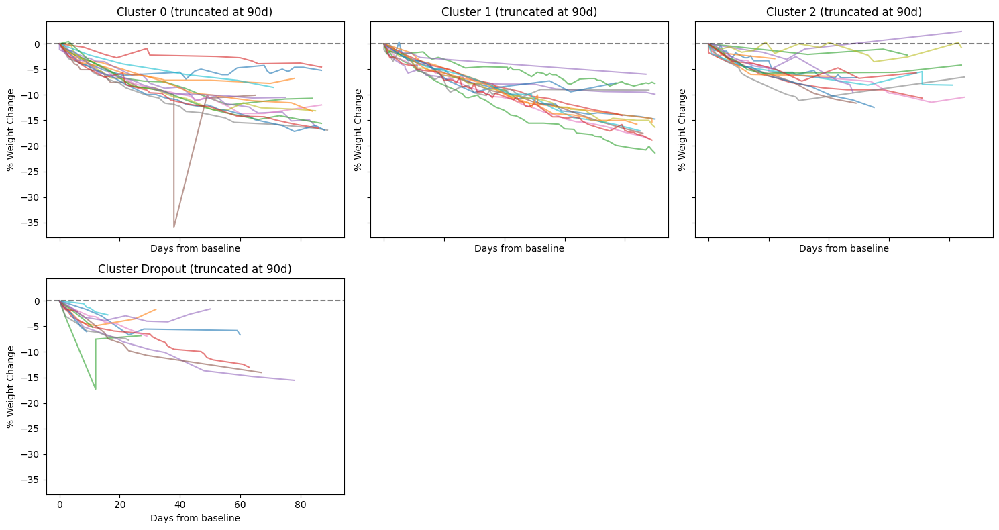

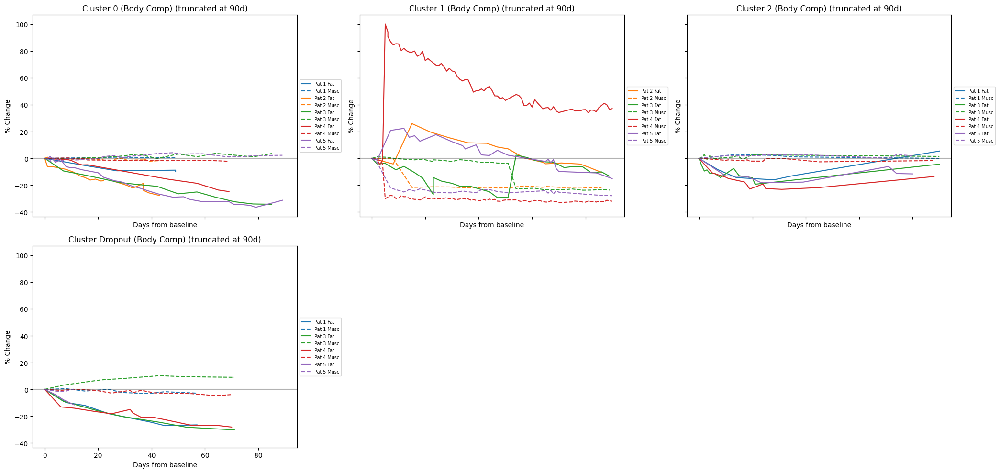


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...

--- CLUSTER SIZES ---
cluster_id
0    6072
1      70
2     398
---------------------

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                 6540
Model:                        MNLogit   Df Residuals:                     6532
Method:                           MLE   Df Model:                            6
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:                0.008175
Time:                        12:47:30   Log-Likelihood:                -1867.2
converged:                       True   LL-Null:                       -1882.5
Covariance Type:            nonrobust   LLR p-value:                 2.792e-05
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -5.9549

,Variable,Cluster 0.0,Cluster 1.0,Cluster 2.0,Dropout,p_value
0,Cluster Size (N),6072,70,398,7975,N/A
1,age_when_creating_record,48.00 (41.00-55.00),46.50 (40.00-53.50),48.50 (41.25-55.00),46.00 (39.00-53.00),<0.001
2,sex_f,79.0%,98.6%,81.9%,79.2%,0.002
3,height_m,1.65 (1.60-1.70),1.62 (1.59-1.69),1.64 (1.59-1.70),1.65 (1.60-1.70),0.012
4,wc_cm_confirm_time,101.00 (92.00-110.00),100.00 (93.00-104.00),100.00 (90.00-107.00),100.00 (90.00-109.00),<0.001
5,nr_medical_records_patient,1.00 (1.00-2.00),1.00 (1.00-2.00),1.00 (1.00-2.00),1.00 (1.00-2.00),<0.001
6,dietitian_visits,5.00 (3.00-8.00),6.50 (4.00-10.00),3.00 (2.00-7.00),2.00 (1.00-4.00),<0.001
7,womens_health_and_pregnancy,24.7%,40.0%,22.7%,28.7%,0.284
8,mental_health,25.3%,10.0%,24.2%,23.2%,0.801
9,family_issues,6.0%,0.0%,7.6%,4.3%,0.436



               RUNNING TIME-WINDOW PIPELINE: 180 DAYS (+/- 10)
Fetching raw longitudinal measurements at the patient_id level...
Initial data: 14515 patient_ids, 396210 measurements.
After dropping missing weight/fat/muscle entries: 14438 patient_ids, 360306 measurements.
Dropped 5074 same-day duplicate measurements (kept highest weight). Remaining: 14438 patient_ids, 355232 measurements.
Processing 14438 patient_id units for feature extraction...

--- Feature Extraction Summary ---
Retained: 2561 patient_id units for clustering.
Excluded: 11877 patient_id units (due to early attrition: < 30 days follow-up OR < 3 total measurements).

Extracted 2561 valid trajectories for the 180-day window.
Excluded 11877 entities (these will appear as 'Dropout').
               SINGLE RUN: SPECTRAL on Holistic windowed           

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max_loss             1.000391
pct_regain               1.000391
early_wl_speed         

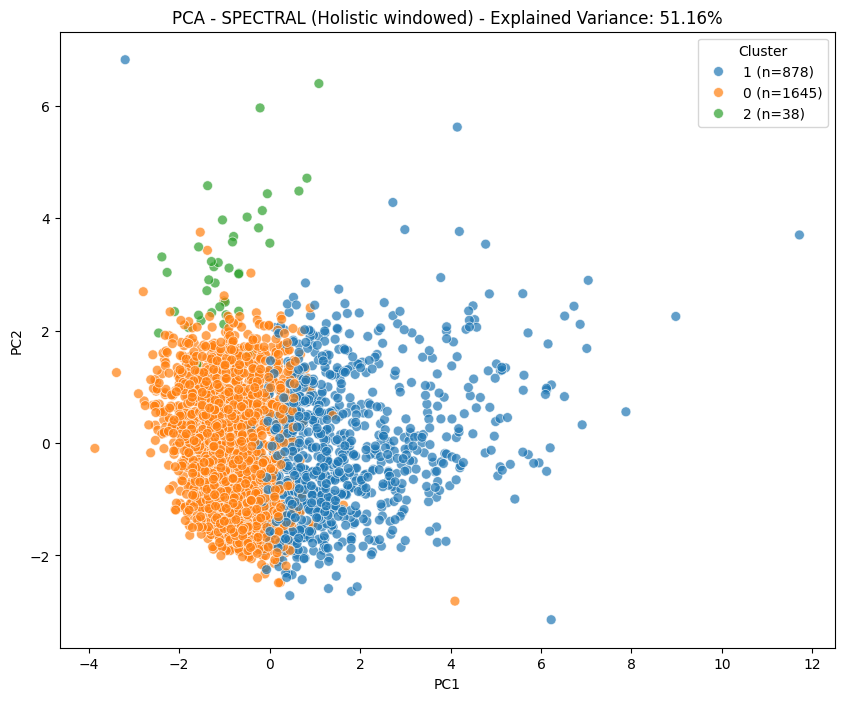

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,0.524036,-0.054995
pct_regain,0.477596,0.190039
early_wl_speed,0.200064,-0.380576
time_to_nadir_ratio,-0.476842,-0.263562
trajectory_volatility,-0.117386,0.082155
lean_loss_coeff,-0.048759,0.583269
muscle_fat_corr,-0.171636,0.627093
observation_gap_ratio,0.429265,0.079750


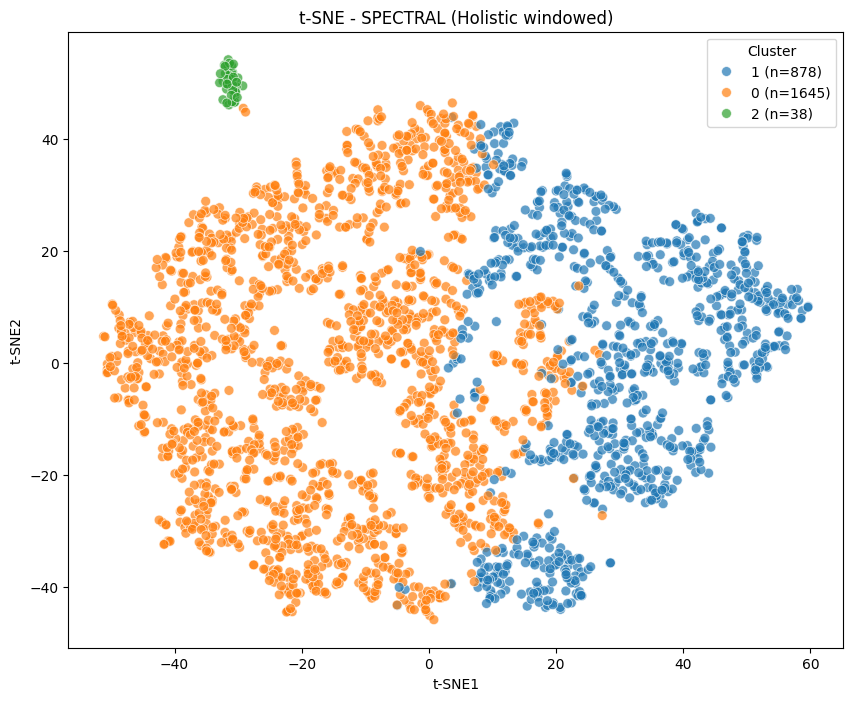

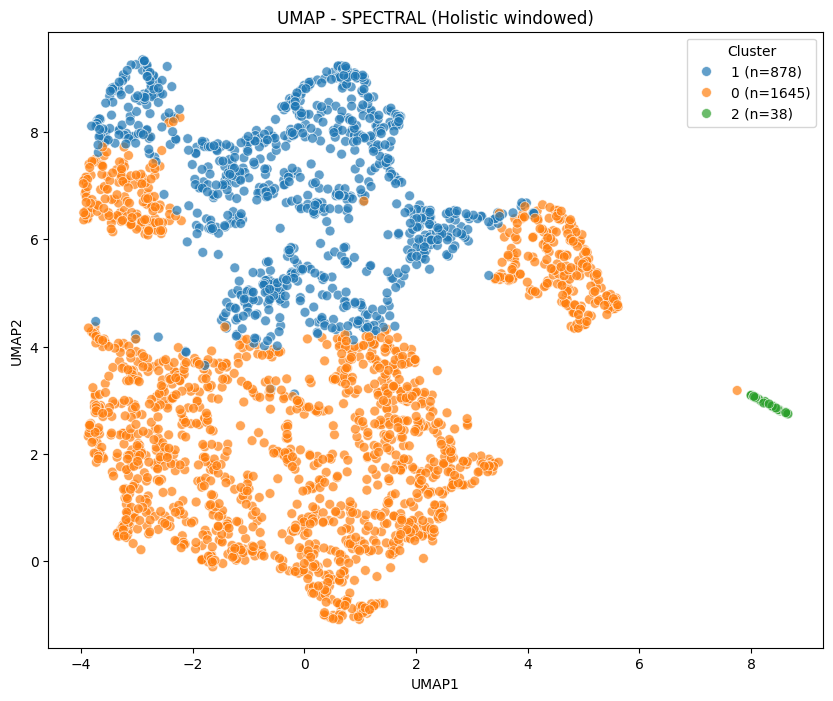


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


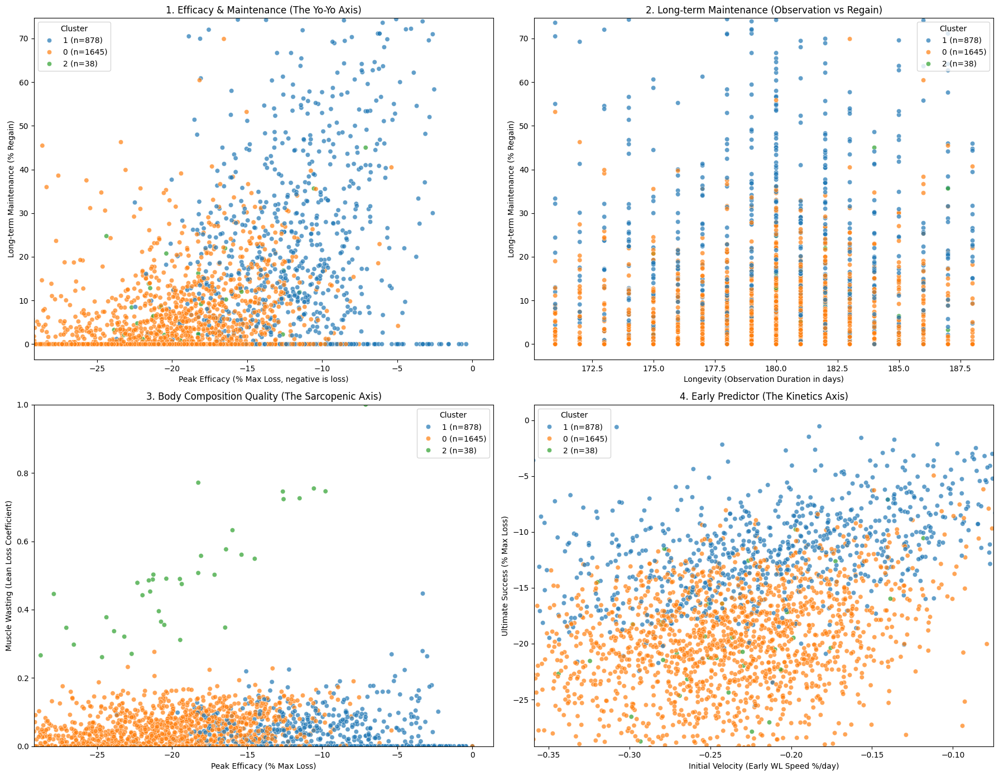


--- 4. TRAJECTORY HOMOGENEITY SAMPLES (GLOBAL) ---


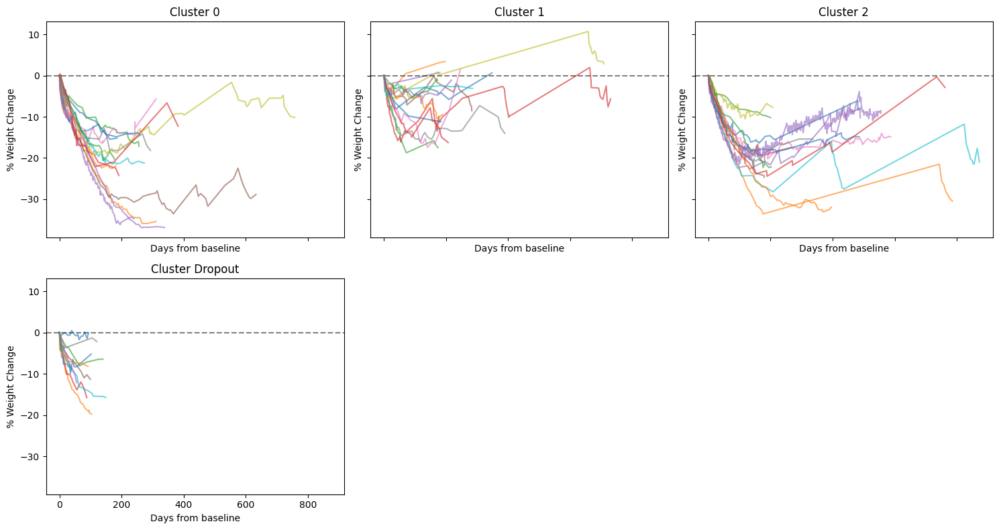

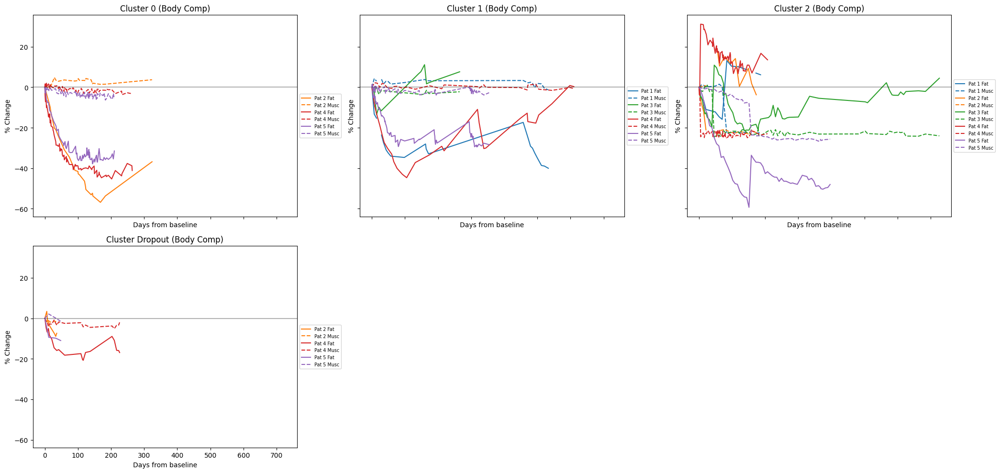


--- 4.1 TRAJECTORY HOMOGENEITY SAMPLES (180d TRUNCATED) ---


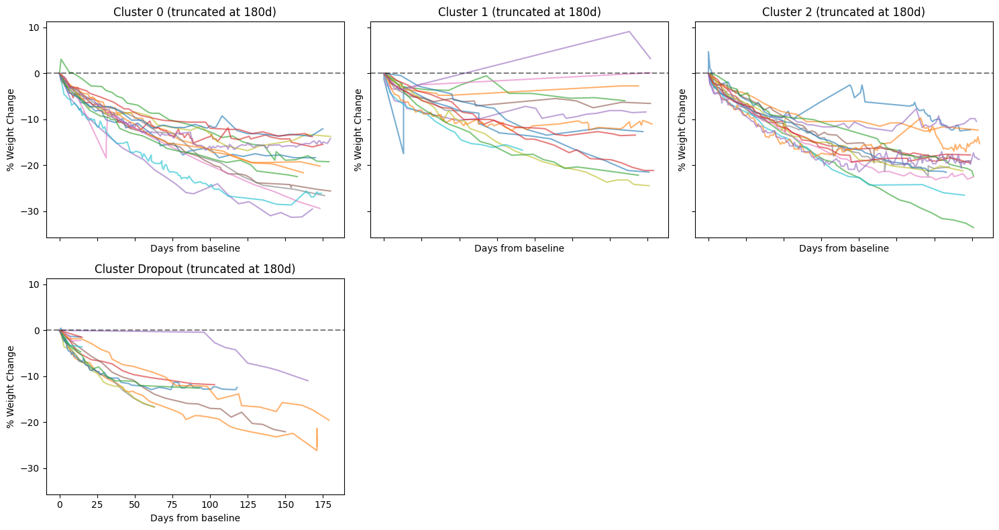

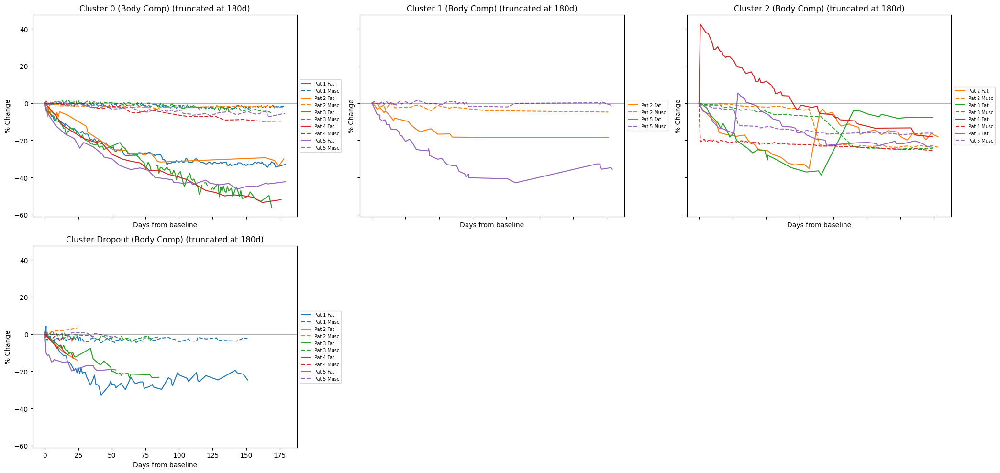


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...

--- CLUSTER SIZES ---
cluster_id
0    1645
1     878
2      38
---------------------

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                 2561
Model:                        MNLogit   Df Residuals:                     2553
Method:                           MLE   Df Model:                            6
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:                0.004209
Time:                        12:48:17   Log-Likelihood:                -1820.4
converged:                       True   LL-Null:                       -1828.1
Covariance Type:            nonrobust   LLR p-value:                   0.01743
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.1583

,Variable,Cluster 0.0,Cluster 1.0,Cluster 2.0,Dropout,p_value
0,Cluster Size (N),1645,878,38,11954,N/A
1,age_when_creating_record,49.00 (43.00-55.00),49.00 (42.25-55.00),45.00 (42.00-54.75),47.00 (40.00-53.00),<0.001
2,sex_f,81.2%,80.1%,94.7%,79.0%,0.054
3,height_m,1.64 (1.60-1.70),1.65 (1.60-1.70),1.62 (1.59-1.68),1.65 (1.60-1.71),<0.001
4,wc_cm_confirm_time,101.00 (94.00-111.00),101.00 (93.00-109.00),96.00 (90.00-100.00),100.00 (91.00-109.00),0.001
5,nr_medical_records_patient,1.00 (1.00-2.00),2.00 (1.00-2.00),2.00 (1.00-3.00),1.00 (1.00-2.00),<0.001
6,dietitian_visits,7.00 (4.00-11.00),6.00 (3.00-9.00),9.50 (7.00-14.00),3.00 (2.00-5.00),<0.001
7,womens_health_and_pregnancy,23.5%,26.2%,50.0%,27.3%,0.639
8,mental_health,22.8%,24.2%,16.7%,24.3%,0.982
9,family_issues,5.2%,6.7%,0.0%,5.0%,0.950



               RUNNING TIME-WINDOW PIPELINE: 360 DAYS (+/- 10)
Fetching raw longitudinal measurements at the patient_id level...
Initial data: 14515 patient_ids, 396210 measurements.
After dropping missing weight/fat/muscle entries: 14438 patient_ids, 360306 measurements.
Dropped 5074 same-day duplicate measurements (kept highest weight). Remaining: 14438 patient_ids, 355232 measurements.
Processing 14438 patient_id units for feature extraction...

--- Feature Extraction Summary ---
Retained: 953 patient_id units for clustering.
Excluded: 13485 patient_id units (due to early attrition: < 30 days follow-up OR < 3 total measurements).

Extracted 953 valid trajectories for the 360-day window.
Excluded 13485 entities (these will appear as 'Dropout').
               SINGLE RUN: SPECTRAL on Holistic windowed           

--- 1. PREPARING & FITTING ---

--- Scaled Feature Variances (Sanity Check) ---
pct_max_loss             1.00105
pct_regain               1.00105
early_wl_speed           1.

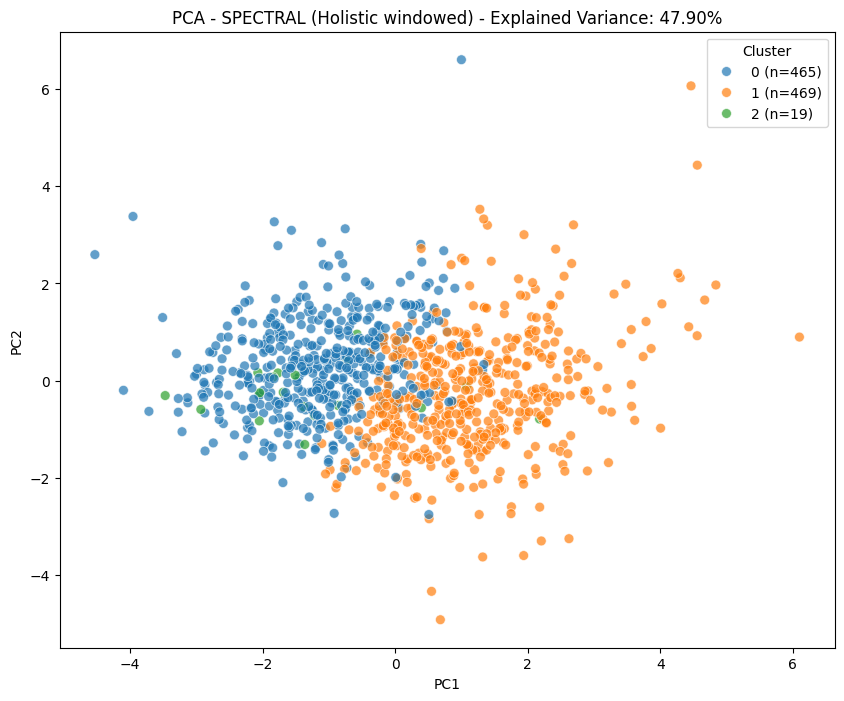

\n--- PCA Loadings (Feature Contributions to Principal Components) ---


,PC1,PC2
pct_max_loss,0.531334,0.100861
pct_regain,0.438778,0.150937
early_wl_speed,0.142750,0.635532
time_to_nadir_ratio,-0.445283,0.105012
trajectory_volatility,-0.251908,0.414729
lean_loss_coeff,-0.065770,-0.172439
muscle_fat_corr,-0.234958,-0.433734
observation_gap_ratio,0.428387,-0.402809


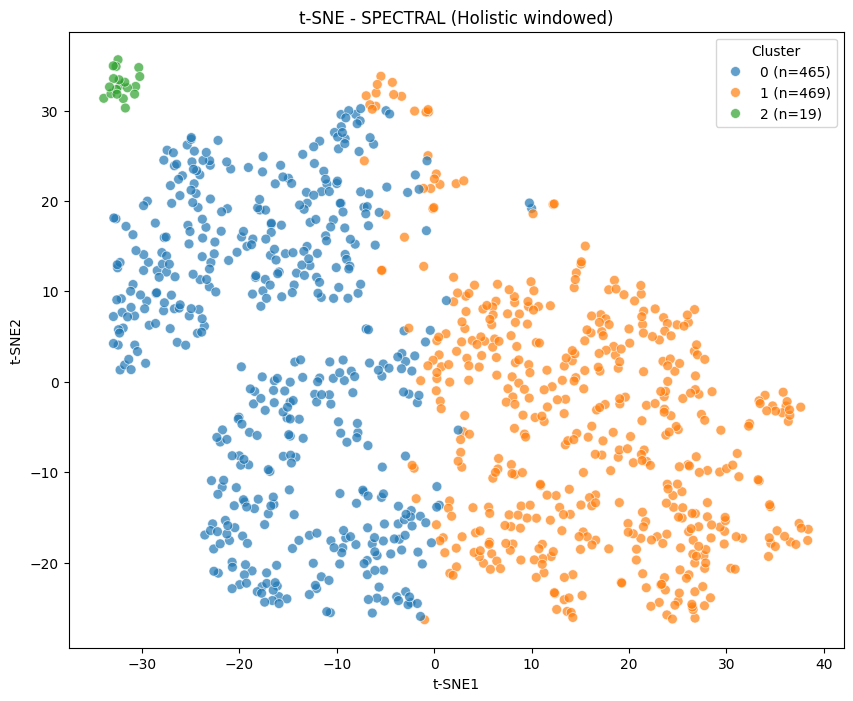

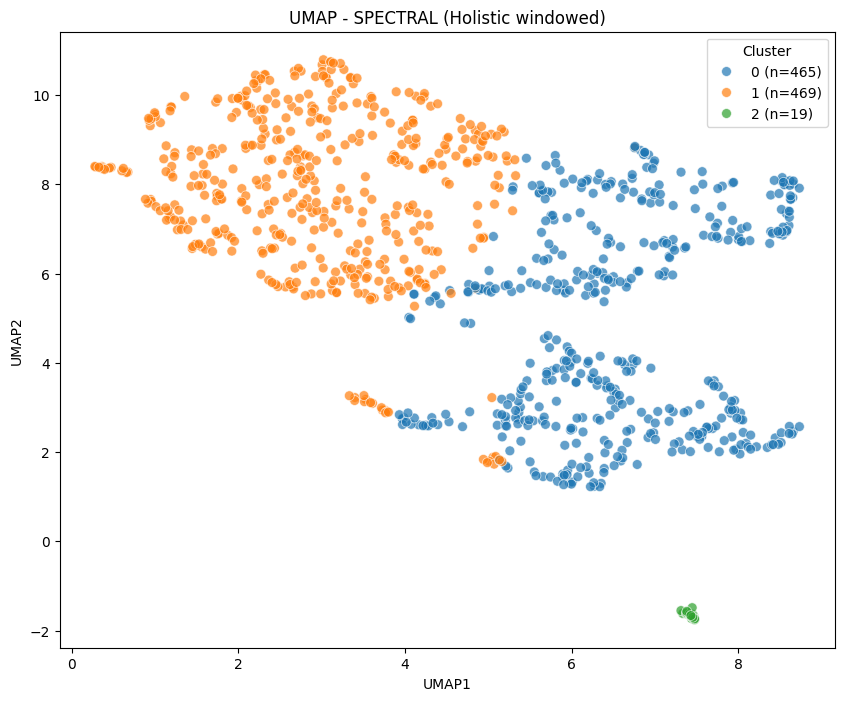


--- 3. CLINICAL CHARACTERIZATION (5th-95th Percentile Capped) ---


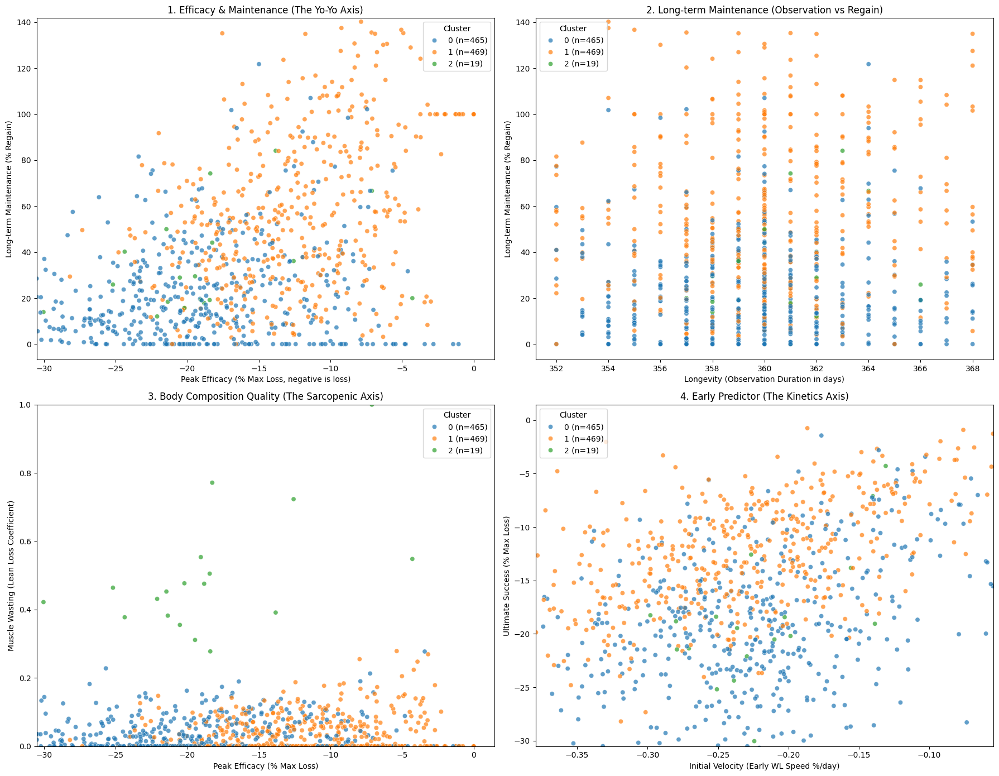


--- 4. TRAJECTORY HOMOGENEITY SAMPLES (GLOBAL) ---


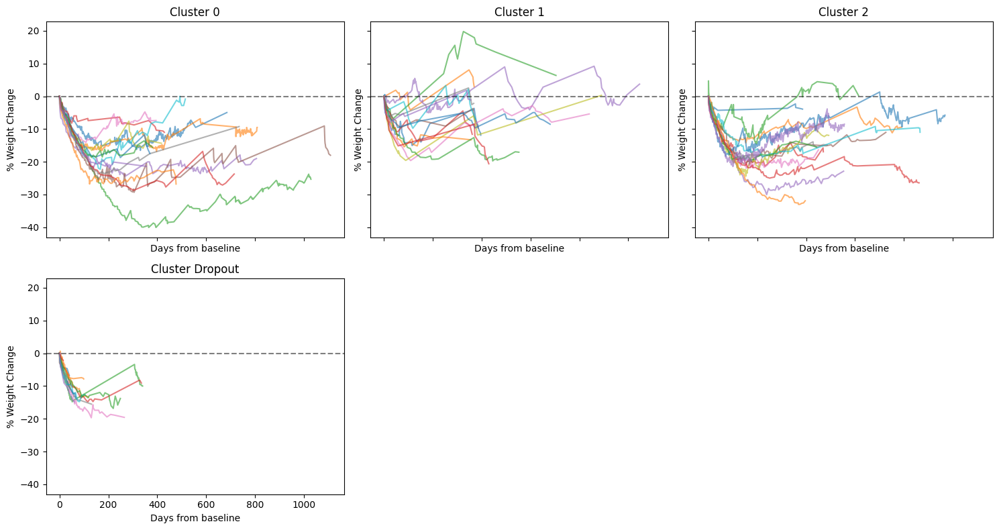

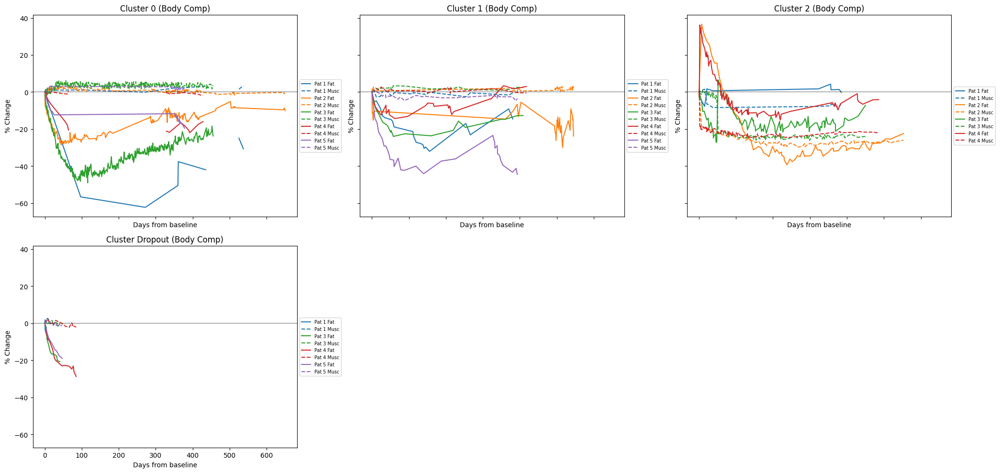


--- 4.1 TRAJECTORY HOMOGENEITY SAMPLES (360d TRUNCATED) ---


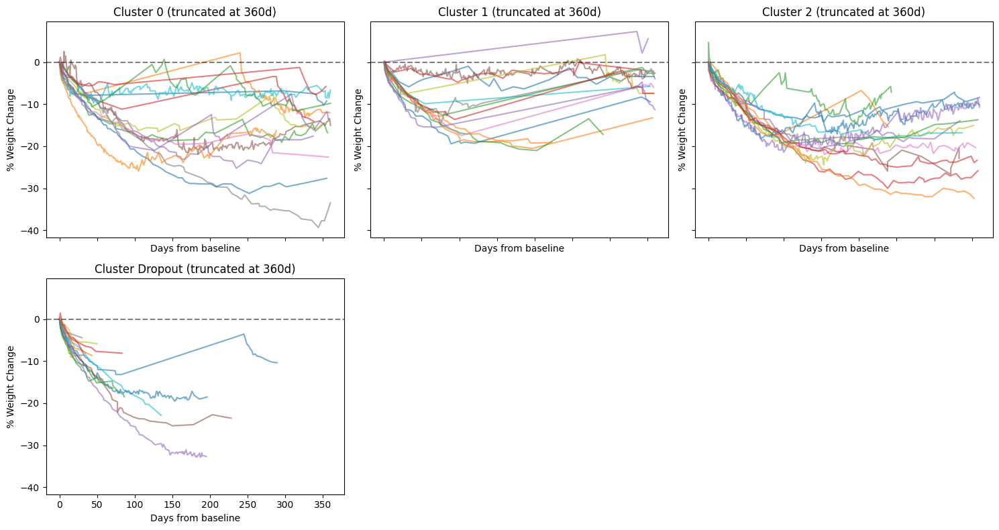

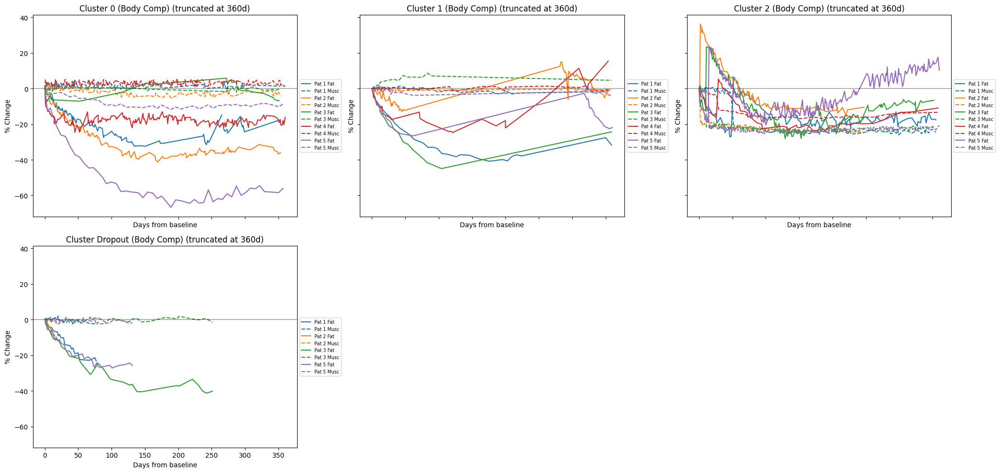


--- 5. PREDICTIVE UTILITY ---
Evaluating predictive utility (baseline characteristics vs cluster)...

--- CLUSTER SIZES ---
cluster_id
0    465
1    469
2     19
---------------------

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                  953
Model:                        MNLogit   Df Residuals:                      945
Method:                           MLE   Df Model:                            6
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:                 0.04421
Time:                        12:48:53   Log-Likelihood:                -707.85
converged:                       True   LL-Null:                       -740.59
Covariance Type:            nonrobust   LLR p-value:                 3.449e-12
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6679   

,Variable,Cluster 0.0,Cluster 1.0,Cluster 2.0,Dropout,p_value
0,Cluster Size (N),465,469,19,13562,N/A
1,age_when_creating_record,49.00 (43.00-55.00),49.00 (43.00-55.00),48.00 (44.00-54.00),47.00 (40.00-54.00),<0.001
2,sex_f,81.7%,78.3%,89.5%,79.3%,0.720
3,height_m,1.64 (1.60-1.70),1.65 (1.60-1.71),1.61 (1.58-1.67),1.65 (1.60-1.70),0.031
4,wc_cm_confirm_time,102.00 (95.00-110.00),99.00 (90.00-108.00),100.00 (95.00-102.00),100.00 (91.00-109.00),0.258
5,nr_medical_records_patient,2.00 (1.00-3.00),2.00 (2.00-3.00),2.00 (1.00-2.00),1.00 (1.00-2.00),<0.001
6,dietitian_visits,9.00 (4.00-14.00),4.00 (2.00-8.00),11.00 (5.50-19.00),3.00 (2.00-6.00),<0.001
7,womens_health_and_pregnancy,18.8%,26.4%,33.3%,27.2%,0.781
8,mental_health,18.8%,27.8%,0.0%,24.2%,0.797
9,family_issues,7.5%,6.9%,0.0%,5.0%,0.995


In [19]:
# -------------------------------------------------------------------------
# Feature-Based Clustering: 3. The Time-Windowed End-to-End Wrapper
# -------------------------------------------------------------------------
%load_ext autoreload
%autoreload 2

import pandas as pd
from feature_extraction import extract_features
from clustering_pipeline import run_clustering_pipeline

# --- CONFIGURATION ---
DB_PATH = '../dbs/pnk_db2_filtered.sqlite'
ID_COL = 'patient_id' # 'patient_id' for whole patient histories, or 'medical_record_id' for single treatment episodes

WINDOWS = [30, 90, 180, 360]  # The time windows to test (in days)
TOLERANCE = 10            # +/- days tolerance around the window to find a measurement

# Grid Search Config for each window
BLOCKS = ['Holistic windowed'] # prefers this feature block, features optimized for uniform observation length
MODELS = ['SPECTRAL'] # accepts: 'GMM', 'WARD', 'KMEANS', 'SPECTRAL', 'HDBSCAN', 'UMAP_HDBSCAN' - expected to work better with spectral and density-based methods
K_RANGE = 3 #range(2,8) # accepts integers
# ---------------------

for window in WINDOWS:
    print("\n" + "="*80)
    print(f"               RUNNING TIME-WINDOW PIPELINE: {window} DAYS (+/- {TOLERANCE})")
    print("="*80)
    
    # 1. Truncate trajectories and extract features
    df_features, df_excluded = extract_features(
        db_path=DB_PATH, 
        id_col=ID_COL, 
        time_window=window, 
        window_tolerance=TOLERANCE
    )
    
    print(f"\nExtracted {len(df_features)} valid trajectories for the {window}-day window.")
    print(f"Excluded {len(df_excluded)} entities (these will appear as 'Dropout').")
    
    # 2. Run clustering and full evaluation (Grid search + visualization + clinical tables)
    if len(df_features) > 50:
        df_clusters_out = run_clustering_pipeline(
            df_features=df_features, 
            db_path=DB_PATH,
            id_col=ID_COL,
            blocks=BLOCKS, 
            models=MODELS, 
            k_range=K_RANGE,            
            time_window=window,          # <--- NEW: Tells it to plot the truncated versions
            df_excluded=df_excluded      # <--- NEW: Passes the dropouts to be plotted
        )
    else:
        print("Not enough surviving trajectories to cluster for this window.")


In [20]:
# Grab the IDs of the muscle-wasters to investigate the raw data
suspect_ids = df_clusters_out[df_clusters_out['cluster_id'] == 2][ID_COL].tolist()
print(f"Cluster 2 IDs to investigate: \n{suspect_ids}")


Cluster 2 IDs to investigate: 
['98A2074CEB969', '98A92F4CEB969', '98BA924CEB969', '99B3B34CEB969', '99B4684CEB969', '99B91D4CEB969', '99BB144CEB969', '99BE444CEB969', '99D8AE4CEB969', '99D8BD4CEB969', '99D8C34CEB969', '99E5734CEB969', '99E5854CEB969', '99E5DC4CEB969', '99EA184CEB969', '99EA454CEB969', '9A0F0B4CEB969', '9A151F4CEB969', '9A5A364CEB969']


### Trajectory clustering with DTW

#### CLuster comparisons

very draft level - 21Sept26 - not even baseline BC incorporated! and data is not pulled from a TTE table, but from all across the database. And, again, these clusters are NOT very refined, and well-defined, clusters yet!

NEW

In [2]:
# -------------------------------------------------------------------------
# Cluster Comparisons & Statistical Pipeline (V2)
# -------------------------------------------------------------------------
import os
import sys

# Import our refactored comparison module
from cluster_comparisons import build_comparison_table

# -------------------------------------------------------------------------
# 1. CONFIGURATION
# -------------------------------------------------------------------------
SOURCE_DB_PATH = "../dbs/pnk_db2_filtered.sqlite"
# Pointing to the specific directory where your most trustworthy MVP3 run lives
OUT_DB_PATH = "../out/mdtw_mvp3_abs_bc_patientid_level/out_db.sqlite"

# Set the unit of analysis: 'medical_record_id' or 'patient_id'
ID_COL = "patient_id"

CLUSTER_TABLE = "dtw_mvp3_cluster_labels"
TARGET_TABLE = "cluster_comparison_table"

# Map the internal cluster IDs to display names. 
# -1 is automatically generated internally for records with only 1 weigh-in.
# Manually name clusters, and EXCLUDE any n=1 cluster(s), as these are outliers. Base this on inspecting the LOWESS trajectory plots. 
COHORT_NAMES = {
    -1: "cl0_immediate_attrition",
    0:  "cl1_large_loss",
    1:  "cl2_early_attrition",
    2:  "c3_moderate_loss",
    3:  "cl4_regain"
}

# -------------------------------------------------------------------------
# 2. EXECUTION
# -------------------------------------------------------------------------
build_comparison_table(
    source_db_path=SOURCE_DB_PATH,
    out_db_path=OUT_DB_PATH,
    cluster_table=CLUSTER_TABLE,
    target_table_name=TARGET_TABLE,
    cohort_names=COHORT_NAMES,
    id_col=ID_COL
)

# -------------------------------------------------------------------------
# 3. VERIFICATION
# -------------------------------------------------------------------------
import sqlite3
import pandas as pd

conn = sqlite3.connect(OUT_DB_PATH)
df_results = pd.read_sql_query(f"SELECT * FROM {TARGET_TABLE}", conn)
conn.close()

# Display the top rows of the results table
display(df_results.head(30))


Starting Cluster Comparisons Pipeline (Level: patient_id)...
Fetching and processing longitudinal measurements at the patient_id level...
Fetching cross-sectional medical records at the patient_id level...
Aggregating time-varying covariates to the patient level...
Fetching and processing genomics data...
Merging data...
Data constructed. Total records for comparison: 13522
Running statistical comparisons...
Saving comparison table to ../out/mdtw_mvp3_abs_bc_patientid_level/out_db.sqlite -> table 'cluster_comparison_table'...
Done! Cluster comparison complete.


,Variable,cl0_immediate_attrition,cl1_large_loss,cl2_early_attrition,c3_moderate_loss,cl4_regain,p_value_fdr
0,Cluster Size (N),441,1384,8008,2983,706,NA
1,age_when_creating_record,46.91 ± 11.68 (n=441),47.44 ± 10.27 (n=1384),46.88 ± 10.84 (n=8008),45.81 ± 10.15 (n=2983),45.81 ± 10.19 (n=706),0.0000
2,sex_f,347 (78.7%),840 (60.7%),6600 (82.4%),2414 (80.9%),573 (81.2%),0.0000
3,height_m,1.65 ± 0.08 (n=441),1.70 ± 0.09 (n=1384),1.65 ± 0.08 (n=8008),1.65 ± 0.08 (n=2983),1.66 ± 0.08 (n=706),0.0000
4,wc_cm_confirm_time,99.75 ± 14.79 (n=144),109.46 ± 15.89 (n=586),100.86 ± 15.81 (n=2811),98.55 ± 14.58 (n=1127),98.59 ± 14.25 (n=346),0.0000
5,nr_medical_records_patient,1.31 ± 0.75 (n=441),1.41 ± 0.73 (n=1384),1.36 ± 0.75 (n=8008),1.47 ± 0.79 (n=2983),2.34 ± 1.09 (n=706),0.0000
6,dietitian_visits,2.57 ± 4.36 (n=441),6.98 ± 5.04 (n=1382),3.72 ± 3.64 (n=8002),5.76 ± 4.27 (n=2983),6.24 ± 7.19 (n=706),0.0000
7,womens_health_and_pregnancy,23 (33.8%),42 (19.4%),395 (29.5%),131 (24.8%),28 (24.6%),0.0282
8,mental_health,16 (23.5%),50 (23.1%),322 (24.0%),137 (25.9%),26 (22.8%),0.9558
9,family_issues,4 (5.9%),14 (6.5%),75 (5.6%),20 (3.8%),4 (3.5%),0.6819


OLD

In [11]:
# -------------------------------------------------------------------------
# Cluster Comparisons & Statistical Pipeline
# -------------------------------------------------------------------------
import os
import sys

# Import our new comparison module
from cluster_comparisons import build_comparison_table

# -------------------------------------------------------------------------
# 1. CONFIGURATION
# -------------------------------------------------------------------------
SOURCE_DB_PATH = "../dbs/pnk_db2_filtered.sqlite"
# Pointing to the specific directory where your most trustworthy MVP3 run lives
OUT_DB_PATH = "../out/mdtw_mvp3_abs_bc_recordid_level/out_db.sqlite"

CLUSTER_TABLE = "dtw_mvp3_cluster_labels"
TARGET_TABLE = "cluster_comparison_table"

# Map the internal cluster IDs to display names. 
# -1 is automatically generated internally for records with only 1 weigh-in.
# Cluster 2 is deliberately omitted to exclude the n=1 outlier cluster.
COHORT_NAMES = {
    -1: "cl0_lost_to_followup",
    0:  "cl1_fast_losers",
    1:  "cl2_regainers",
    3:  "cl3_slow_losers"
}

# -------------------------------------------------------------------------
# 2. EXECUTION
# -------------------------------------------------------------------------
# This will extract data across 3 tables, engineer features, assign cohorts,
# run Kruskal-Wallis/Chi-Square tests, apply FDR correction, and save the table.
build_comparison_table(
    source_db_path=SOURCE_DB_PATH,
    out_db_path=OUT_DB_PATH,
    cluster_table=CLUSTER_TABLE,
    target_table_name=TARGET_TABLE,
    cohort_names=COHORT_NAMES
)

# You can then query the resulting table using pandas to view it in the notebook:
import sqlite3
import pandas as pd

conn = sqlite3.connect(OUT_DB_PATH)
df_results = pd.read_sql_query(f"SELECT * FROM {TARGET_TABLE}", conn)
conn.close()

# Display the top rows of the results table
display(df_results.head(20))


Starting Cluster Comparisons Pipeline...
Fetching and processing longitudinal measurements...
Fetching and processing cross-sectional medical records...
Fetching and processing genomics data...
Merging data...
Data constructed. Total records for comparison: 16704
Running statistical comparisons...
Saving comparison table to ../out/mdtw_mvp3_abs_bc_recordid_level/out_db.sqlite -> table 'cluster_comparison_table'...
Done! Cluster comparison complete.


,Variable,cl0_lost_to_followup,cl1_fast_losers,cl2_regainers,cl3_slow_losers,p_value_fdr
0,age_when_creating_record,47.63 ± 11.14 (n=814),46.74 ± 10.46 (n=2236),47.31 ± 10.70 (n=8438),46.68 ± 10.32 (n=5216),0.0268
1,sex_f,658 (80.8%),1494 (66.8%),7011 (83.1%),4130 (79.2%),0.0000
2,height_m,1.65 ± 0.08 (n=814),1.68 ± 0.09 (n=2236),1.65 ± 0.08 (n=8438),1.66 ± 0.08 (n=5216),0.0000
3,wc_cm_confirm_time,100.06 ± 14.56 (n=216),105.55 ± 15.91 (n=892),99.81 ± 15.63 (n=2489),99.80 ± 14.67 (n=1777),0.0000
4,nr_medical_records_patient,2.05 ± 1.19 (n=814),1.56 ± 0.84 (n=2236),1.83 ± 1.10 (n=8438),1.58 ± 0.88 (n=5216),0.0000
5,dietitian_visits,2.12 ± 3.41 (n=813),6.84 ± 4.88 (n=2234),3.22 ± 3.72 (n=8429),4.95 ± 3.81 (n=5216),0.0000
6,womens_health_and_pregnancy,26 (29.5%),69 (20.6%),307 (27.6%),226 (28.5%),0.1381
7,mental_health,21 (23.9%),86 (25.7%),260 (23.4%),204 (25.7%),0.8365
8,family_issues,6 (6.8%),19 (5.7%),56 (5.0%),44 (5.5%),0.9468
9,medication_disease_injury,18 (20.5%),47 (14.0%),198 (17.8%),123 (15.5%),0.4808


#### MVP3, 21Sept26 - Configurable whole patient trajectory vs medical record level clustering, with BC values converted to absolutes

##### details

GOAL
- to identify weight loss and ABSOLUTE body composition change trajectory clusters

DATAPREP
- configurable choice within whole patient trajectories and unique treatment episodes (unit of analysis determined by patient_id or medical_record_id respectively)
- configurable choice of input variables - ideally, weight, muscle, and fat, to balance detail with dimensionality
- instant dropouts with only 1 weigh-in excluded - dtw needs serial data - but clinically, they constitute the 0th cluster that should be characterized
- patients with missing BC excluded - dtw needs complete data - missing data would need imputation if we want to use all
- patients with outlier weight and BC values excluded - extreme outliers can form their own n=1 cluster
- BC % values converted to absolutes based on weight_kg - relative muscle mass 'growth' can confuse the DTW clustering algorithm
- most adherent patients excluded: patients more than a given number (ideally the 95th percentile, or a lower number like 50) weigh-ins excluded from this MVP run, because it slows down early iteration - but these patients are valuable, the top 10% of patients have an average of 107 weigh-ins, and the top has 752
- tensor formatting: uneven patient histories are zero-padded with NaNs and pivoted into a 3D tensor (this is standard for DTW as far as I understand)

ML ARCHITECTURE
- algorithm: TimeSeriesKMeans with dynamic time warping. DTW aligns sequence shapes elastically, neutralizing irregular gaps between weigh-ins. It natively ignores NaN padding. K-means might not be the best algorithm choice though, so in further iterations, PAM, k-series, hclust, or mLCGA with FDA-based approaches should be explored
- k selection: by default, k 2-7 evaluated, best k selected with the elbow method (inertia) to keep computational costs low. In more serious builds, a comprehensive evaluation with inertia, silhouette, CHI, DBI, maybe even ARI should be considered. 

VISUALIZATION
- model-derived: DTW barycenters / raw mathematical cluster centers plotted around warped time steps to emphasize the model-derived SHAPE of the weight loss response
- raw, LOWESS-smoothed: per cluster, raw change trajectories are plotted, to see if clusters actually look coherent in real life, or only their warped trajectory shape

##### code

Loading data from ../dbs/pnk_db2_filtered.sqlite...
Initial data: 396210 rows, 14515 unique patient_ids.
After dropping missing values in targets: 360306 rows.
After dropping biological raw outliers: 360301 rows.
After enforcing >=2 timepoints: 359633 rows, 13770 unique patient_ids remaining.
95th percentile of weigh-ins per patient_id: 82.0
Max weigh-ins per patient_id: 749
After capping at 82 timepoints: 262353 rows, 13082 unique patient_ids.
Converting percentage variables to absolute kilograms...
Updated target columns for clustering: ['weight_kg', 'fat_kg', 'muscle_kg']
Calculating days from baseline for time axis using patient_id...
Calculating percentage change from baseline...
Reshaping data for tslearn...
Dataset reshaped successfully. Shape: (13082, 82, 3)
Starting DTW KMeans search for k in range 2-7...

--- Fitting k=2 ---
k=2 | Inertia: 1468.36

--- Fitting k=3 ---
k=3 | Inertia: 1341.11

--- Fitting k=4 ---
k=4 | Inertia: 1091.88

--- Fitting k=5 ---
k=5 | Inertia: 854.32

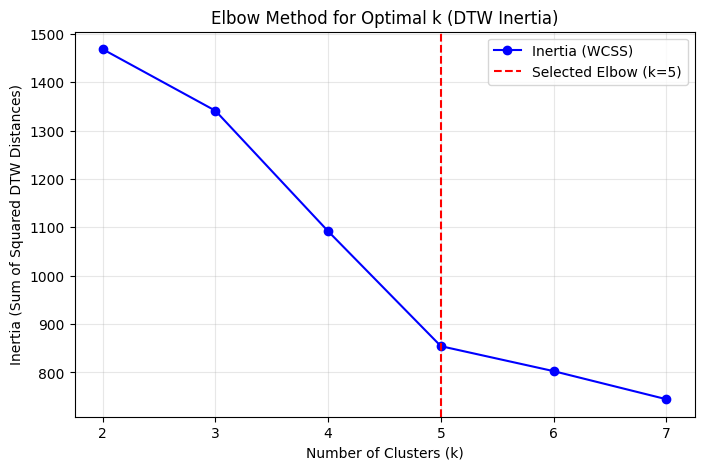

Saving cluster assignments to ../out/mdtw_mvp3_abs_bc_patientid_level/out_db.sqlite -> table 'dtw_mvp3_cluster_labels'...
Database save complete.

Plotting DTW Barycenters...
Saved DTW Barycenters plot to ../out/mdtw_mvp3_abs_bc_patientid_level/dtw_mvp3_barycenters.png


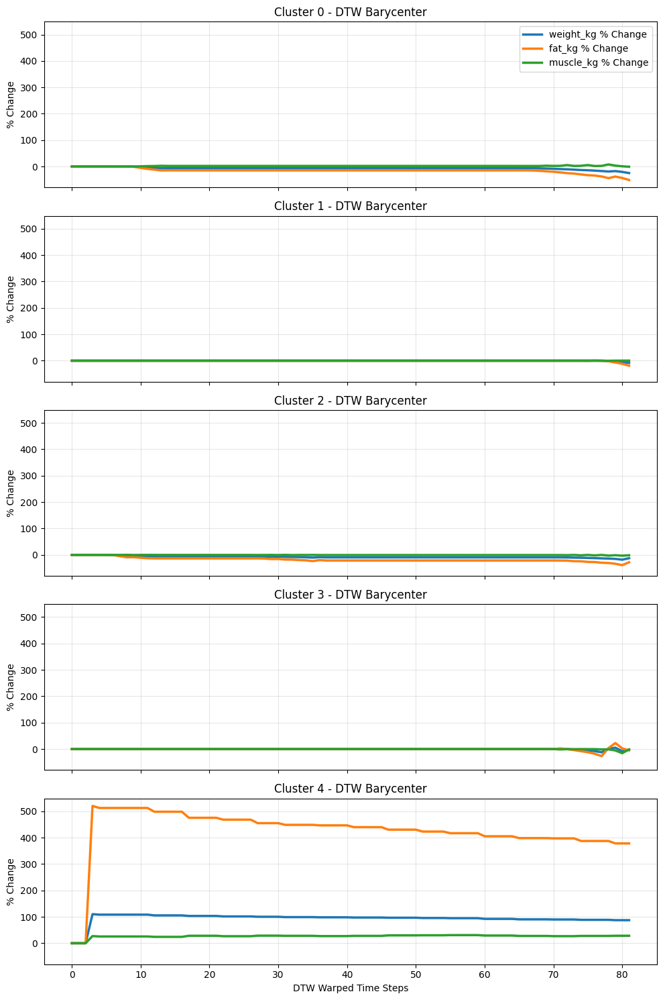


Plotting real-time LOWESS trajectories...
Saved LOWESS plot to ../out/mdtw_mvp3_abs_bc_patientid_level/dtw_mvp3_lowess.png


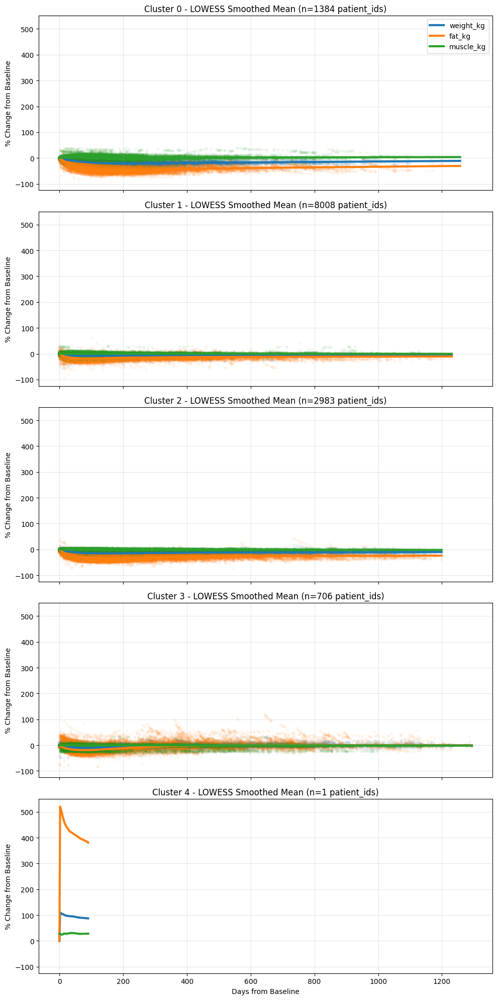

In [3]:
# -------------------------------------------------------------------------
# Dynamic Time Warping with K-means on longitudinal trajectories - MVP3
# -------------------------------------------------------------------------
import os
import sys

# Import our modular pipeline functions
from mdtw_mvp3 import (
    load_and_filter_measurements,
    convert_percentages_to_absolute,
    calculate_days_from_baseline,
    calculate_percentage_from_baseline,
    prepare_tslearn_dataset,
    run_dtw_clustering_search,
    save_clusters_to_db,
    plot_dtw_barycenters,
    plot_lowess_trajectories
)

# -------------------------------------------------------------------------
# 1. CONFIGURATION
# -------------------------------------------------------------------------
DB_PATH = "../dbs/pnk_db2_filtered.sqlite"
OUT_DB_PATH = "../out/mdtw_mvp3_abs_bc_patientid_level/out_db.sqlite"
OUT_TABLE = "dtw_mvp3_cluster_labels"

ID_COL = "patient_id"
# We define the raw columns from the database. The script will automatically 
# convert any % variables into their absolute _kg equivalents.
TARGET_COLS = ["weight_kg", "fat_%", "muscle_%"]
MAX_WEIGHINS = 82

# -------------------------------------------------------------------------
# 2. DATA PREPARATION (Now with absolute body comp conversion)
# -------------------------------------------------------------------------
df_raw = load_and_filter_measurements(
    db_path=DB_PATH, 
    id_col=ID_COL, 
    target_cols=TARGET_COLS, 
    max_weighins=MAX_WEIGHINS
)

# NEW: Convert percentages to absolute values (kg) to prevent artifactual 
# muscle/fat growth signals caused solely by a drop in total body weight.
# Returns updated_targets which will now be ['weight_kg', 'fat_kg', 'muscle_kg']
df_abs, updated_targets = convert_percentages_to_absolute(
    df_raw, 
    target_cols=TARGET_COLS
)

df_time = calculate_days_from_baseline(df_abs, id_col=ID_COL)

# Percentage change from baseline is now calculated on the absolute kg values
df_pct = calculate_percentage_from_baseline(
    df_time, 
    id_col=ID_COL, 
    target_cols=updated_targets
)

ts_dataset, entity_ids = prepare_tslearn_dataset(
    df_pct, 
    id_col=ID_COL, 
    target_cols=updated_targets
)

# -------------------------------------------------------------------------
# 3. MODELING & CLUSTERING 
# -------------------------------------------------------------------------
best_k, best_model, best_labels = run_dtw_clustering_search(
    ts_dataset=ts_dataset, 
    k_min=2, 
    k_max=7, 
    elbow_plot_path="../out/mdtw_mvp3_abs_bc_patientid_level/dtw_mvp3_elbow_curve.png"
)

save_clusters_to_db(
    ids=entity_ids, 
    labels=best_labels, 
    db_path=OUT_DB_PATH, 
    table_name=OUT_TABLE,
    id_col=ID_COL
)

# -------------------------------------------------------------------------
# 4. VISUALIZATION
# -------------------------------------------------------------------------
print("\nPlotting DTW Barycenters...")
plot_dtw_barycenters(
    model=best_model, 
    target_cols=updated_targets, 
    output_path="../out/mdtw_mvp3_abs_bc_patientid_level/dtw_mvp3_barycenters.png"
)

print("\nPlotting real-time LOWESS trajectories...")
plot_lowess_trajectories(
    df=df_pct, 
    ids=entity_ids, 
    labels=best_labels, 
    id_col=ID_COL,
    target_cols=updated_targets,
    output_path="../out/mdtw_mvp3_abs_bc_patientid_level/dtw_mvp3_lowess.png"
)


Annex - runs from memory - clean LOWESS plots. With medical_record_id as the unit, there is a n=1 cluster of a patient whose first weight is a low outlier. Thus, their WL pattern has a huge upwards spike which differs from all the rest. To represent the rest of the more realistic clusters on a cleaned LOWESS plot, this patient is masked from plotting. This can only be done if the clustering pipeline has ran recently and remains in memory. 

Saved LOWESS plot to ../out/dtw_mvp3_cleaned_lowess.png


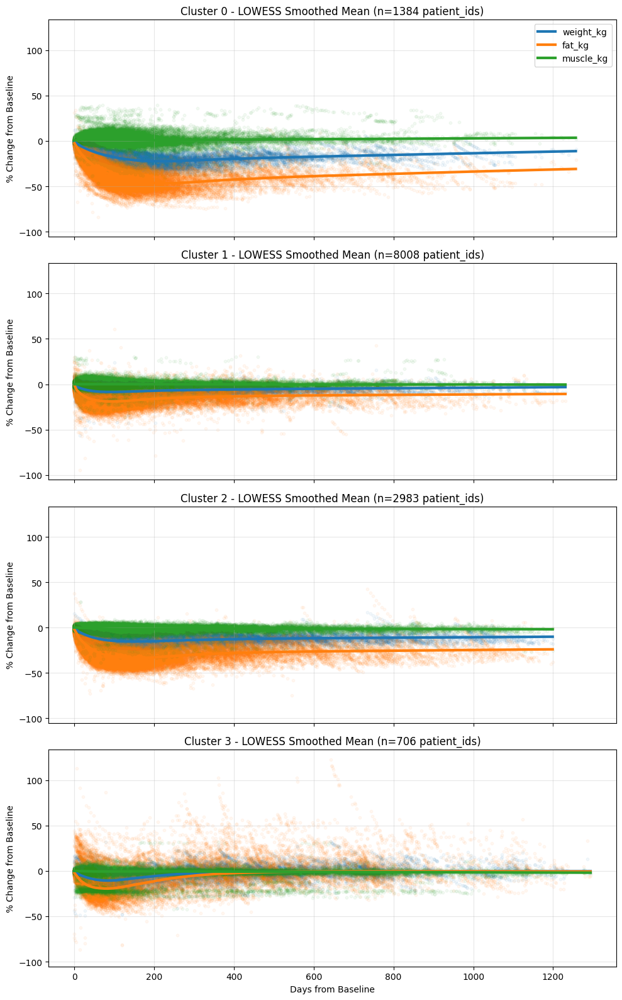

In [7]:
import numpy as np

# 1. Identify valid mask and IDs (excluding Cluster 2)
valid_mask = (best_labels != 4)
valid_ids = np.array(entity_ids)[valid_mask]
valid_labels = best_labels[valid_mask].copy()

# 2. THE FIX: Shift label '3' down to '2' to make them consecutive (0, 1, 2)
valid_labels[valid_labels == 4] = 3

# 3. Filter the long-format dataframe to only include valid entities
valid_clusters_df = df_pct[df_pct[ID_COL].isin(valid_ids)].copy()

# 4. Re-plot the LOWESS curves
plot_lowess_trajectories(
    df=valid_clusters_df, 
    ids=valid_ids.tolist(), 
    labels=valid_labels, 
    id_col=ID_COL,
    target_cols=updated_targets,
    output_path="../out/dtw_mvp3_cleaned_lowess.png"
)

Annex - runs from memory - similar to the LOWESS plots, the barycenter plots are also recreated cleanly, from memory. 

Saved DTW Barycenters plot to ../out/dtw_mvp3_cleaned_barycenters.png


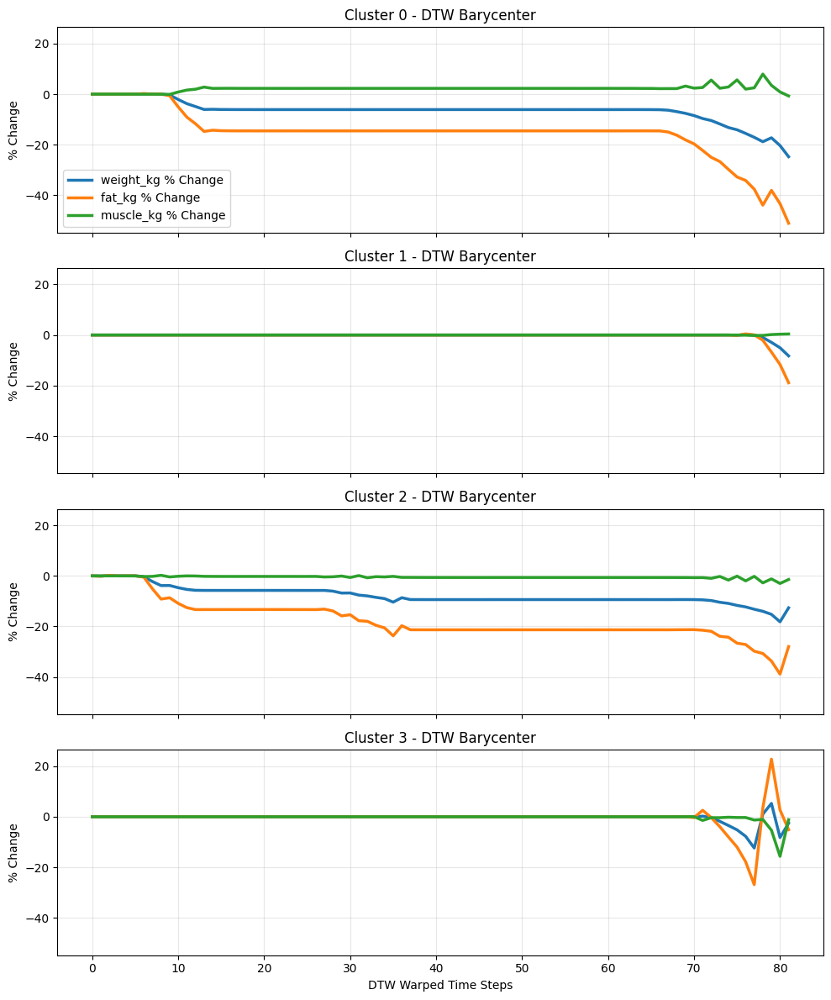

In [10]:
import copy
import numpy as np

# 1. Create a copy of the model so we don't alter the original saved object
cleaned_model = copy.deepcopy(best_model)

# 2. Delete the quarantine cluster's barycenter (index 2) from the centers array
# The shape is (k, max_timepoints, n_targets). axis=0 deletes the 3rd cluster matrix.
cleaned_model.cluster_centers_ = np.delete(cleaned_model.cluster_centers_, 4, axis=0)

# 3. Update the model's internal cluster count from 4 to 3
cleaned_model.n_clusters = 4

# 4. Re-plot using your existing function
plot_dtw_barycenters(
    model=cleaned_model, 
    target_cols=updated_targets, 
    output_path="../out/dtw_mvp3_cleaned_barycenters.png"
)

#### MVP2, 21Sept26 - Configurable whole patient trajectory vs medical record level clustering

##### details

GOAL
- to identify weight loss and body composition change trajectory clusters

DATAPREP
- configurable choice within whole patient trajectories and unique treatment episodes (unit of analysis determined by patient_id or medical_record_id respectively)
- configurable choice of input variables - ideally, weight, muscle, and fat, to balance detail with dimensionality
- instant dropouts with only 1 weigh-in excluded - dtw needs serial data - but clinically, they constitute the 0th cluster that should be characterized
- patients with missing BC excluded - dtw needs complete data - missing data would need imputation if we want to use all
- ! most adherent patients excluded: patients more than a given number (ideally the 95th percentile, or a lower number like 50) weigh-ins excluded from this MVP run, because it slows down early iteration - but these patients are valuable, the top 10% of patients have an average of 107 weigh-ins, and the top has 752
- tensor formatting: uneven patient histories are zero-padded with NaNs and pivoted into a 3D tensor (this is standard for DTW as far as I understand)

ML ARCHITECTURE
- algorithm: TimeSeriesKMeans with dynamic time warping. DTW aligns sequence shapes elastically, neutralizing irregular gaps between weigh-ins. It natively ignores NaN padding. K-means might not be the best algorithm choice though, so in further iterations, PAM, k-series, hclust, or mLCGA with FDA-based approaches should be explored
- k selection: by default, k 2-7 evaluated, best k selected with the elbow method (inertia) to keep computational costs low. In more serious builds, a comprehensive evaluation with inertia, silhouette, CHI, DBI, maybe even ARI should be considered. 

VISUALIZATION
- model-derived: DTW barycenters / raw mathematical cluster centers plotted around warped time steps to emphasize the model-derived SHAPE of the weight loss response
- raw, LOWESS-smoothed: per cluster, raw change trajectories are plotted, to see if clusters actually look coherent in real life, or only their warped trajectory shape

##### code

c:\Users\miksa.henkrich\OneDrive - IMDEANU\Escritorio\PNK\p4_dir\.venv\Lib\site-packages\tslearn\bases\bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


Loading data from ../dbs/pnk_db2_filtered.sqlite...
Initial data: 396210 rows, 18078 unique medical_record_ids.
After dropping missing values in targets: 360306 rows.
After enforcing >=2 timepoints: 359266 rows, 16710 unique medical_record_ids remaining.
95th percentile of weigh-ins per medical_record_id: 68.0
Max weigh-ins per medical_record_id: 749
After capping at 68 timepoints: 263271 rows, 15891 unique medical_record_ids.
Calculating days from baseline for time axis using medical_record_id...
Calculating percentage change from baseline...
Reshaping data for tslearn...
Dataset reshaped successfully. Shape: (15891, 68, 3)
Starting DTW KMeans search for k in range 2-7...

--- Fitting k=2 ---
k=2 | Inertia: 1289.30

--- Fitting k=3 ---
k=3 | Inertia: 673.84

--- Fitting k=4 ---
k=4 | Inertia: 562.84

--- Fitting k=5 ---
k=5 | Inertia: 528.75

--- Fitting k=6 ---
k=6 | Inertia: 448.70

--- Fitting k=7 ---
k=7 | Inertia: 407.56

=> Best k selected via Elbow Method: 3 (Inertia: 673.84)
G

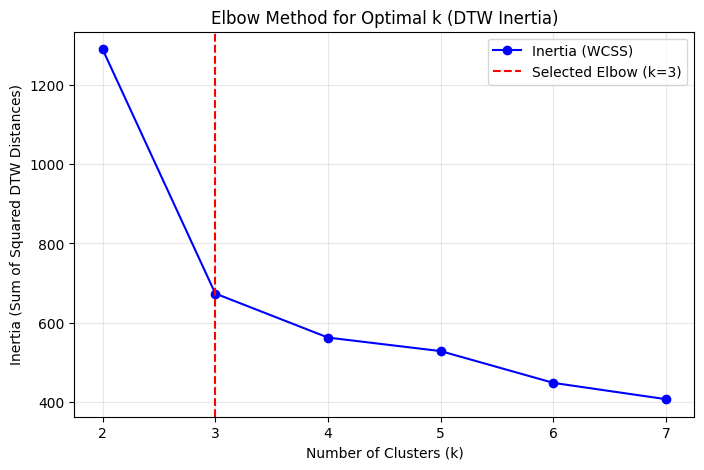

Saving cluster assignments to ../out/out_db.sqlite -> table 'dtw_mvp2_cluster_labels'...
Database save complete.

Plotting DTW Barycenters...
Saved DTW Barycenters plot to ../out/dtw_mvp2_barycenters.png


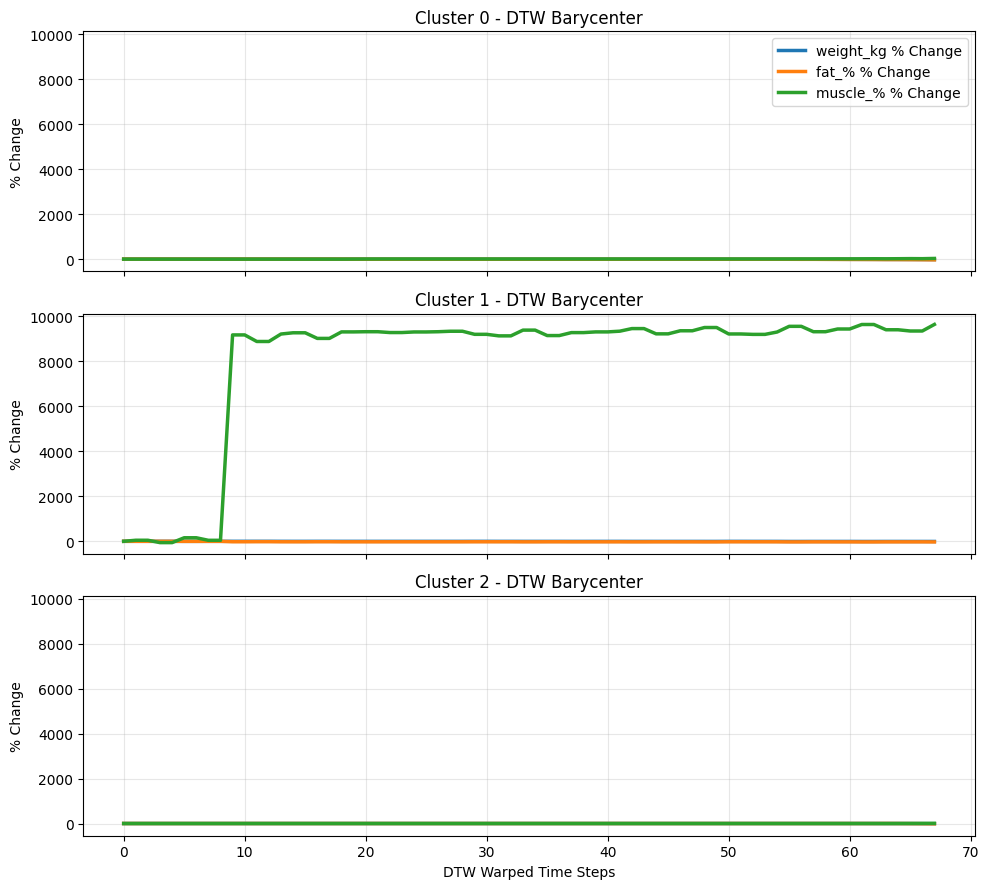


Plotting real-time LOWESS trajectories...
Saved LOWESS plot to ../out/dtw_mvp2_lowess.png


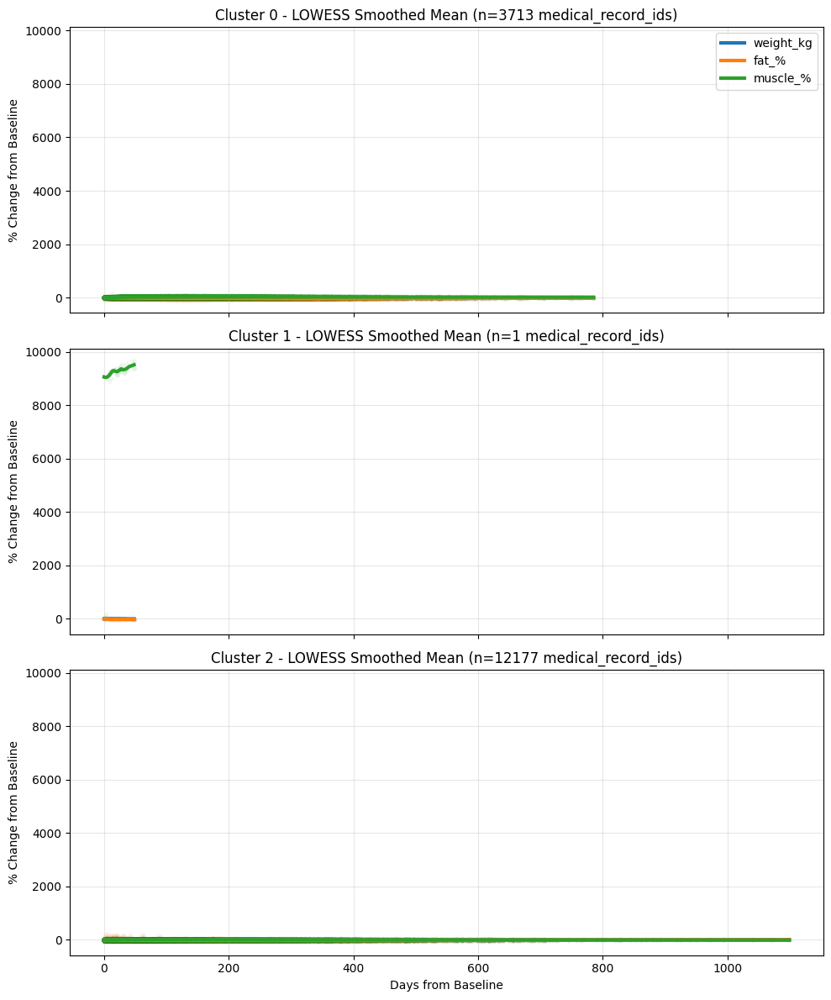

In [1]:
# -------------------------------------------------------------------------
# Dynamic Time Warping with K-means on longitudinal trajectories - MVP2
# -------------------------------------------------------------------------
import os
import sys

# Import our modular pipeline functions
from mdtw_mvp2 import (
    load_and_filter_measurements,
    calculate_days_from_baseline,
    calculate_percentage_from_baseline,
    prepare_tslearn_dataset,
    run_dtw_clustering_search,
    save_clusters_to_db,
    plot_dtw_barycenters,
    plot_lowess_trajectories
)

# -------------------------------------------------------------------------
# 1. CONFIGURATION
# -------------------------------------------------------------------------
# Define paths
DB_PATH = "../dbs/pnk_db2_filtered.sqlite"
OUT_DB_PATH = "../out/out_db.sqlite"
OUT_TABLE = "dtw_mvp2_cluster_labels"

# Configuration variables for the analysis:
# id_col: 'medical_record_id' focuses the analysis on individual treatment 
#         episodes rather than the whole patient history ('patient_id'), 
#         preventing long gaps between distinct treatments from distorting DTW.
ID_COL = "medical_record_id"

# target_cols: The variables we want to cluster on to find distinct weight loss responses.
TARGET_COLS = ["weight_kg", "fat_%", "muscle_%"]

# max_weighins: Excludes extreme outliers (e.g., highly adherent patients with >50 visits)
#               for this MVP run, as DTW is computationally heavy (O(N^2)). 
MAX_WEIGHINS = 68

# -------------------------------------------------------------------------
# 2. DATA PREPARATION
# -------------------------------------------------------------------------
# Load data and apply biological/quality constraints (no missing data, >=2 timepoints)
df_raw = load_and_filter_measurements(
    db_path=DB_PATH, 
    id_col=ID_COL, 
    target_cols=TARGET_COLS, 
    max_weighins=MAX_WEIGHINS
)

# Calculate a continuous time axis (days from baseline) for later visualization
df_time = calculate_days_from_baseline(df_raw, id_col=ID_COL)

# Convert raw measurements into percentage change from the first visit 
# (baseline) to standardize the trajectories for shape-based clustering.
df_pct = calculate_percentage_from_baseline(
    df_time, 
    id_col=ID_COL, 
    target_cols=TARGET_COLS
)

# Reshape the longitudinal dataframe into a 3D tensor (entities x time x features)
# This format is required by tslearn. Uneven histories are automatically zero-padded.
ts_dataset, entity_ids = prepare_tslearn_dataset(
    df_pct, 
    id_col=ID_COL, 
    target_cols=TARGET_COLS
)

# -------------------------------------------------------------------------
# 3. MODELING & CLUSTERING (Updated for Inertia / Elbow Method)
# -------------------------------------------------------------------------
# Iterate through k=2 to k=7 to find the optimal number of clusters using DTW-KMeans.
# Evaluation is done via Inertia (WCSS), detecting the elbow point automatically.
best_k, best_model, best_labels = run_dtw_clustering_search(
    ts_dataset=ts_dataset, 
    k_min=2, 
    k_max=7, 
    elbow_plot_path="../out/dtw_mvp2_elbow_curve.png"  # <--- New configurable path
)

# Save the resulting cluster labels back to our output database for downstream analysis
save_clusters_to_db(
    ids=entity_ids, 
    labels=best_labels, 
    db_path=OUT_DB_PATH, 
    table_name=OUT_TABLE,
    id_col=ID_COL
)

# -------------------------------------------------------------------------
# 4. VISUALIZATION
# -------------------------------------------------------------------------
# Plot the mathematical cluster centers (Barycenters) to see the DTW-derived "shape"
print("\nPlotting DTW Barycenters...")
plot_dtw_barycenters(
    model=best_model, 
    target_cols=TARGET_COLS, 
    output_path="../out/dtw_mvp2_barycenters.png"
)

# Plot the raw, real-time trajectories smoothed by LOWESS to ensure the 
# mathematical clusters align with clinically coherent real-life patterns.
print("\nPlotting real-time LOWESS trajectories...")
plot_lowess_trajectories(
    df=df_pct, 
    ids=entity_ids, 
    labels=best_labels, 
    id_col=ID_COL,
    target_cols=TARGET_COLS,
    output_path="../out/dtw_mvp2_lowess.png"
)


#### MVP1, 17Sept26 - Dynamic time warping with K-means on whole patient trajectory weight and BC data

##### details

GOAL
- to identify weight loss and body composition change trajectory clusters

DATAPREP
- whole patient trajectories used (unit of analysis determined by patient_id)
- instant dropouts excluded - dtw needs serial data - but clinically, they constitute the 0th cluster that should be characterized
- patients with missing BC excluded - dtw needs complete data - missing data would need imputation if we want to use all
- ! most adherent patients excluded: patients with over 50 weigh-ins excluded from the first run, because it slows down early iteration - but these patients are valuable, the top 10% of patients have an average of 107 weigh-ins, and the top has 752
- tensor formatting: uneven patient histories are zero-padded with NaNs and pivoted into a 3D tensor

ML ARCHITECTURE
- algorithm: TimeSeriesKMeans with dynamic time warping. DTW aligns sequence shapes elastically, neutralizing irregular gaps between weigh-ins. It natively ignores NaN padding. 
- k selection: k 2-7 evaluated, best selected with a silhouette score only. But, silhouette evaluation is executed on a random subsample of n max = 1000 per cluster, because it would take too much time on the 14-15k samples

VISUALIZATION
- model-derived: DTW barycenters / raw mathematical cluster centers plotted around warped time steps to emphasize the model-derived SHAPE of the weight loss response
- raw, LOWESS-smoothed: per cluster, raw change trajectories are plotted, to see if clusters actually look coherent in real life, or only their warped trajectory shape

##### code

c:\Users\miksa.henkrich\OneDrive - IMDEANU\Escritorio\PNK\p4_dir\.venv\Lib\site-packages\tslearn\bases\bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


Loading data from C:/Users/miksa.henkrich/OneDrive - IMDEANU/Escritorio/PNK/p4_dir/dbs/pnk_db2_filtered.sqlite...
Initial data: 396210 rows, 14515 patients.
After dropping missing values: 360306 rows.
After enforcing >=2 timepoints: 359638 rows, 13770 patients remaining.
After capping at 50 timepoints: 202865 rows, 12150 patients.
Calculating days from baseline for time axis...
Calculating percentage change from baseline...
Reshaping data for tslearn...
Dataset reshaped successfully. Shape: (12150, 50, 3)
Starting DTW KMeans search for k in range 2-7...

--- Fitting k=2 ---
Computing silhouette score on subset of 2000 trajectories...
k=2 | Silhouette Score: 0.4892

--- Fitting k=3 ---
Computing silhouette score on subset of 3000 trajectories...
k=3 | Silhouette Score: 0.3749

--- Fitting k=4 ---
Computing silhouette score on subset of 3358 trajectories...
k=4 | Silhouette Score: 0.3123

--- Fitting k=5 ---
Computing silhouette score on subset of 3753 trajectories...
k=5 | Silhouette Sc

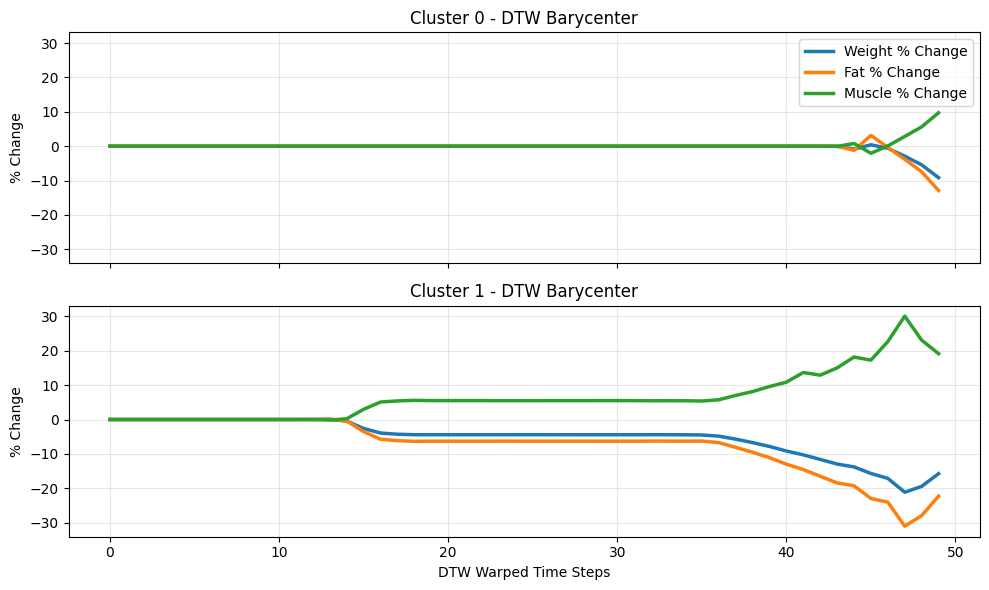

Saved LOWESS plot to C:/Users/miksa.henkrich/OneDrive - IMDEANU/Escritorio/PNK/p4_dir/out/lowess_trajectories.png


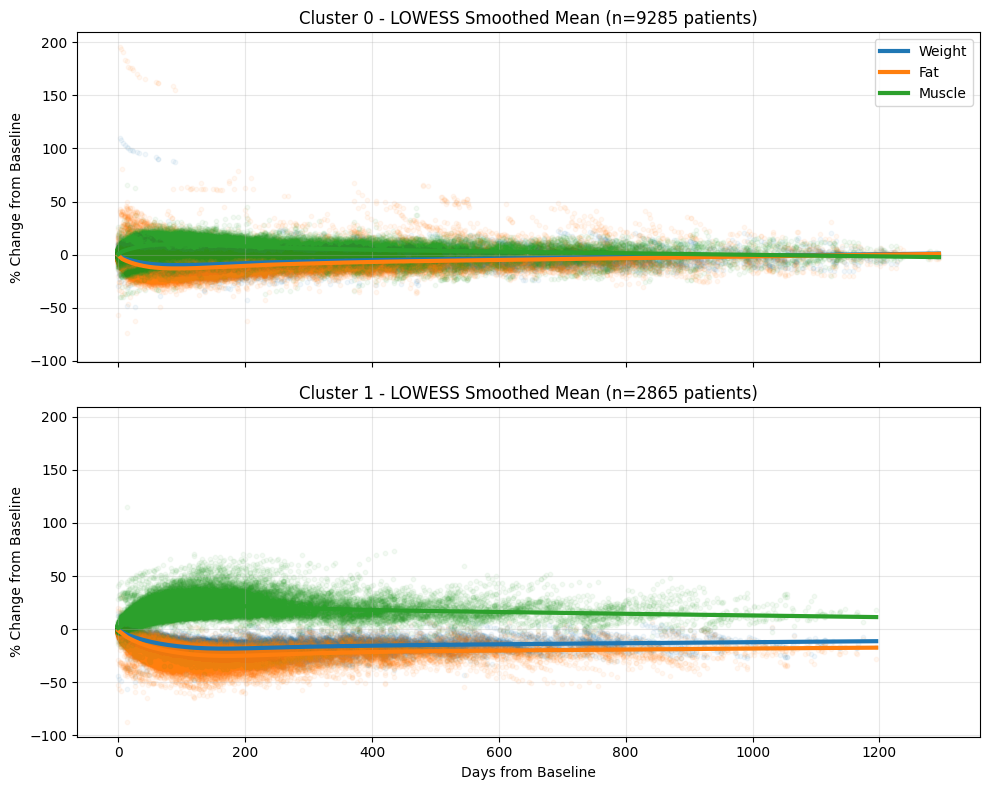

In [1]:
import sys
# Ensure the scripts directory is in path so we can import the module
sys.path.append('scripts')
import mdtw_mvp1

# ==========================================
# 1. CONFIGURATION
# ==========================================
SOURCE_DB_PATH = "C:/Users/miksa.henkrich/OneDrive - IMDEANU/Escritorio/PNK/p4_dir/dbs/pnk_db2_filtered.sqlite"
OUTPUT_DB_PATH = "C:/Users/miksa.henkrich/OneDrive - IMDEANU/Escritorio/PNK/p4_dir/out/out_db.sqlite"
OUTPUT_TABLE_NAME = "dtw_mvp1_cluster_labels"

BARYCENTER_PLOT_PATH = "C:/Users/miksa.henkrich/OneDrive - IMDEANU/Escritorio/PNK/p4_dir/out/dtw_barycenters.png"
LOWESS_PLOT_PATH = "C:/Users/miksa.henkrich/OneDrive - IMDEANU/Escritorio/PNK/p4_dir/out/lowess_trajectories.png"

# ==========================================
# 2. DATA PREPARATION
# ==========================================
# Load and filter missing or insufficient trajectories
df_clean = mdtw_mvp1.load_and_filter_measurements(SOURCE_DB_PATH)

# Calculate elapsed time (days) for Lowess X-axis
df_clean = mdtw_mvp1.calculate_days_from_baseline(df_clean)

# Calculate Percentage Change from Baseline (Y-axis)
df_norm = mdtw_mvp1.calculate_percentage_from_baseline(df_clean)

# Pivot to tslearn 3D NumPy array
ts_dataset, patient_ids = mdtw_mvp1.prepare_tslearn_dataset(df_norm)

# ==========================================
# 3. DTW CLUSTERING (k=2 to 7)
# ==========================================
# Run silhouette search. n_max_silhouette=1000 bounds the computational 
# cost of DTW distances during evaluation.
best_k, best_model, best_labels = mdtw_mvp1.run_dtw_clustering_search(
    ts_dataset, 
    k_min=2, 
    k_max=7, 
    n_max_silhouette=1000
)

# Save the winning assignments to a new table/database
mdtw_mvp1.save_clusters_to_db(patient_ids, best_labels, OUTPUT_DB_PATH, OUTPUT_TABLE_NAME)

# ==========================================
# 4. VISUALIZATIONS
# ==========================================
# Plot 1: DTW Mathematical Barycenters
mdtw_mvp1.plot_dtw_barycenters(best_model, output_path=BARYCENTER_PLOT_PATH)

# Plot 2: LOWESS Smoothed Mean Trajectories
mdtw_mvp1.plot_lowess_trajectories(df_norm, patient_ids, best_labels, output_path=LOWESS_PLOT_PATH)
